# Template 07: SHAP Analysis

**Purpose:** Generate residual + SHAP range plots for top features

**Inputs:**
- results/06_shap_train.parquet
- results/06_shap_test.parquet
- results/05c_predictions_train.parquet
- results/05c_predictions_test.parquet
- data/04c_train_encoded.parquet
- data/04c_test_encoded.parquet

**Outputs:**
- plots/{dataset}_{feature}_residual.png
- plots/{dataset}_{feature}_shap_range.png
- results/07_analysis_summary.yaml

In [1]:
config_path = "config/car_coll/v1"

In [2]:
# Parameters
config_path = "config/car_liab/v1"


In [3]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import yaml
import os
import sys
from pathlib import Path
from datetime import datetime

sys.path.insert(0, str(Path.cwd() / 'lib'))
from utils import setup_notebook_environment
from shap_utils import compute_shap_aggregate, create_residual_plot, create_shap_range_plot, create_fast_shap_summary, create_shap_beeswarm, create_shap_importance_pct
from IPython.display import Image, display

print("########################################")
print("# STAGE 07: SHAP ANALYSIS")
print("########################################")

project_root = setup_notebook_environment()

# Note: SHAP interpretation depends on target_method
# - residual: SHAP values show impact on ratio (PP/GLM correction factor)
# - direct: SHAP values show impact on PP directly

########################################
# STAGE 07: SHAP ANALYSIS
########################################


In [4]:
# Get machine config
pc_num = open("current.pc").read().strip()
pc_id = f"PC{pc_num}"

with open(f"{config_path}/config.yaml") as f:
    cfg = yaml.safe_load(f)
output_base = cfg["machines"][pc_id]["paths"]["output_path"]
shap_cfg = cfg.get("shap_analysis", {})
top_n = shap_cfg.get("top_n_features", 40)
datasets = shap_cfg.get("datasets", ["train", "test"])
resid_cfg = shap_cfg.get("residual_plot", {})
shap_range_cfg = shap_cfg.get("shap_range_plot", {})
print(f"\nConfig: top_n={top_n}")


Config: top_n=40


In [5]:
plots_dir = f"{output_base}/plots"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots: {plots_dir}")

Plots: output/car_liab/v1/plots


In [6]:
# Load ENCODED data (same data used for SHAP computation)
df_train = pd.read_parquet(f"{output_base}/data/04c_train_encoded.parquet")
df_test = pd.read_parquet(f"{output_base}/data/04c_test_encoded.parquet")

print(f"\n* Train encoded: {df_train.shape}")
print(f"* Test encoded: {df_test.shape}")


* Train encoded: (4550028, 151)
* Test encoded: (4539000, 151)


In [7]:
print("\nLoading...")
shap_train = pd.read_parquet(f"{output_base}/results/06_shap_train.parquet")
shap_test = pd.read_parquet(f"{output_base}/results/06_shap_test.parquet")
preds_train = pd.read_parquet(f"{output_base}/results/05c_predictions_train.parquet")
preds_test = pd.read_parquet(f"{output_base}/results/05c_predictions_test.parquet")

print(f"  SHAP train: {shap_train.shape}")
print(f"  SHAP test: {shap_test.shape}")
print(f"  Preds train: {preds_train.shape}")
print(f"  Preds test: {preds_test.shape}")


Loading...


  SHAP train: (10000, 152)
  SHAP test: (4539000, 152)
  Preds train: (4307292, 3)
  Preds test: (4295155, 3)


In [8]:
# Merge train data with predictions
# Use intersection of indices (SHAP is computed on sample)
common_idx = shap_train.index.intersection(preds_train.index)
data_tr = df_train.loc[common_idx].copy()
data_tr['actual'] = preds_train.loc[common_idx, 'actual']
data_tr['pred'] = preds_train.loc[common_idx, 'pred']
data_tr['weight'] = preds_train.loc[common_idx, 'exposure']

fc_tr = shap_train.loc[common_idx].copy()
fc_tr['weight'] = data_tr['weight']
out_tr = data_tr
print(f"Train: {out_tr.shape}")

Train: (9479, 154)


In [9]:
# Merge test data with predictions
# Use intersection of indices
common_idx = shap_test.index.intersection(preds_test.index)
data_te = df_test.loc[common_idx].copy()
data_te['actual'] = preds_test.loc[common_idx, 'actual']
data_te['pred'] = preds_test.loc[common_idx, 'pred']
data_te['weight'] = preds_test.loc[common_idx, 'exposure']

fc_te = shap_test.loc[common_idx].copy()
fc_te['weight'] = data_te['weight']
out_te = data_te
print(f"Test: {out_te.shape}")

Test: (4295155, 154)


In [10]:
print("\nSHAP aggregates...")
shagg, shagg_num, shagg2 = compute_shap_aggregate(fc_tr, weight_col="weight")
print(f"Features: {len(shagg2)}")
print(shagg2.head(10))


SHAP aggregates...
Features: 109
                                     field  total_shap
5                  cef_first_poten_dam_ind  753.403531
2                 cef_est_curr_mi_grp_imps  399.539592
89                            vc_msrp_impa  292.466929
55                            vc_doors_raw  241.368853
7                      cef_lien_holder_ind  231.242580
6                   cef_first_sev_prob_ind  175.780430
29   vc_auto_dimming_rearview_mirror_raw_0  175.397731
120                     vc_luxury_flag_ind  147.135388
57                   vc_drive_type_fwd_ind  132.819922
33        vc_auto_dimming_side_mirrors_raw  123.558721


In [11]:
features = shagg2["field"].head(top_n).tolist()
print(f"\nPlotting {len(features)} features")


Plotting 40 features



SHAP BEESWARM PLOT
Note: Each dot = record. Color shows feature value (red=high, blue=low)
X-axis shows SHAP value impact on prediction


  Creating SHAP beeswarm for 9,479 samples...


  Beeswarm created with 40 features


Saved: output/car_liab/v1/plots/shap_beeswarm.png


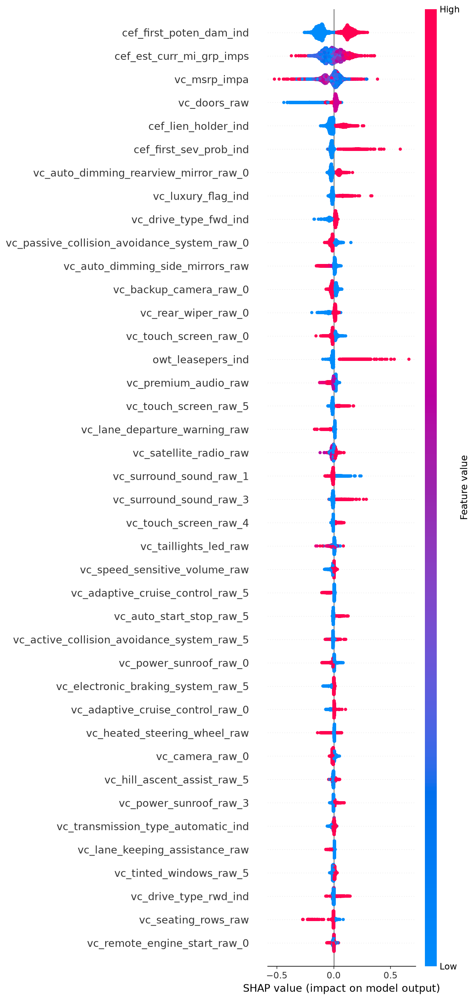

In [12]:
# SHAP Beeswarm Plot (standard - shows feature value impact)
print(f"\n{'='*60}")
print("SHAP BEESWARM PLOT")
print('='*60)
print("Note: Each dot = record. Color shows feature value (red=high, blue=low)")
print("X-axis shows SHAP value impact on prediction")
fig_beeswarm = create_shap_beeswarm(fc_tr, data_tr, top_n=top_n, weight_col='weight', max_display=top_n)
if fig_beeswarm:
    beeswarm_file = f'{plots_dir}/shap_beeswarm.png'
    fig_beeswarm.savefig(beeswarm_file, dpi=150, bbox_inches='tight')
    plt.close(fig_beeswarm)
    print(f"Saved: {beeswarm_file}")
    display(Image(beeswarm_file))
else:
    print("Warning: Could not create SHAP beeswarm plot")



SHAP FEATURE IMPORTANCE (%)
  Creating SHAP importance % chart for 9,479 rows...
  SHAP importance % chart created


Saved: output/car_liab/v1/plots/shap_importance_pct.png


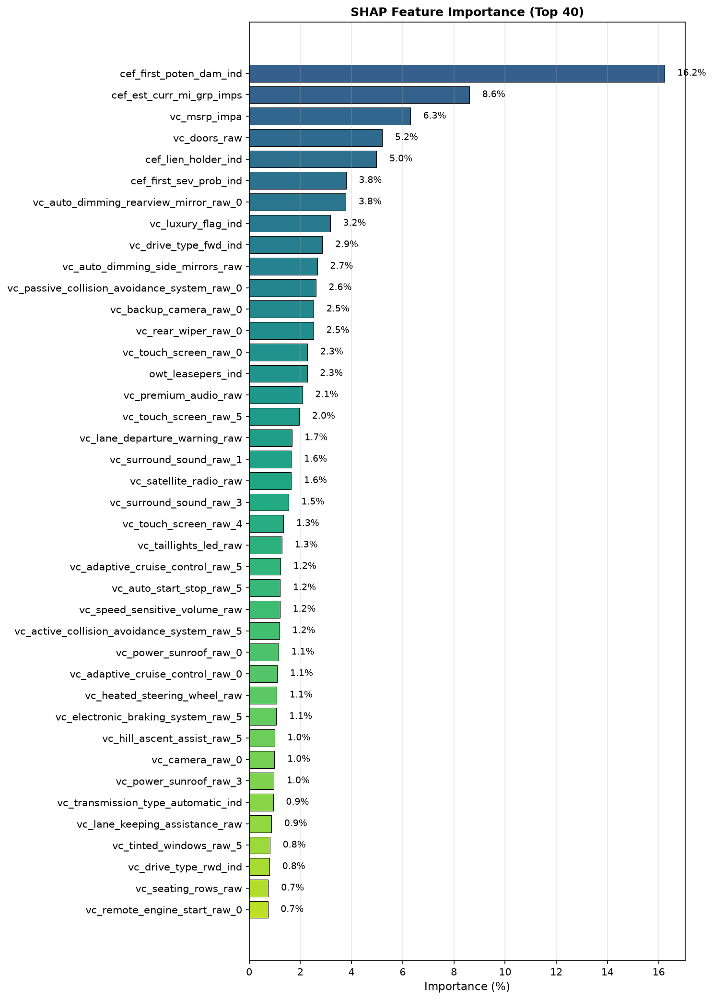

In [13]:
# SHAP Feature Importance (Percentage)
print(f"\n{'='*60}")
print("SHAP FEATURE IMPORTANCE (%)")
print('='*60)
fig_importance = create_shap_importance_pct(fc_tr, top_n=top_n, weight_col='weight')
if fig_importance:
    importance_file = f'{plots_dir}/shap_importance_pct.png'
    fig_importance.savefig(importance_file, dpi=150, bbox_inches='tight')
    plt.close(fig_importance)
    print(f"Saved: {importance_file}")
    display(Image(importance_file))
else:
    print("Warning: Could not create SHAP importance plot")


In [14]:
summary = {"timestamp": datetime.now().isoformat(), "plots": 0}
plots_by_feature = {}

In [15]:
print("="*60)
print("GENERATING PLOTS")
print("="*60)
for i, f in enumerate(features, 1):
    print(f"[{i}/{len(features)}] {f}")
    plots_by_feature[f] = []
    if f not in out_tr.columns or f not in out_te.columns:
        print(f"  WARNING: Feature {f} not found, skipping")
        continue
    if "train" in datasets:
        try:
            fig, _ = create_residual_plot(out_tr, f, "weight", dataset_label="Train", **resid_cfg)
            path = f"{plots_dir}/train_{f}_residual.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Train Residual): {e}")
        try:
            fig, _ = create_shap_range_plot(fc_tr, data_tr, f, "weight", dataset_label="Train", **shap_range_cfg)
            path = f"{plots_dir}/train_{f}_shap_range.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Train SHAP): {e}")
    if "test" in datasets:
        try:
            fig, _ = create_residual_plot(out_te, f, "weight", dataset_label="Test", **resid_cfg)
            path = f"{plots_dir}/test_{f}_residual.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Test Residual): {e}")
        try:
            fig, _ = create_shap_range_plot(fc_te, data_te, f, "weight", dataset_label="Test", **shap_range_cfg)
            path = f"{plots_dir}/test_{f}_shap_range.png"
            fig.savefig(path, dpi=100, bbox_inches="tight")
            plt.close(fig)
            plots_by_feature[f].append(path)
            summary["plots"] += 1
        except Exception as e:
            print(f"  ERROR (Test SHAP): {e}")
print(f"\n[OK] Generated summary")

GENERATING PLOTS
[1/40] cef_first_poten_dam_ind

cef_first_poten_dam_ind Summary:
 cef_first_poten_dam_ind      weight   act_rate  pred_rate
                     0.0 3388.413628 223.041755 172.618893
                     1.0 2518.855847  41.783006 268.845428


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


cef_first_poten_dam_ind Summary:
 cef_first_poten_dam_ind       weight   act_rate  pred_rate
                     0.0 1.540147e+06 248.388140 169.694638
                     1.0 1.136186e+06 435.824665 274.403461


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 

[2/40] cef_est_curr_mi_grp_imps

cef_est_curr_mi_grp_imps Summary:
cef_est_curr_mi_grp_imps     weight   act_rate  pred_rate
     (6401.999, 20460.8] 450.287576 888.285056 181.044966
      (20460.8, 31287.2] 315.971489   3.796025 171.266840
      (31287.2, 40196.2] 386.663714  76.954298 178.105110
      (40196.2, 48458.0] 369.964057   0.000000 138.843019
      (48458.0, 55230.0] 478.618511 609.094143 196.000509
      (55230.0, 60125.4] 470.388410  35.681629 192.534472
      (60125.4, 69234.4] 315.376194  48.296131 158.692385
      (69234.4, 84984.0] 524.657055  42.283365 230.876474
      (84984.0, 99629.6] 435.102061   5.742554 225.282131
     (99629.6, 110000.0] 553.698317   0.000000 240.177950
    (110000.0, 120121.2] 303.888194  19.962153 216.722736
    (120121.2, 132000.0] 473.941392 154.734197 183.159932
    (132000.0, 163000.0] 374.595506   0.000000 308.010286
    (163000.0, 194000.0] 231.762549  10.532426 326.572650
    (194000.0, 225000.0] 122.444877   0.000000 371.473739
    (

...

[40/40] vc_remote_engine_start_raw_0

vc_remote_engine_start_raw_0 Summary:
 vc_remote_engine_start_raw_0      weight   act_rate  pred_rate
                          0.0 2693.883761 151.469074 211.299327
                          1.0 3213.385713 140.961295 215.620322


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


vc_remote_engine_start_raw_0 Summary:
 vc_remote_engine_start_raw_0       weight   act_rate  pred_rate
                          0.0 1.208761e+06 331.807317 213.916865
                          1.0 1.467572e+06 324.792519 214.336131


/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  c['SHAP'].fillna(lowest_contrib, inplace=True)
/Users/Mach/dev/aps/code/26Dmodelv1/lib/shap_utils.py:156: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace 


[OK] Generated summary



DISPLAYING ALL PLOTS

FEATURE: cef_first_poten_dam_ind


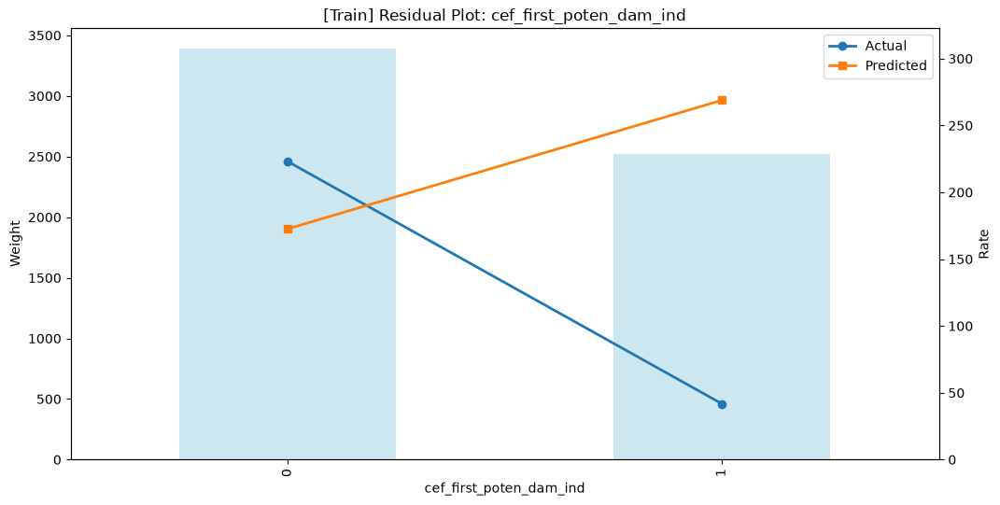

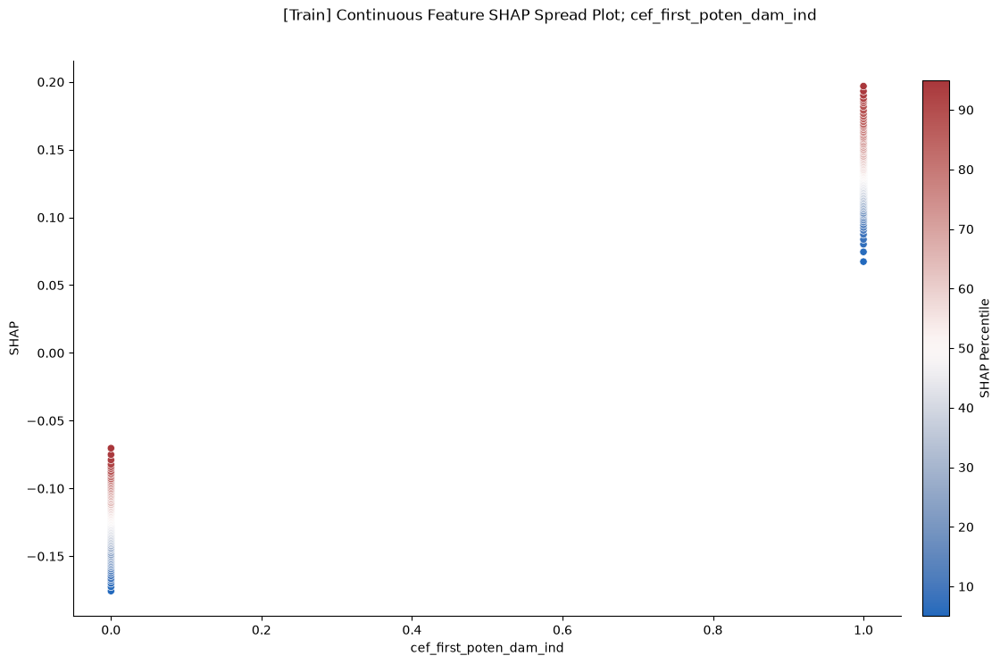

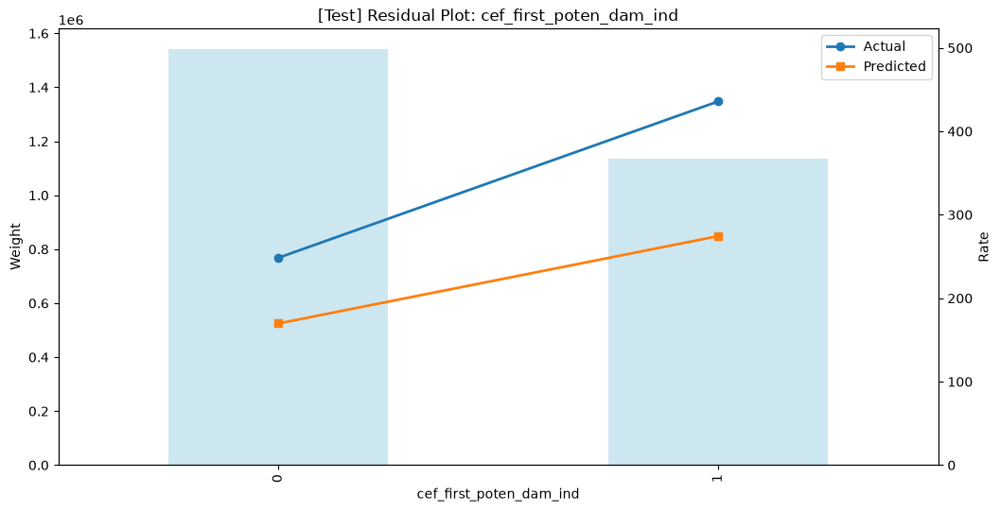

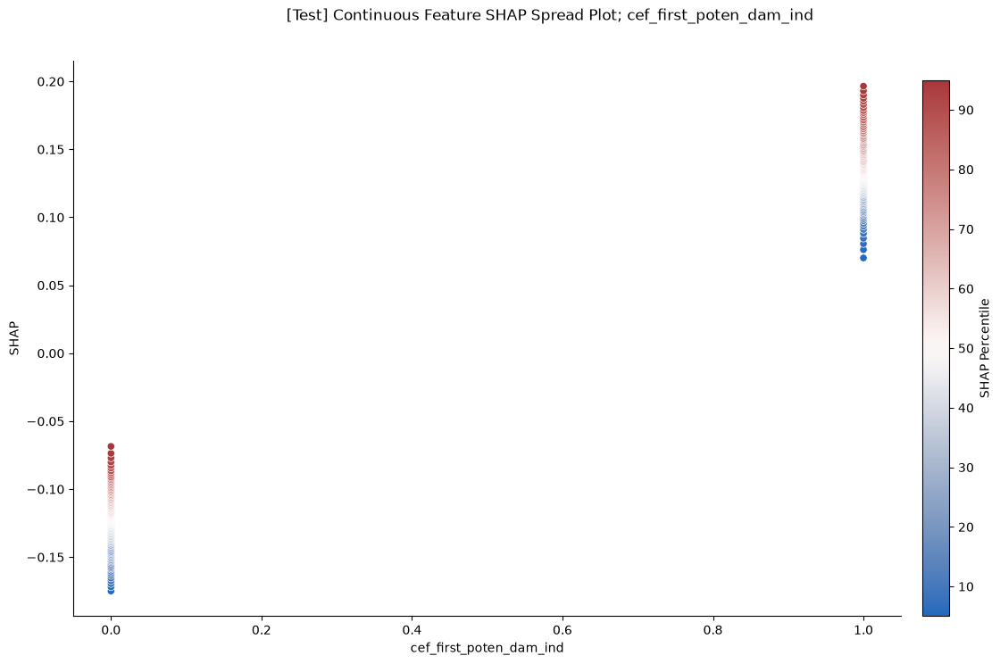


FEATURE: cef_est_curr_mi_grp_imps


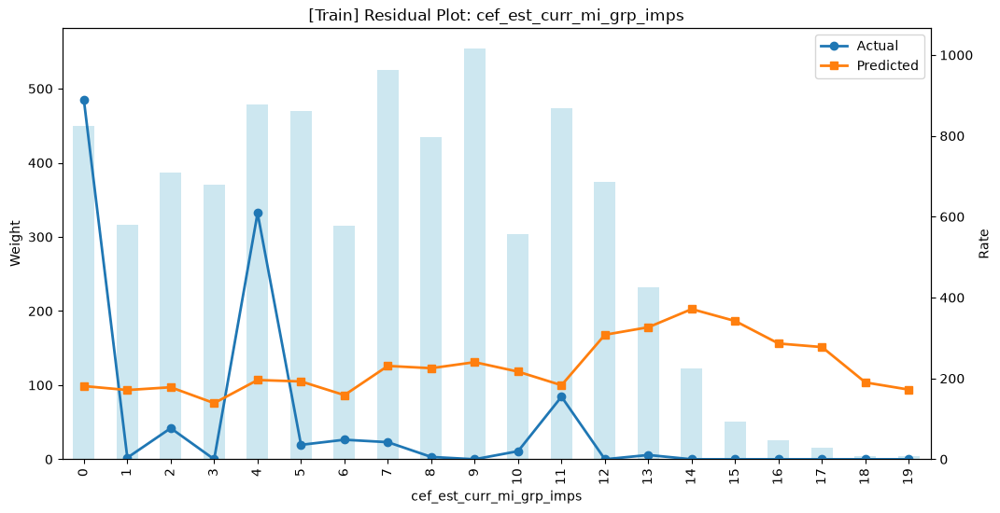

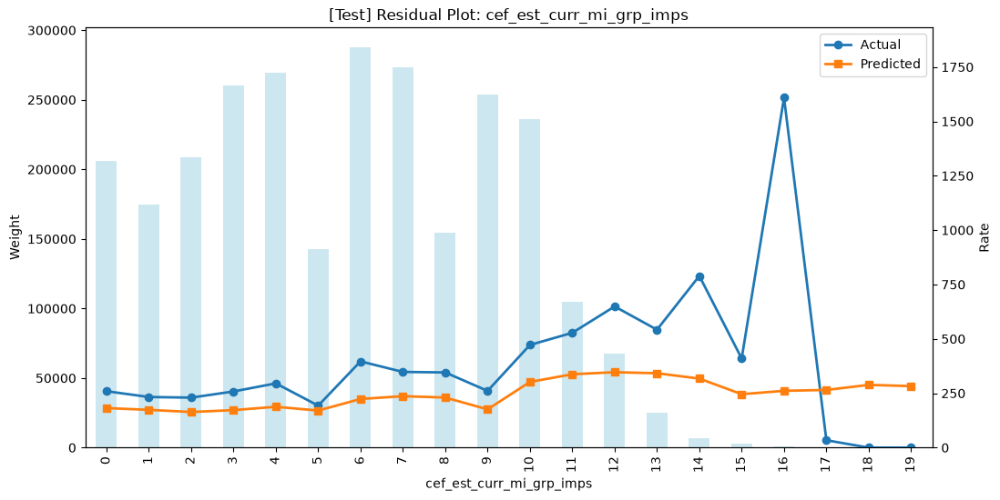


FEATURE: vc_msrp_impa


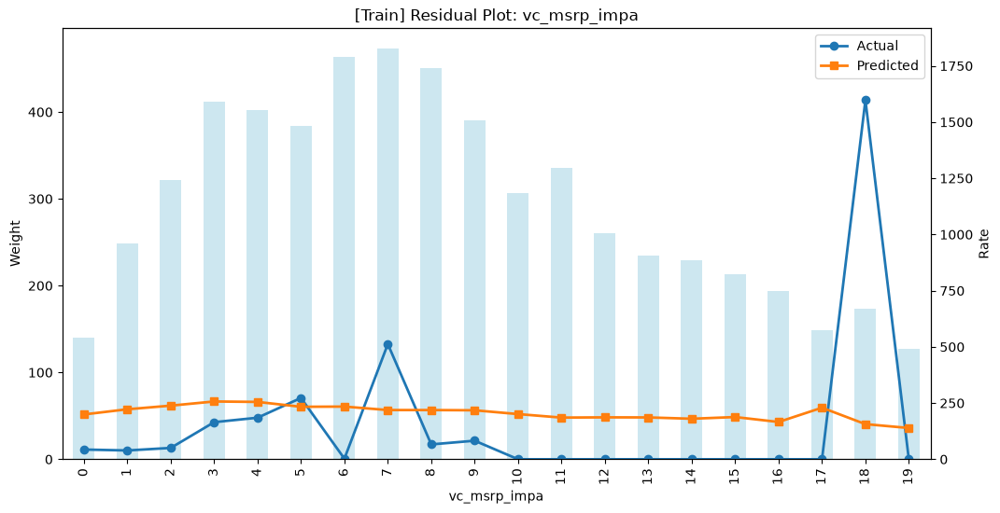

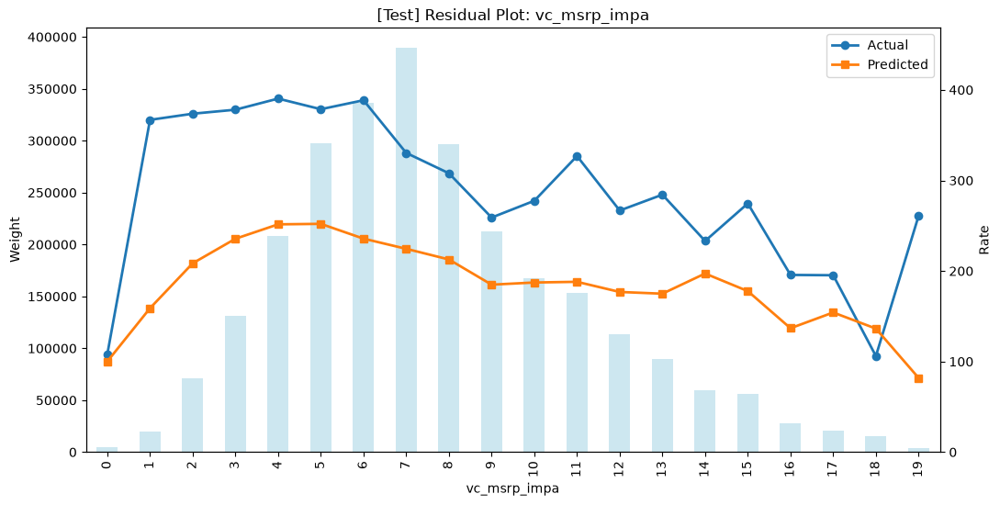


FEATURE: vc_doors_raw


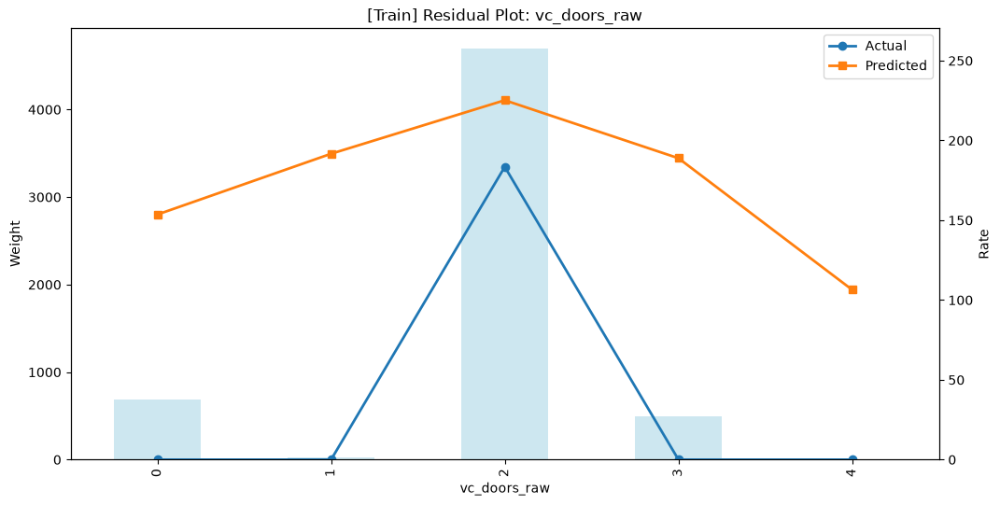

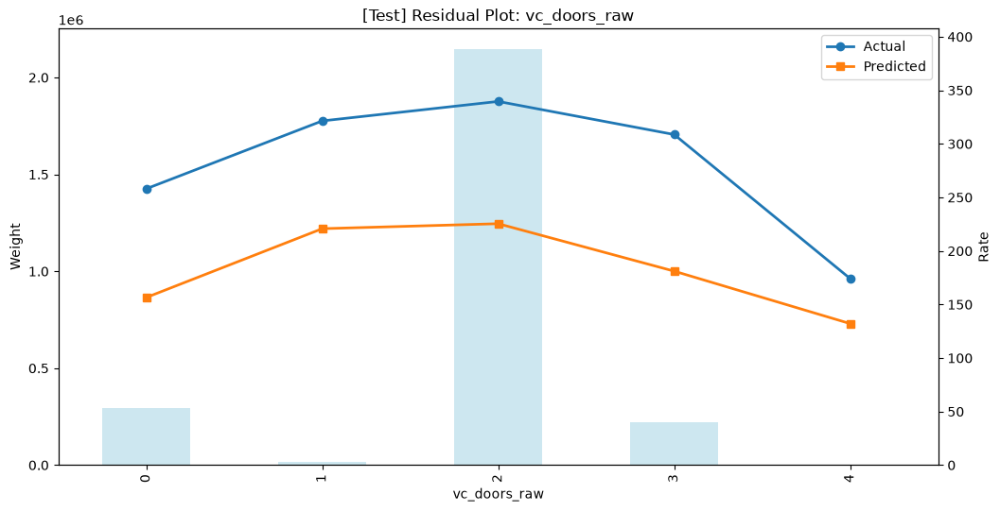

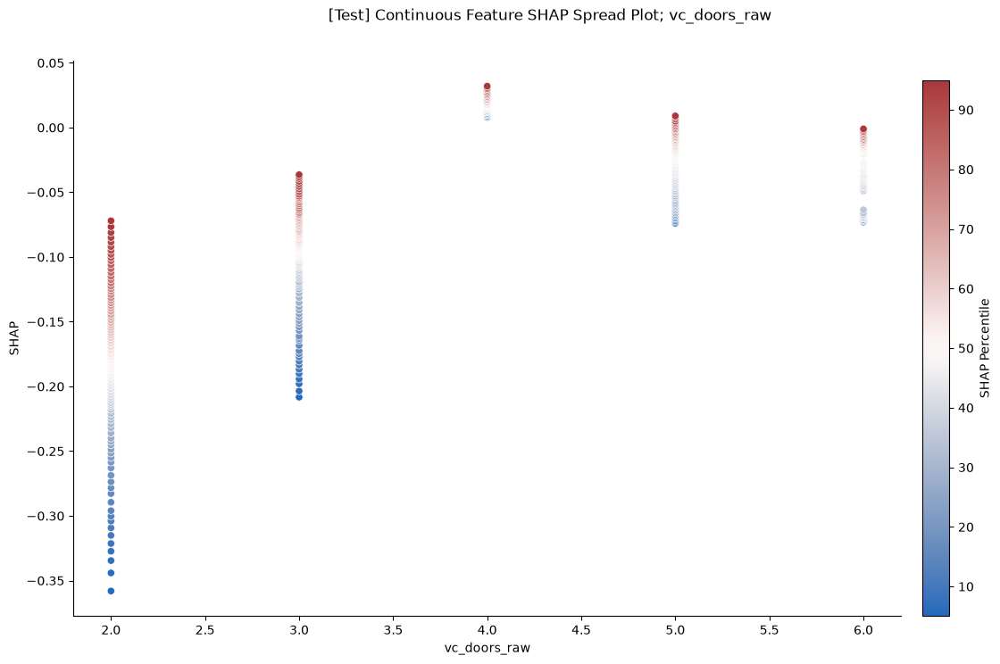


FEATURE: cef_lien_holder_ind


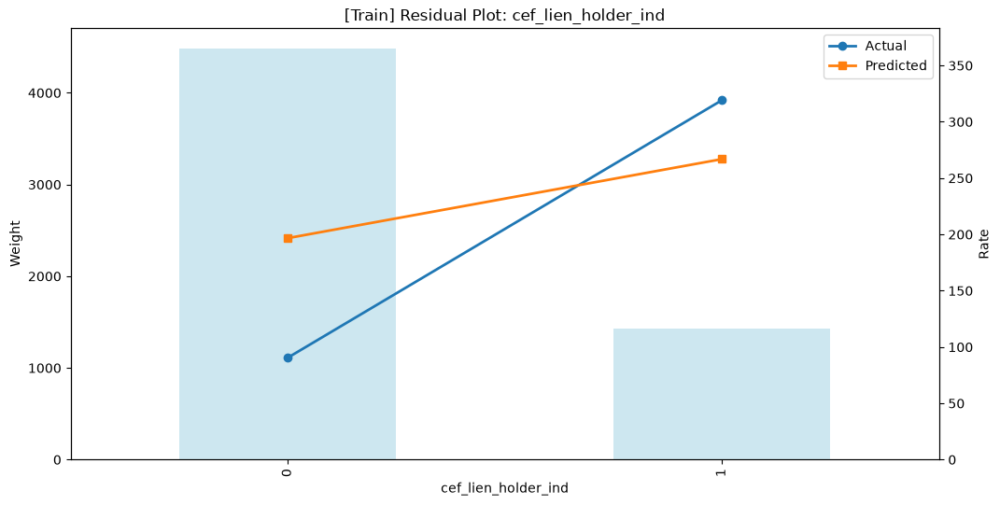

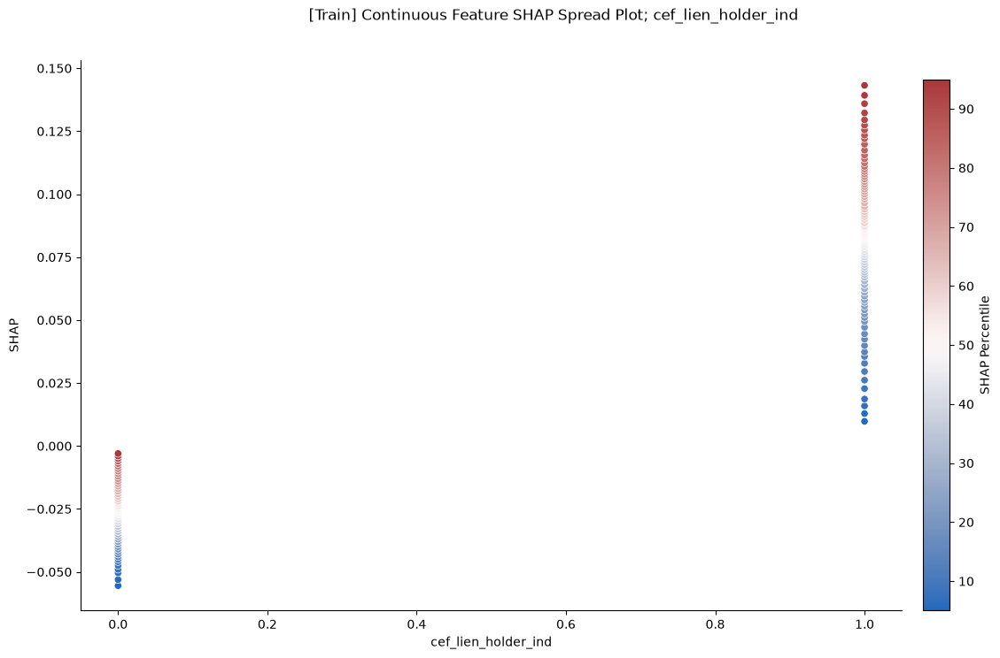

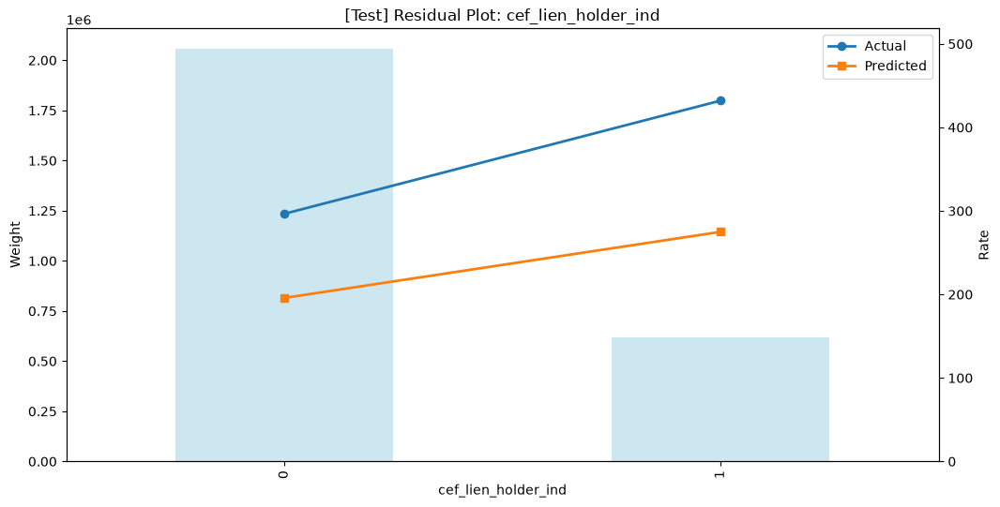

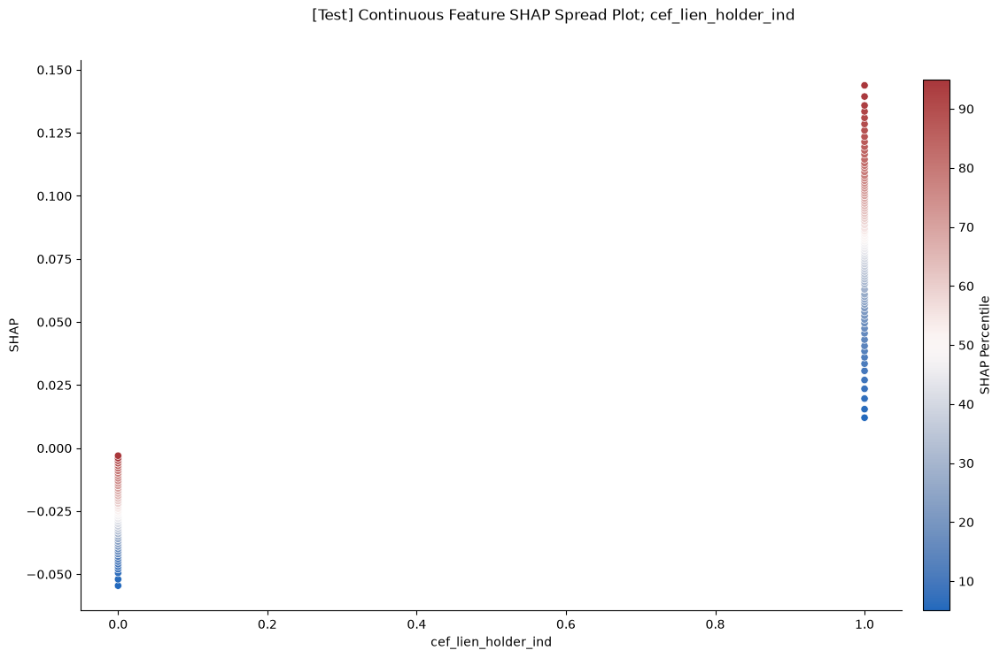


FEATURE: cef_first_sev_prob_ind


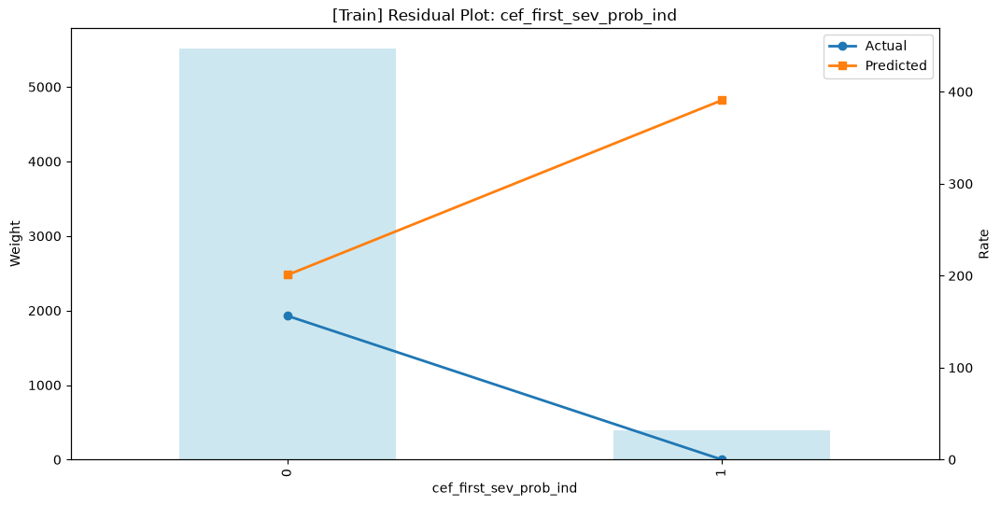

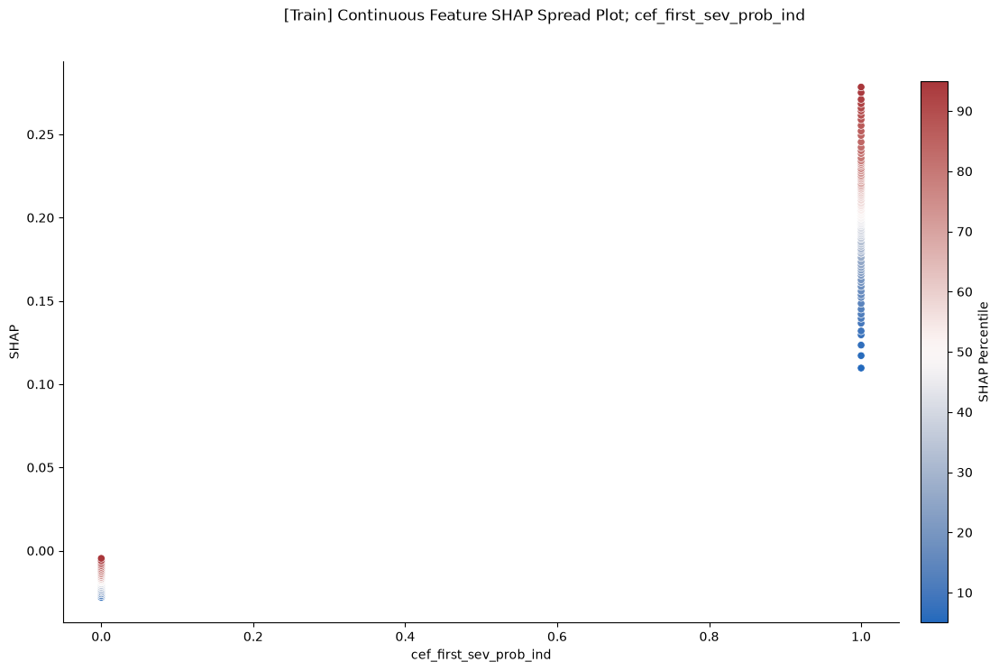

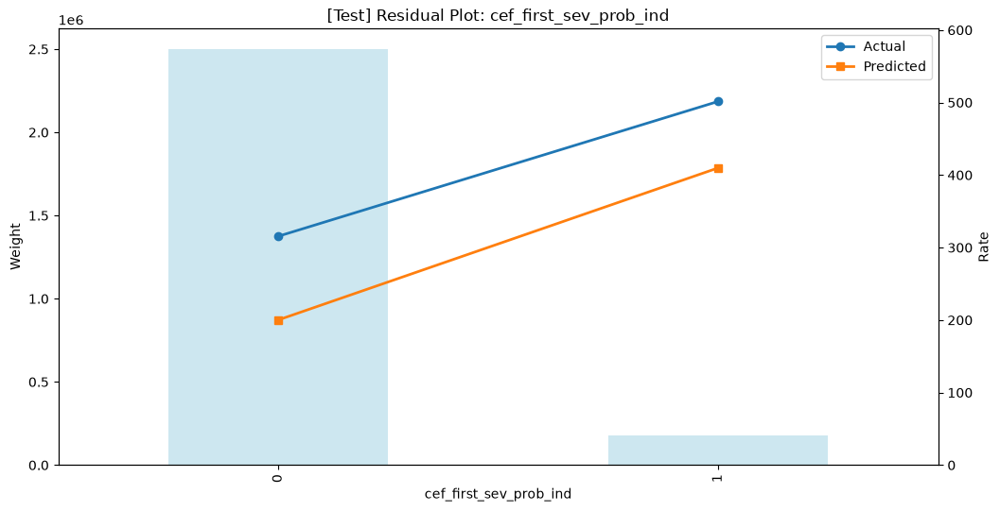

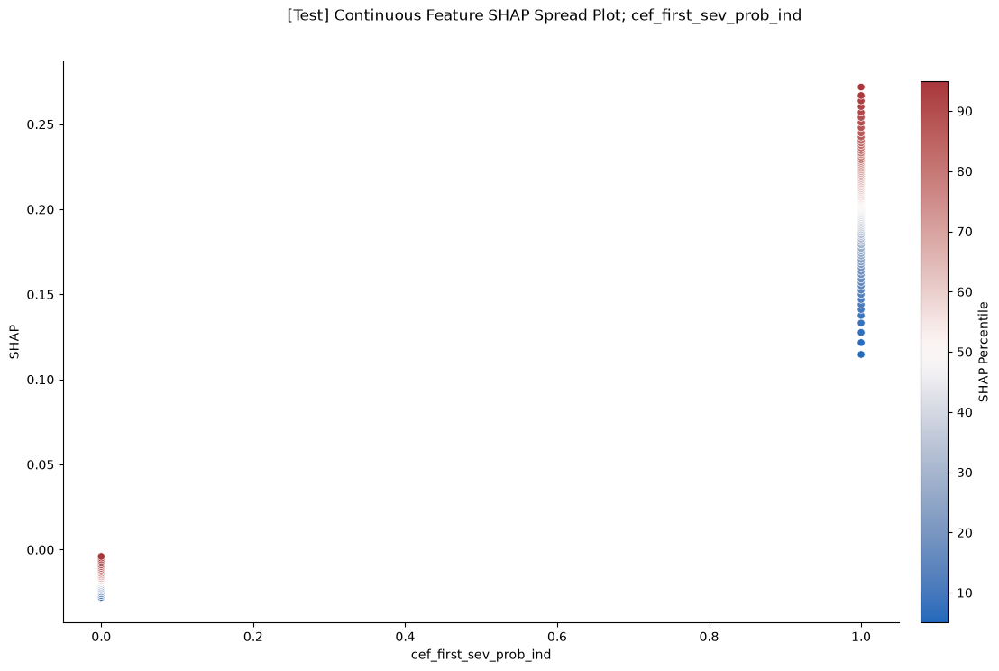


FEATURE: vc_auto_dimming_rearview_mirror_raw_0


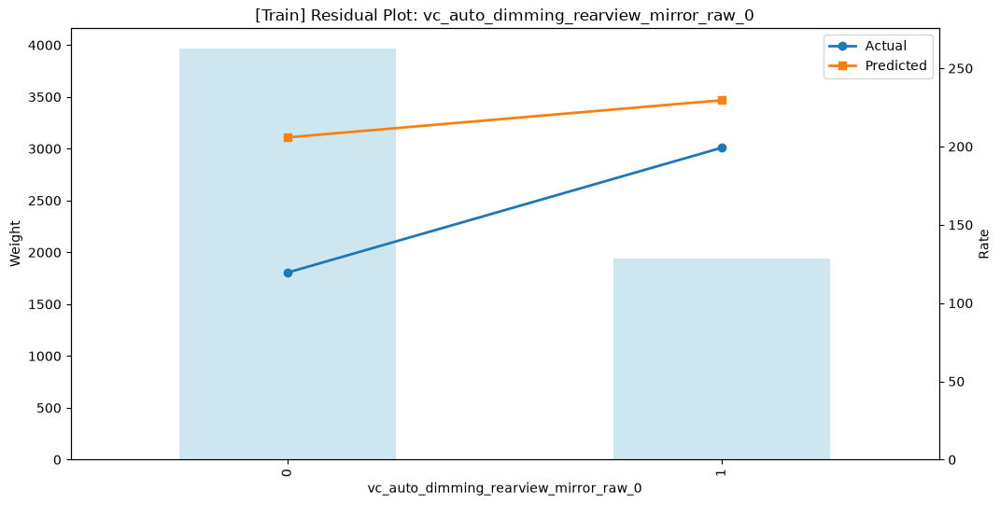

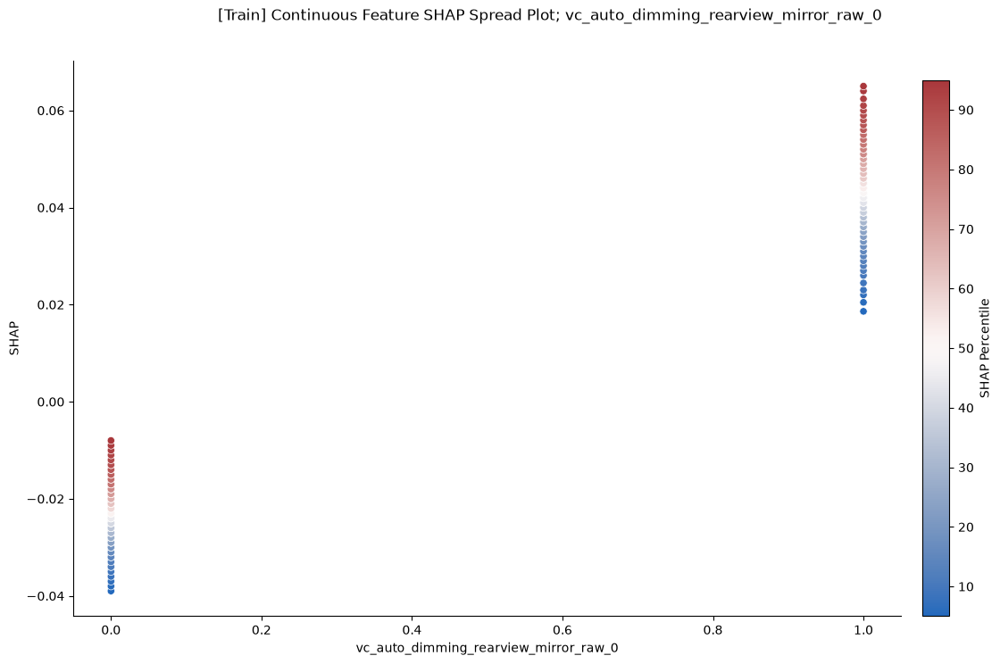

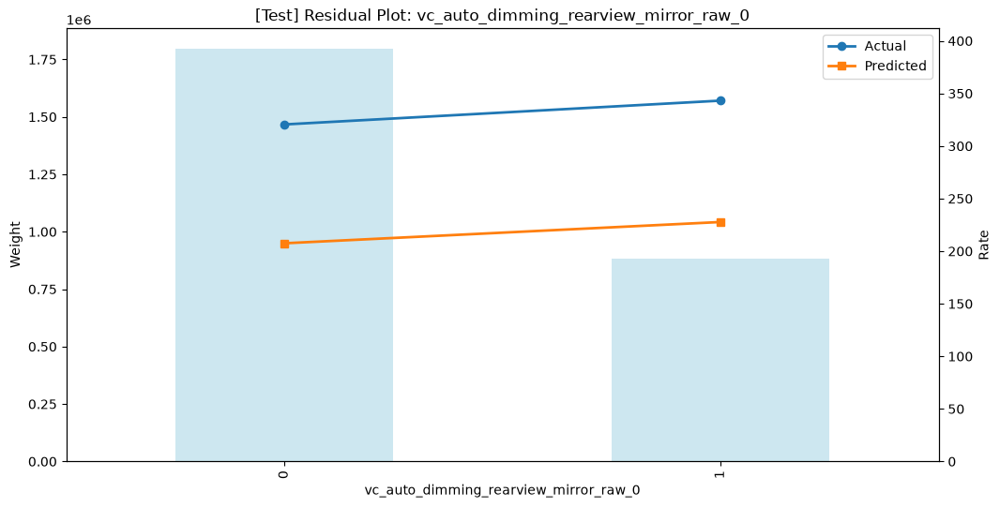

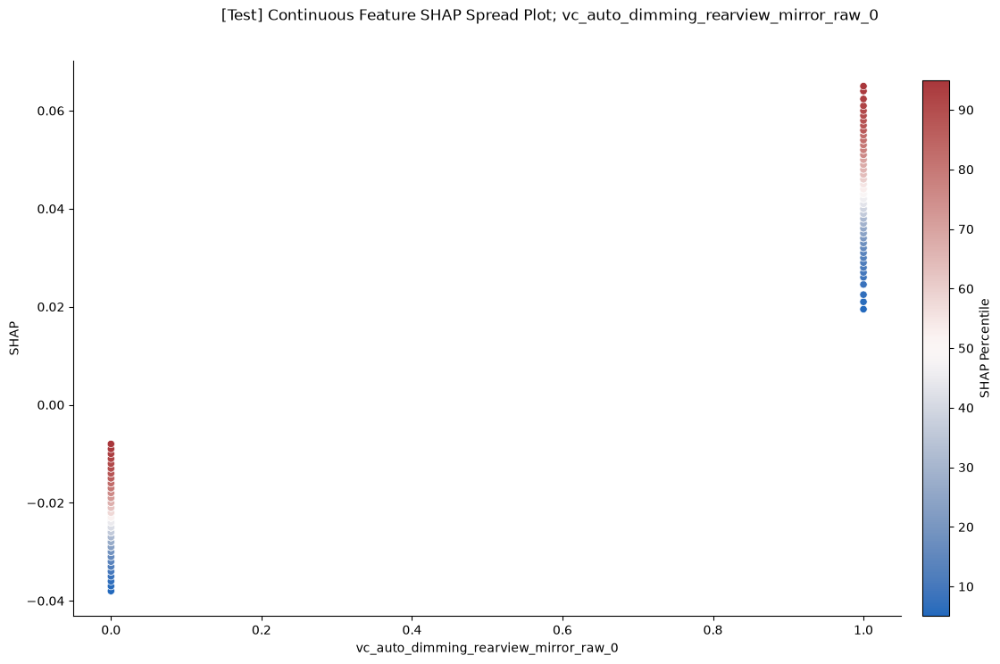


FEATURE: vc_luxury_flag_ind


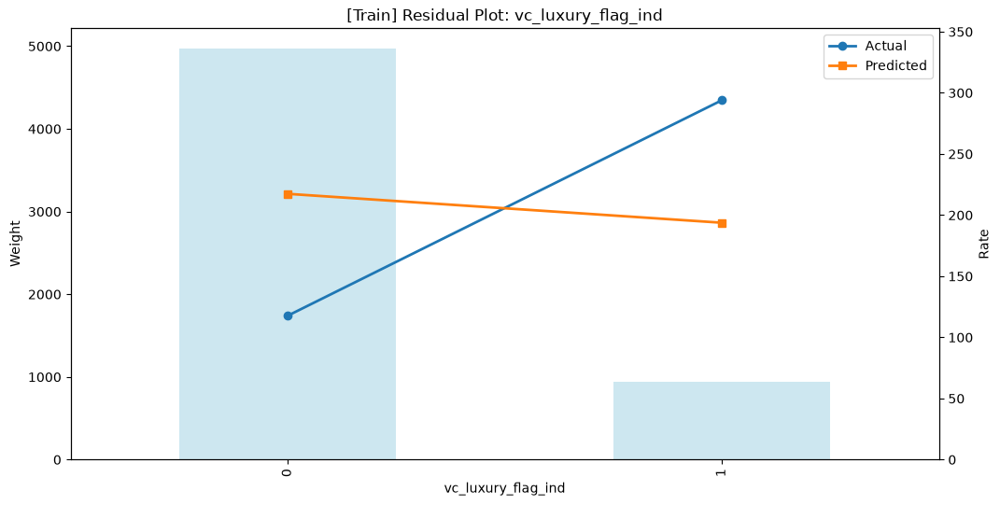

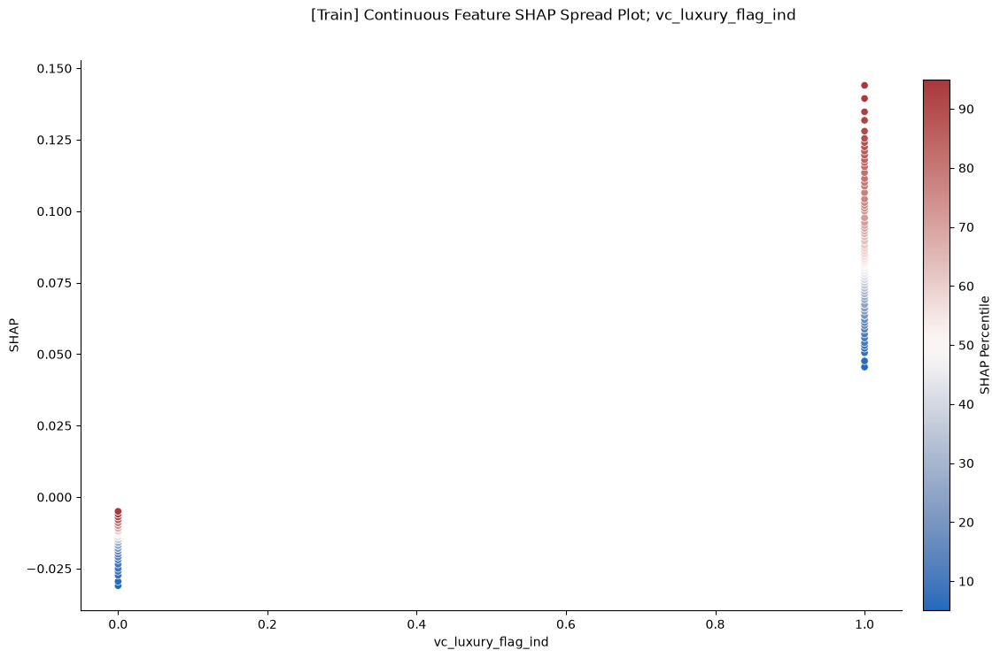

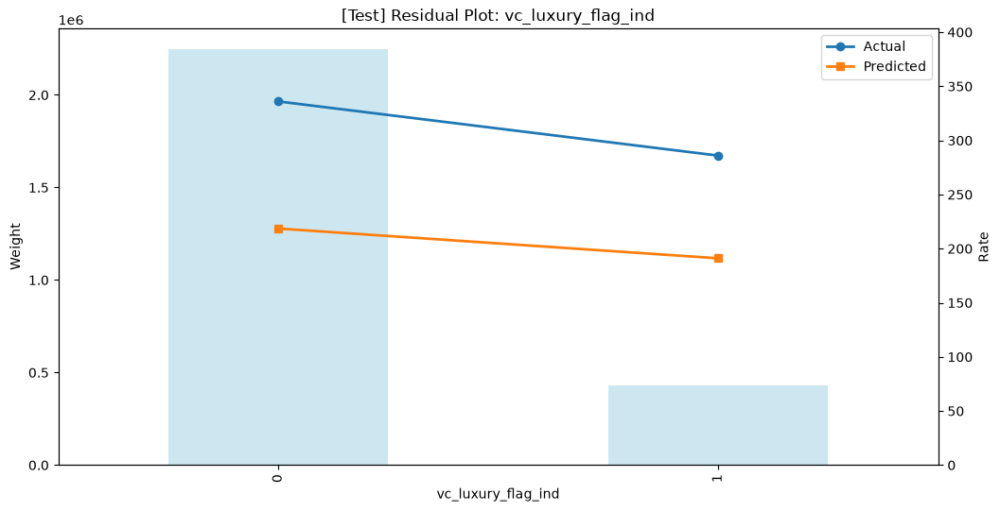

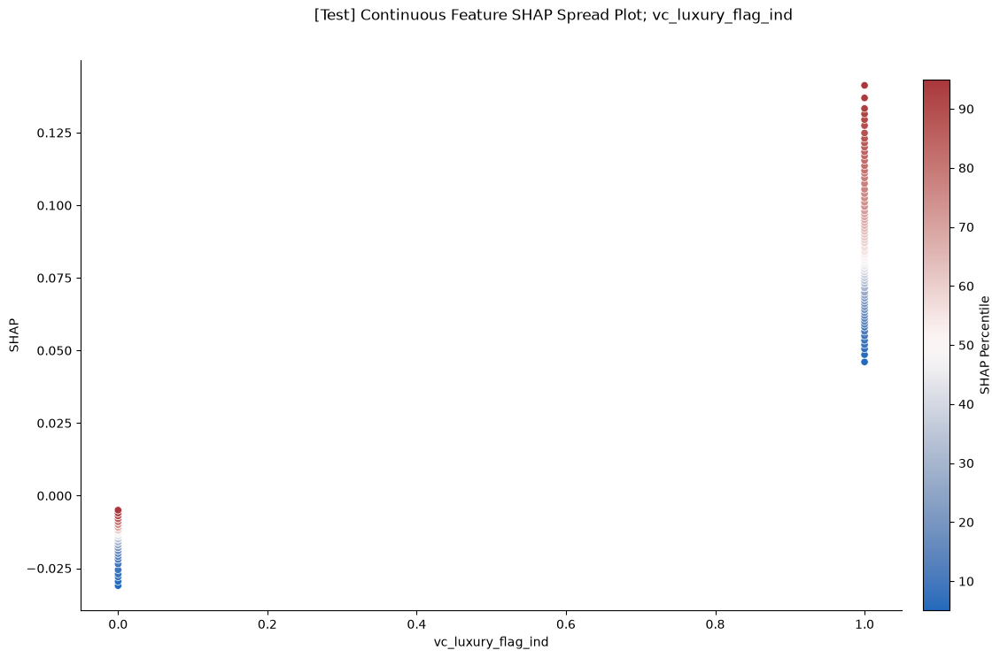


FEATURE: vc_drive_type_fwd_ind


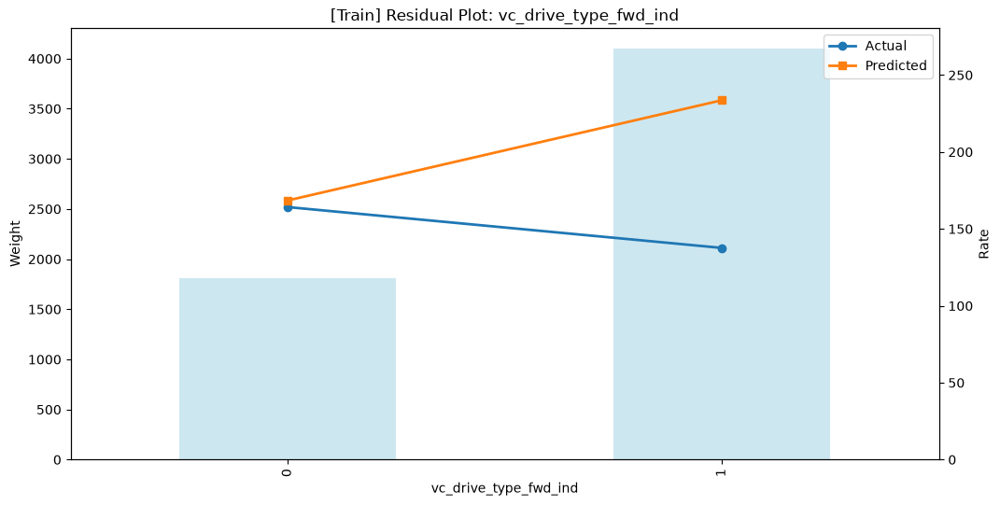

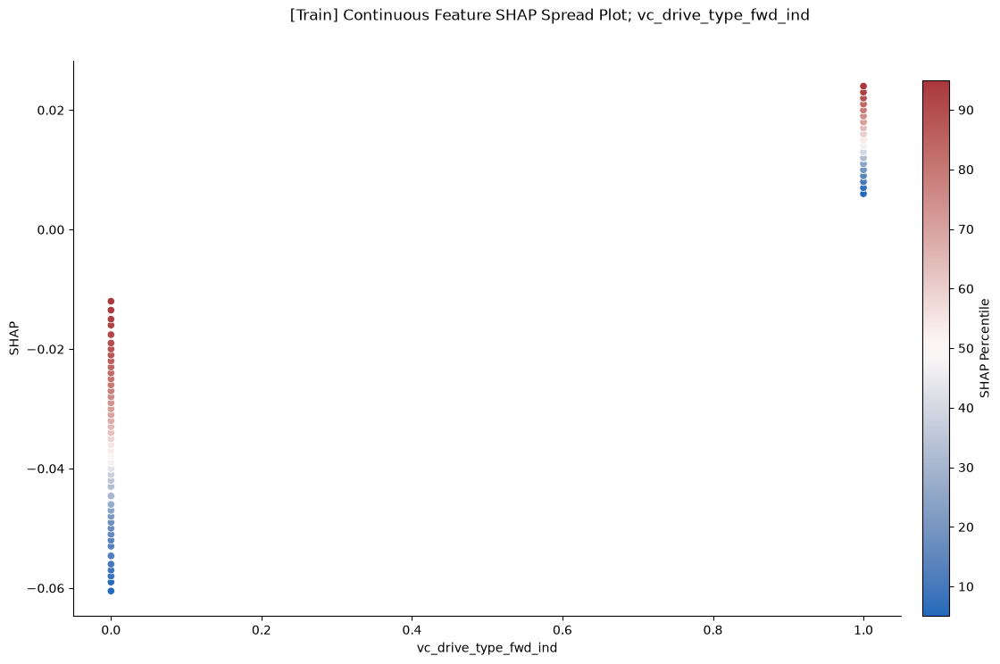

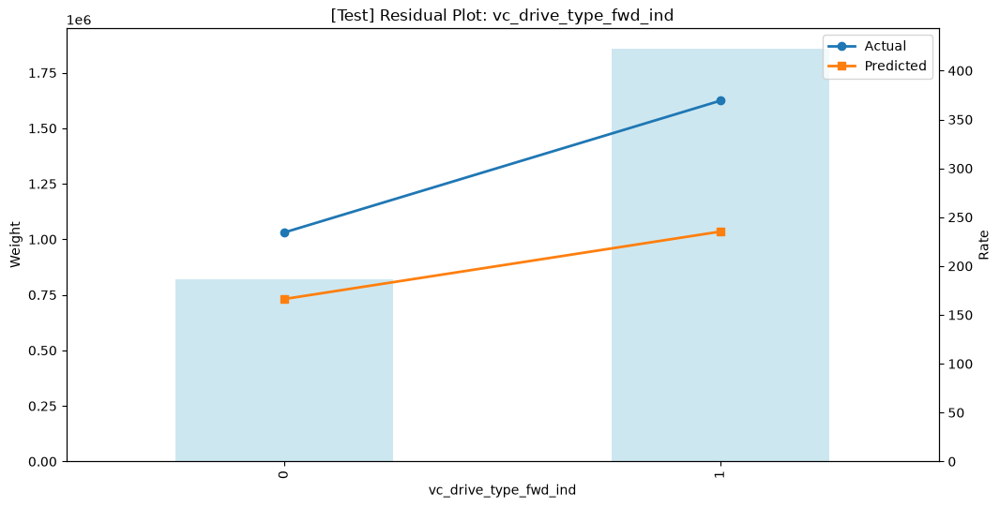

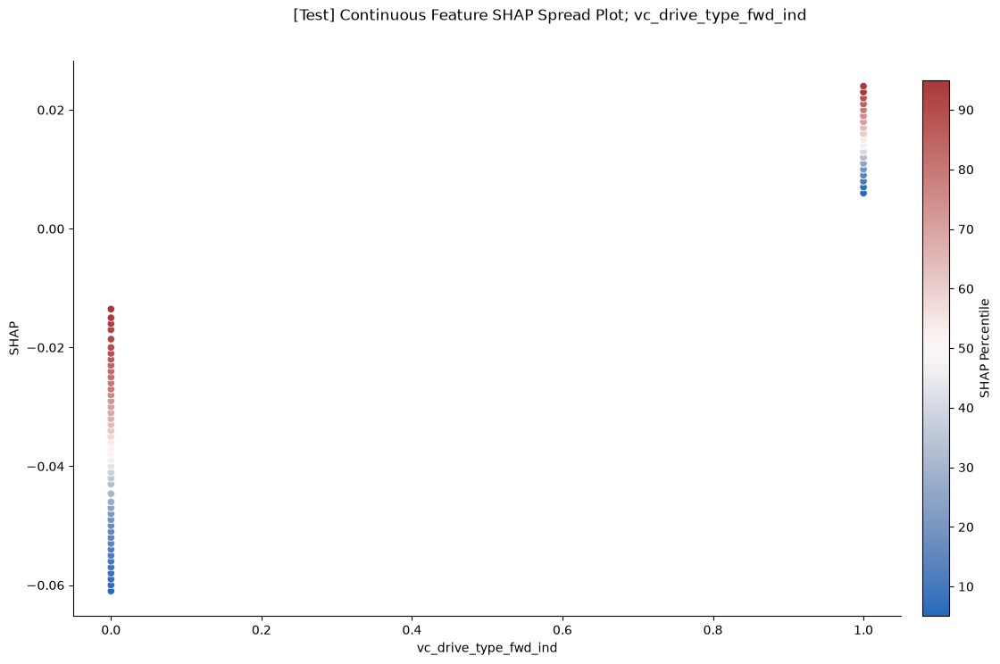


FEATURE: vc_auto_dimming_side_mirrors_raw


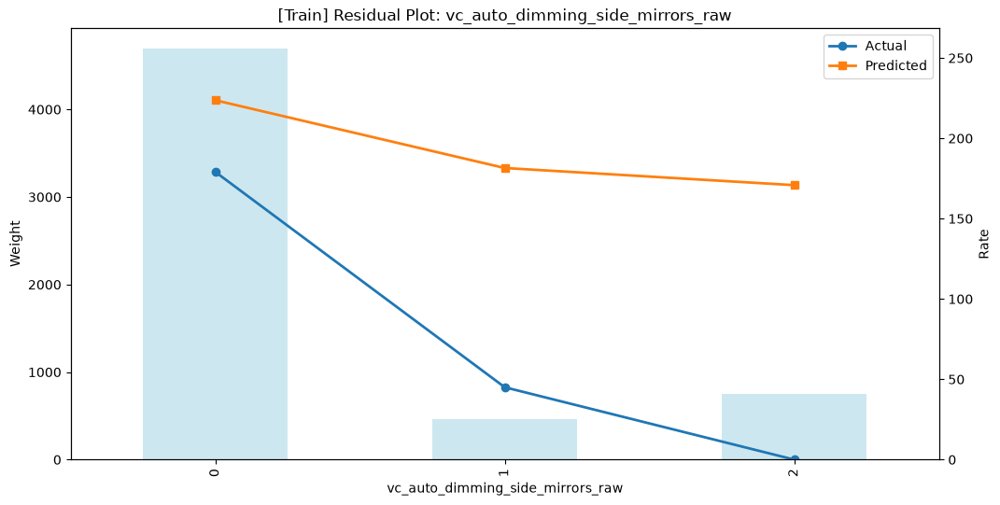

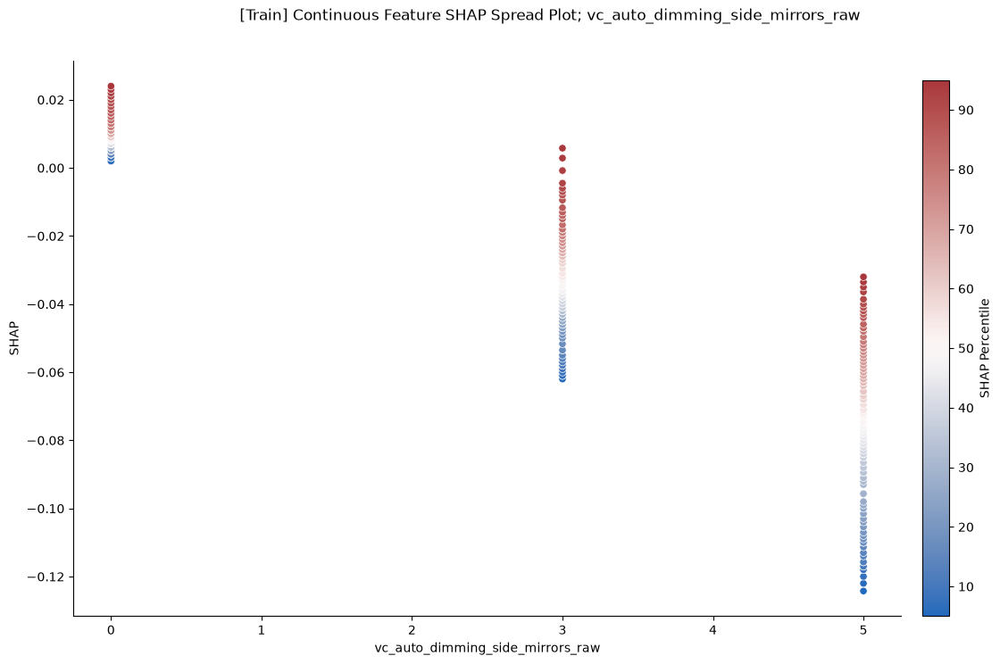

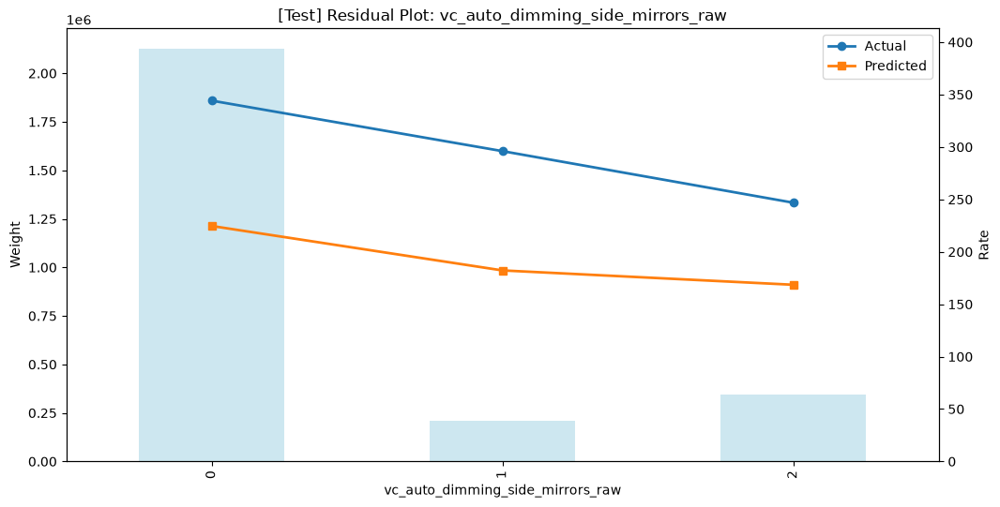

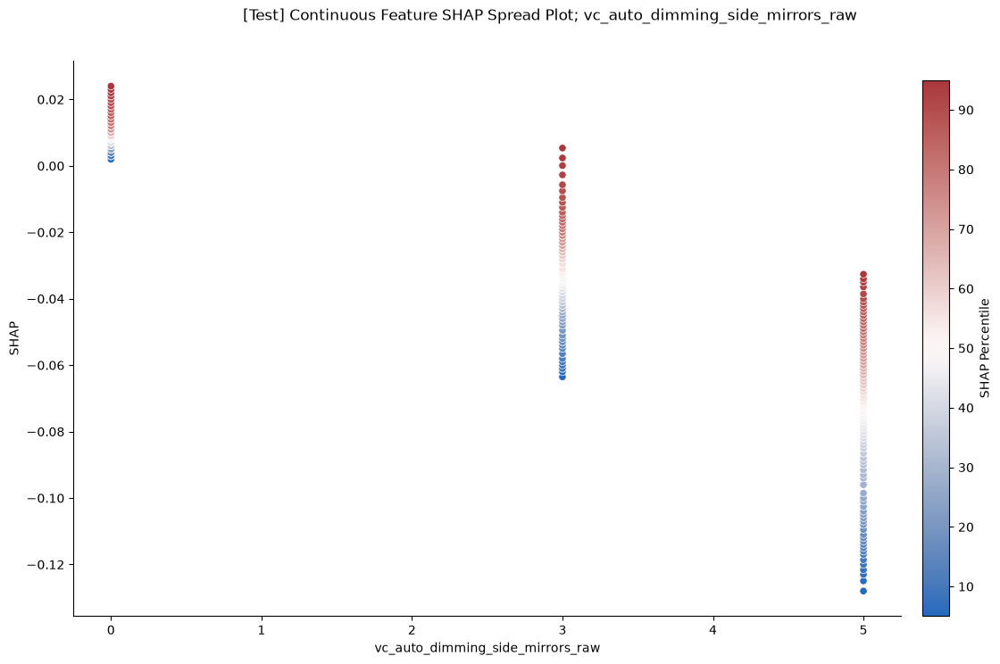


FEATURE: vc_passive_collision_avoidance_system_raw_0


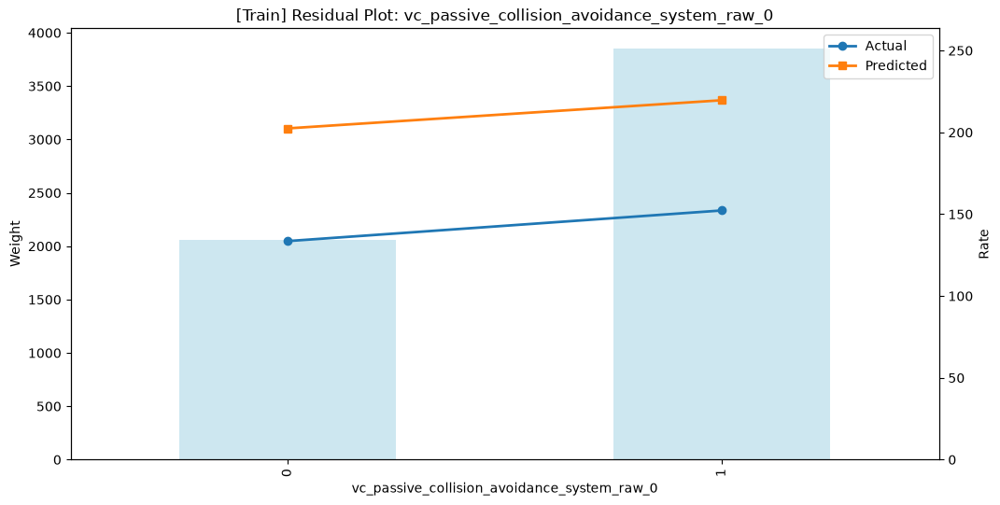

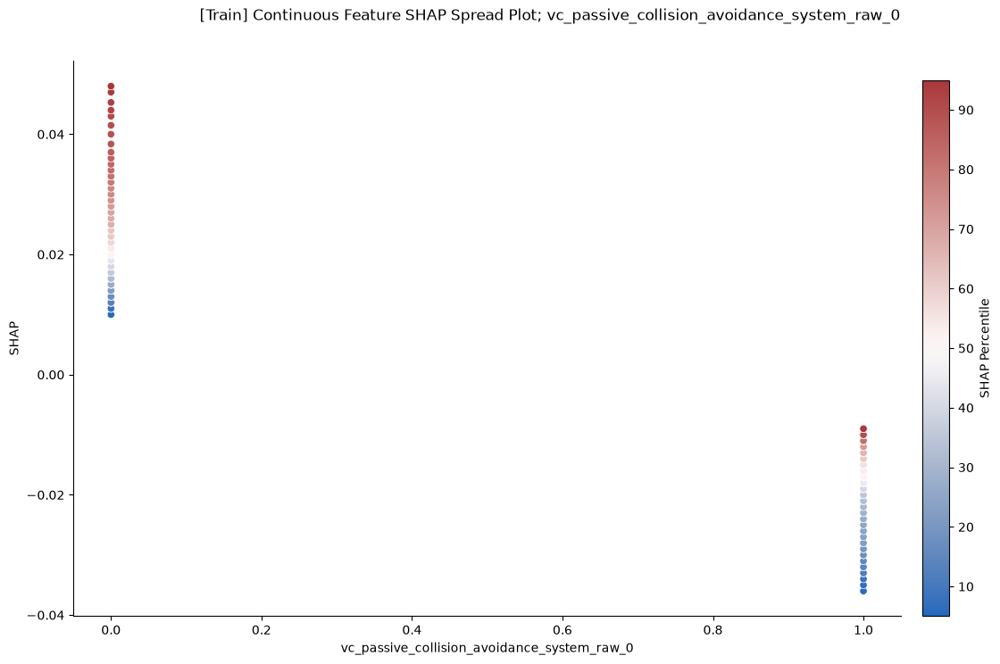

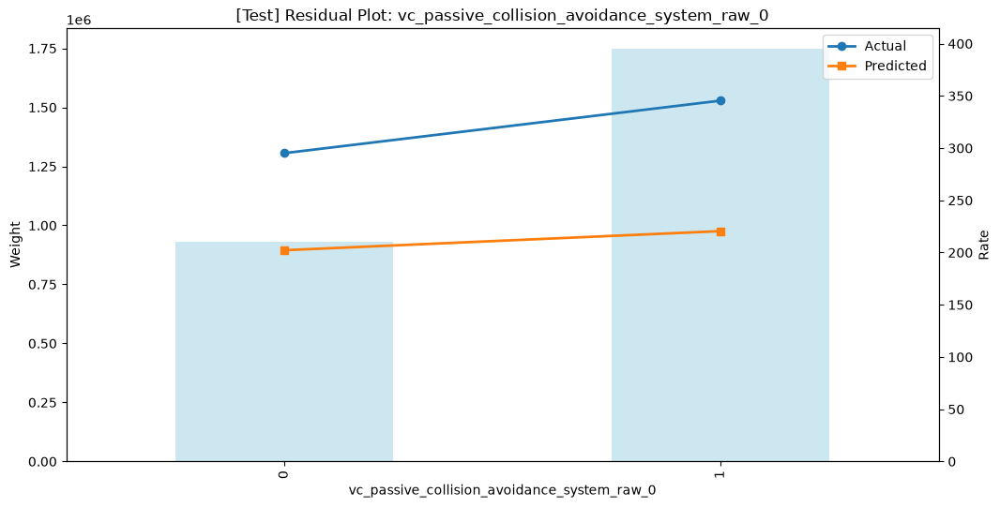

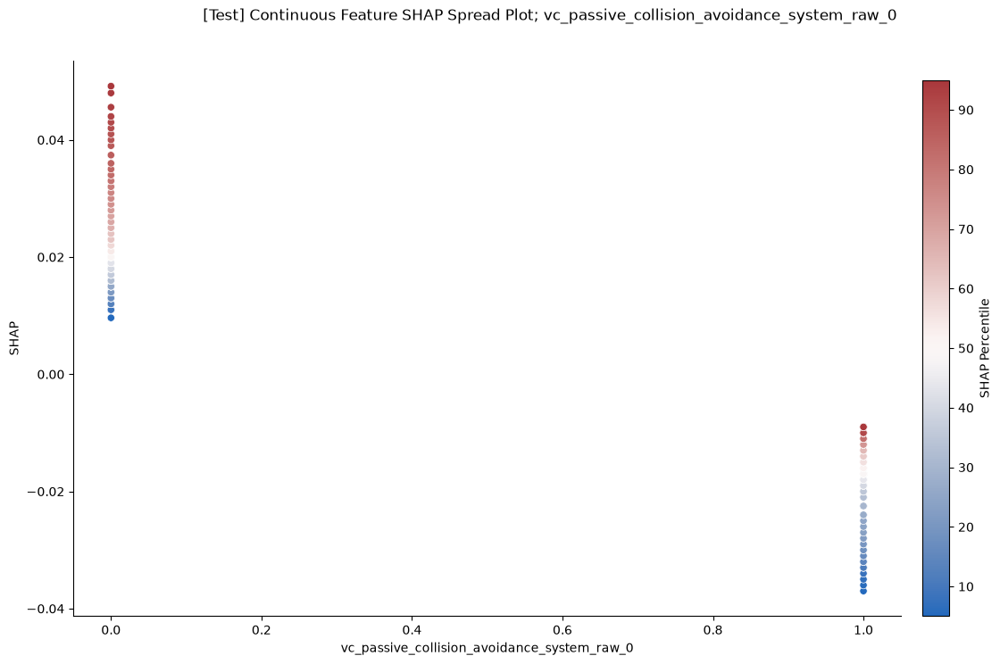


FEATURE: vc_backup_camera_raw_0


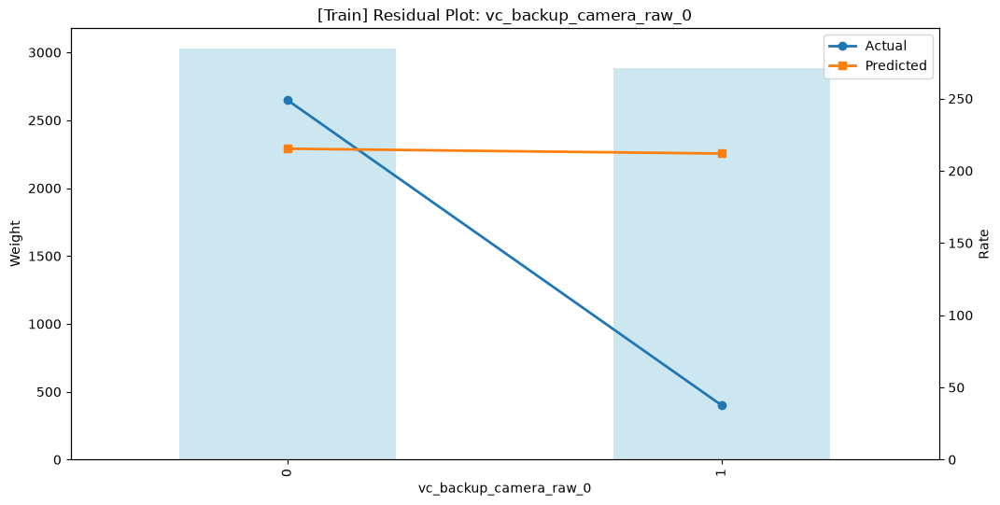

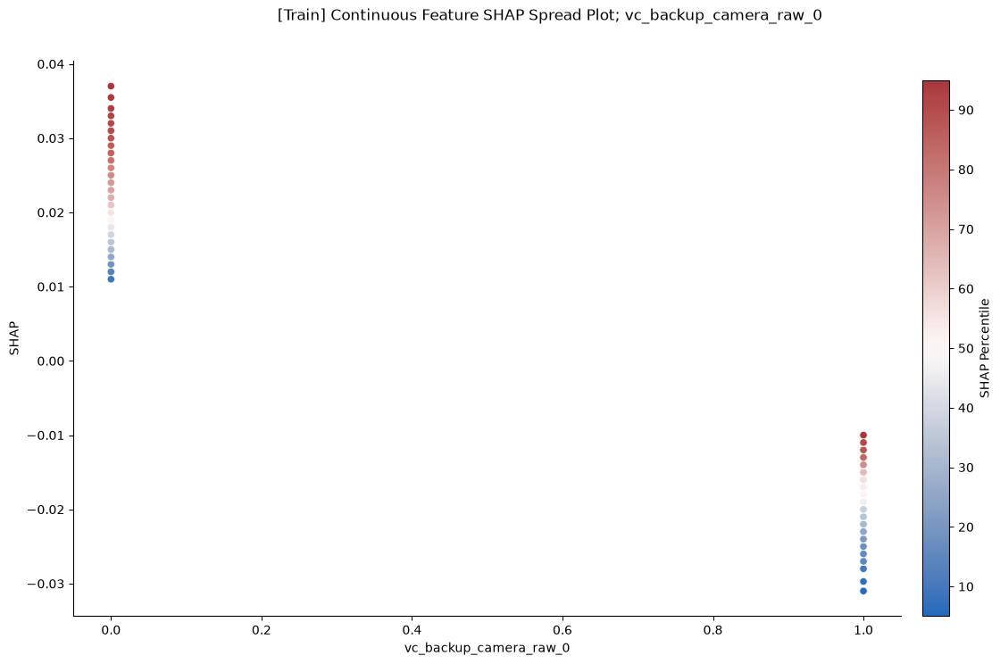

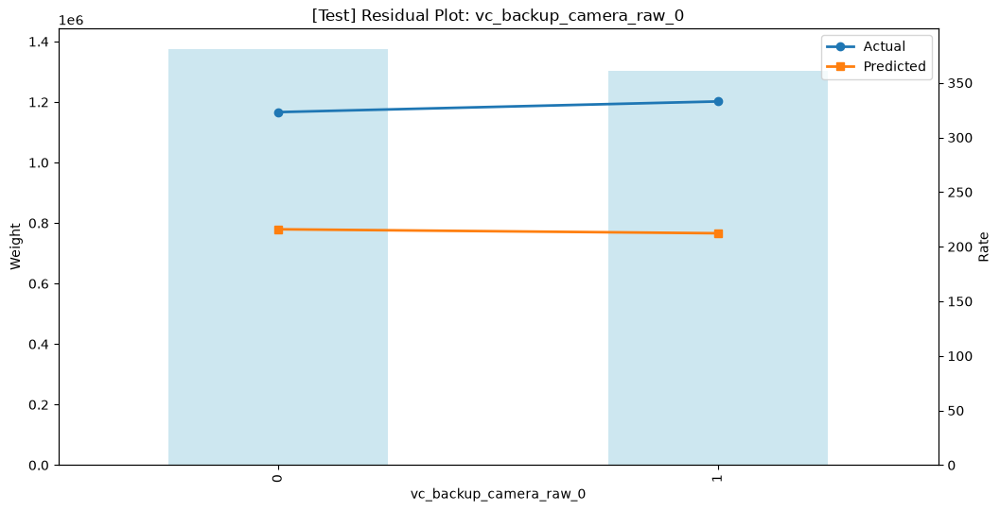

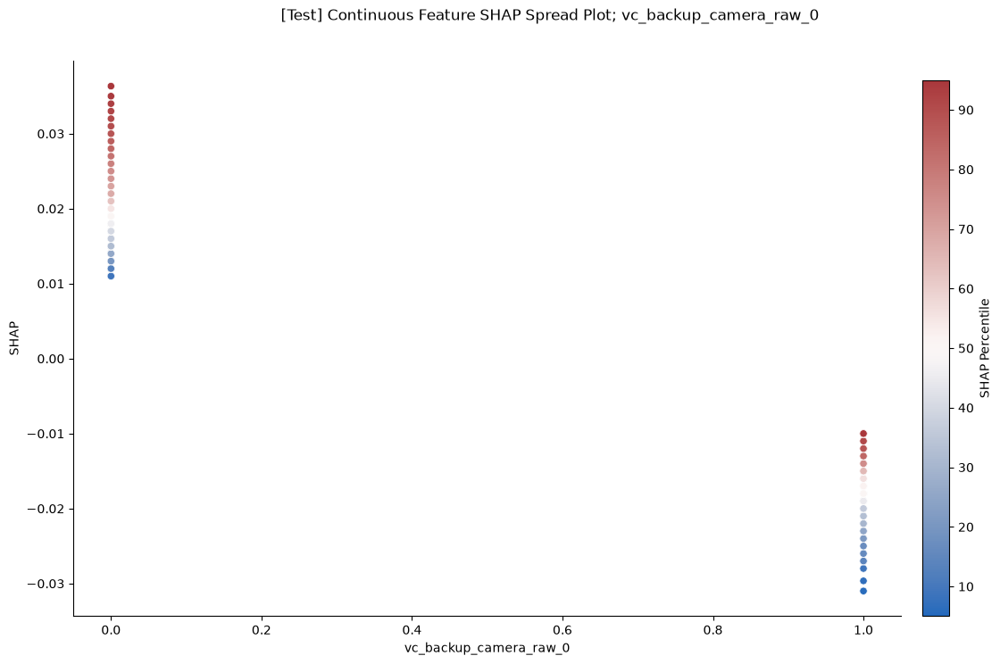


FEATURE: vc_rear_wiper_raw_0


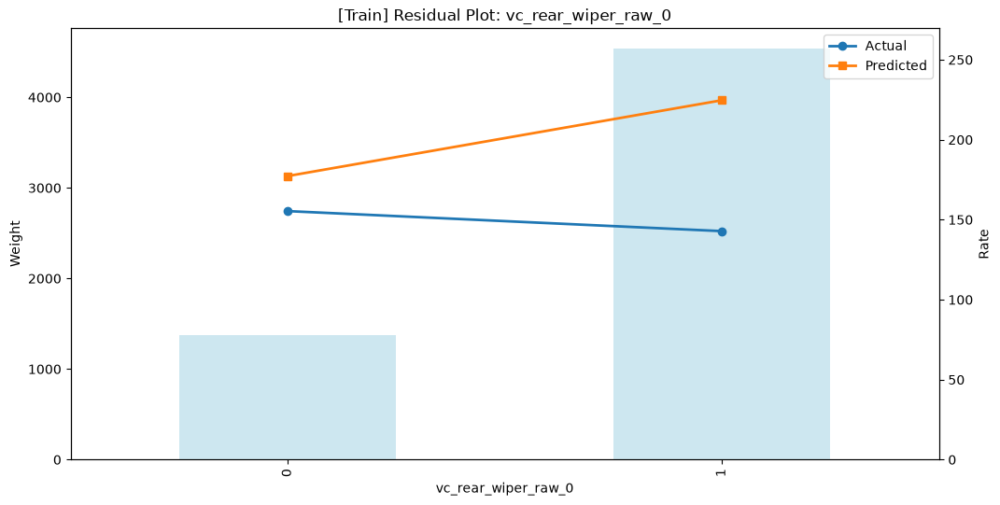

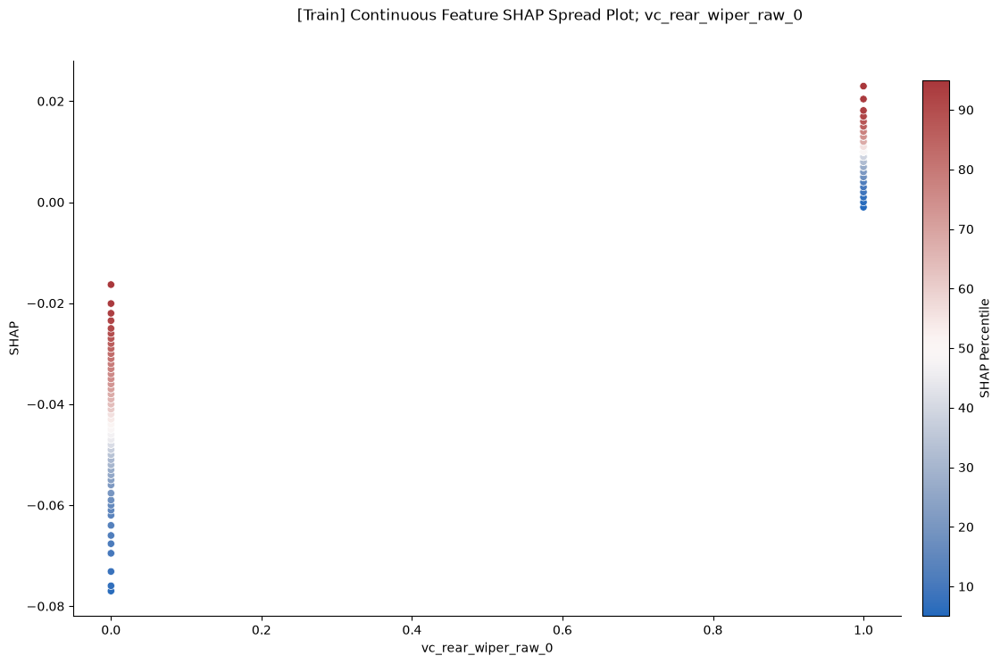

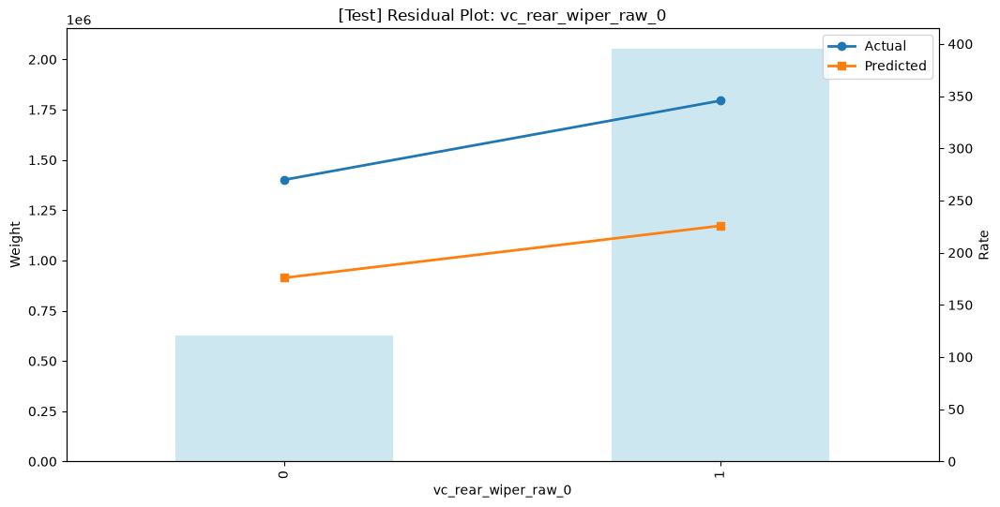

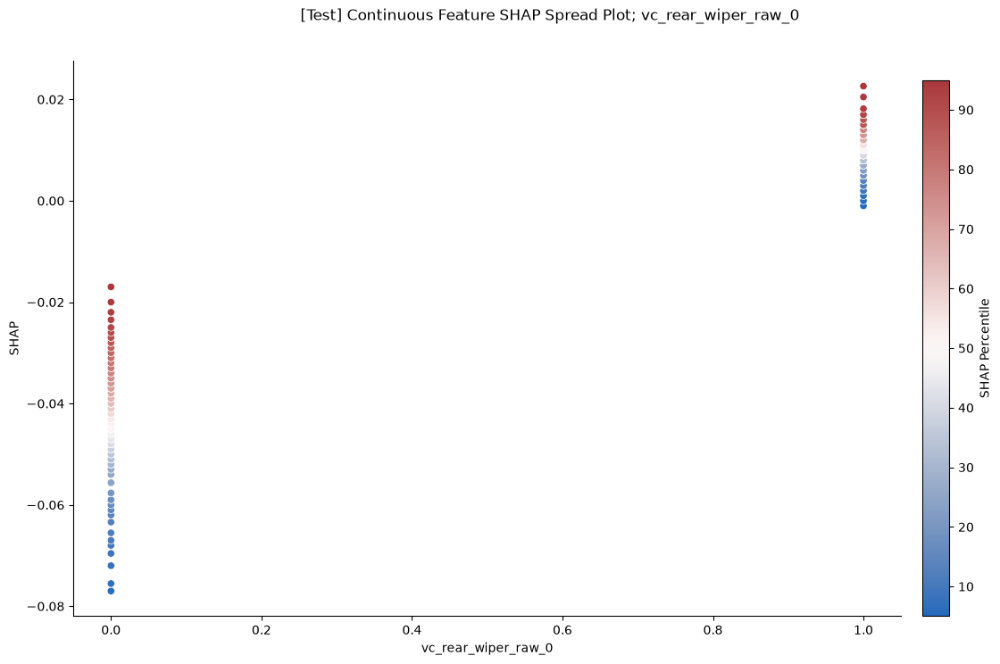


FEATURE: vc_touch_screen_raw_0


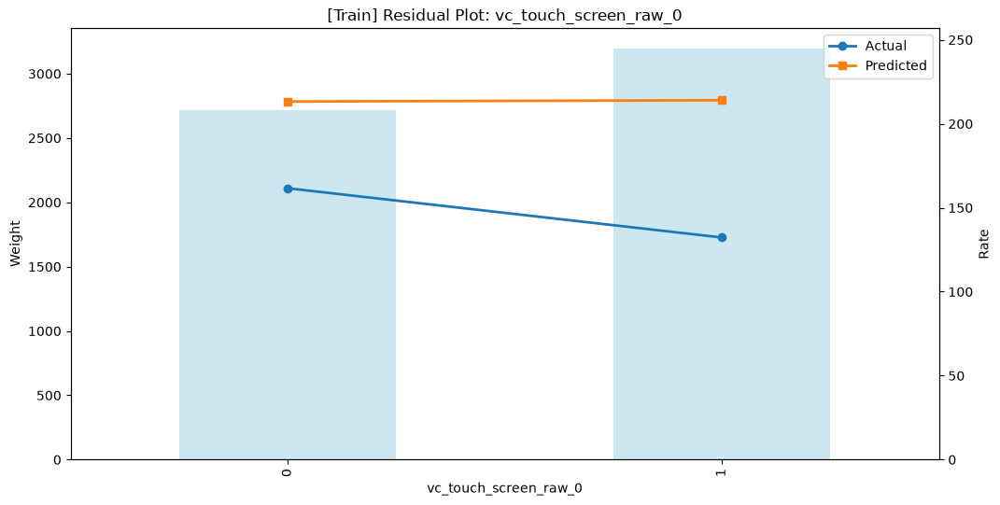

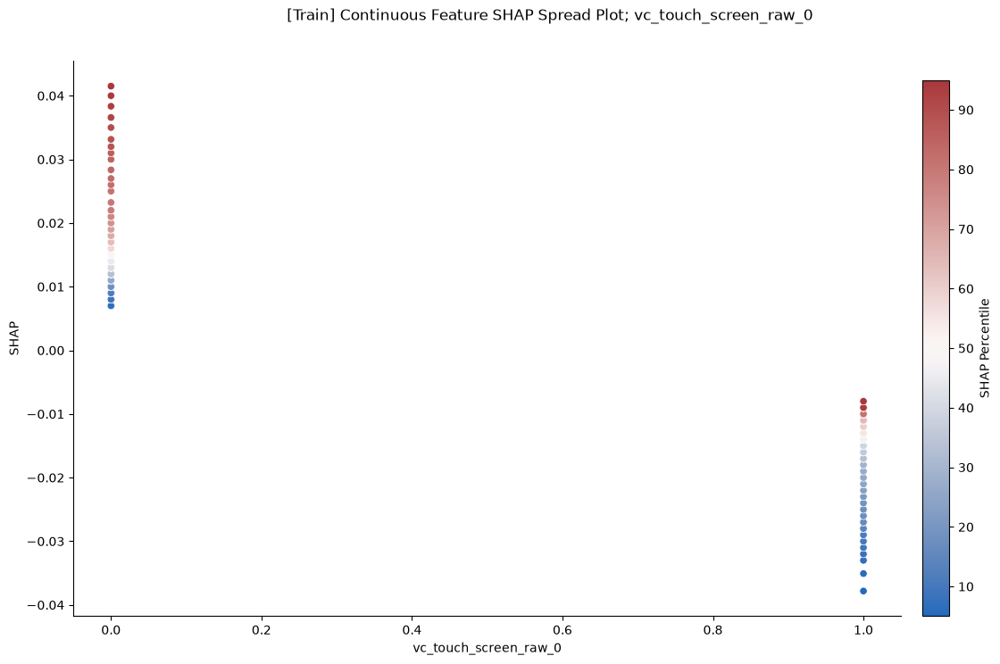

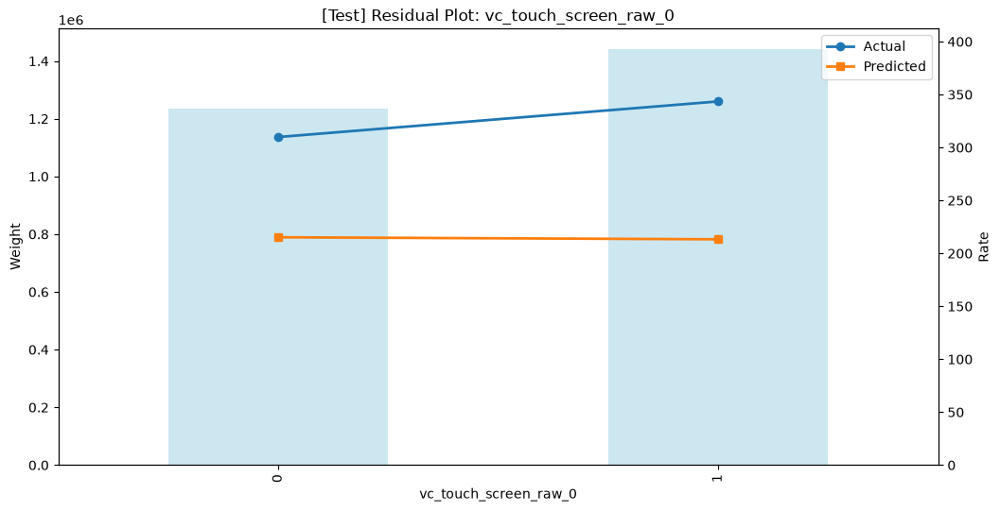

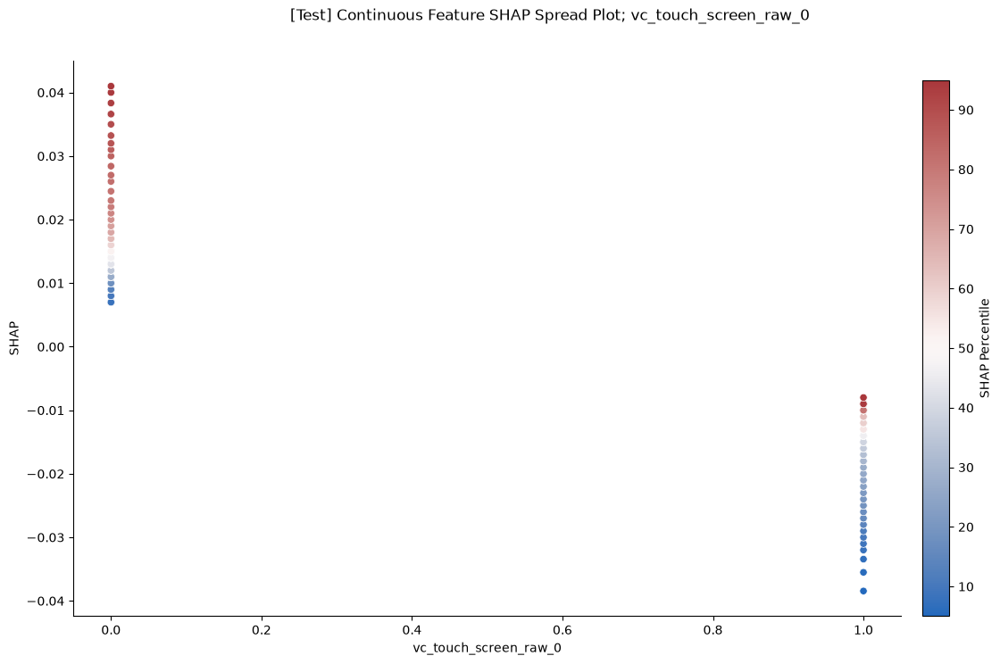


FEATURE: owt_leasepers_ind


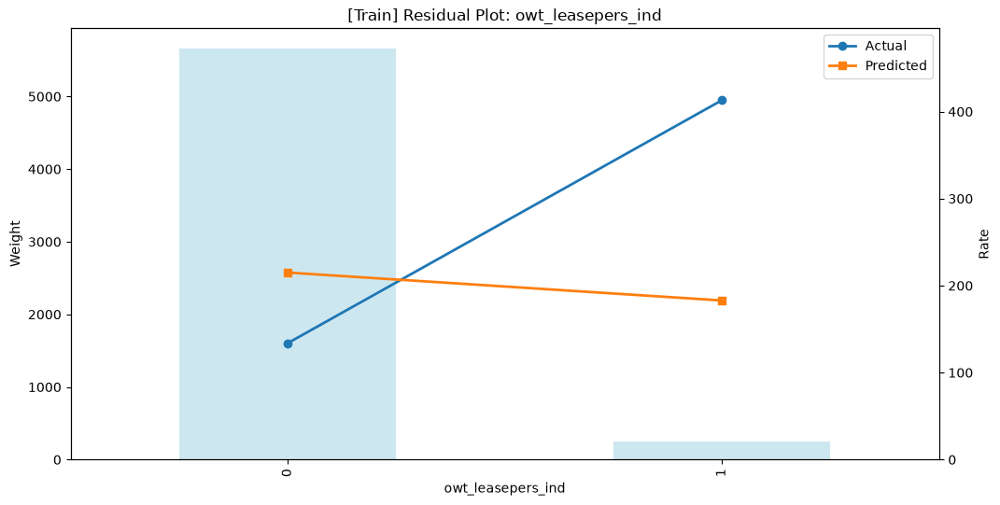

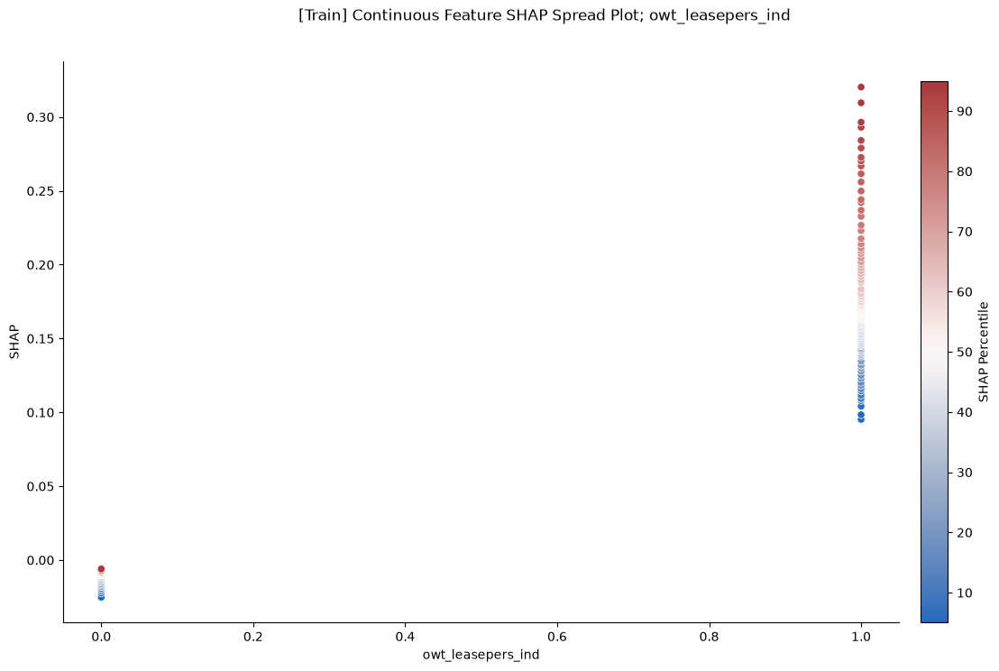

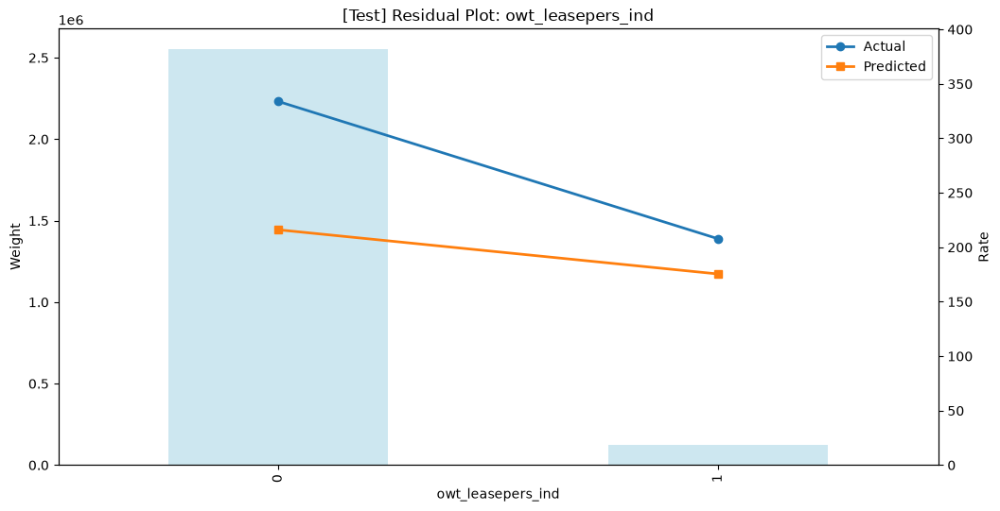

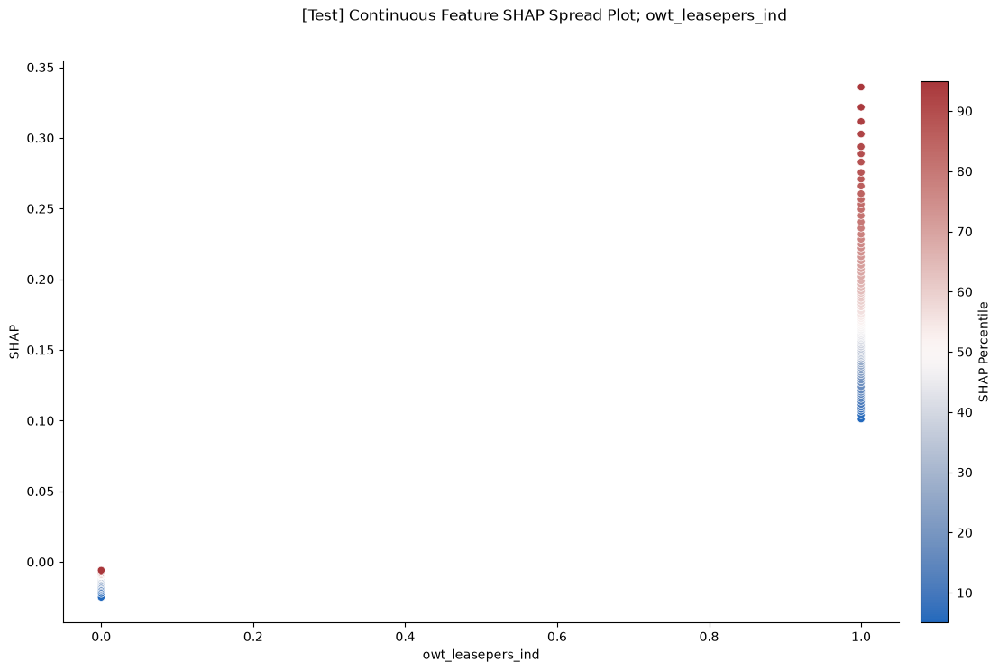


FEATURE: vc_premium_audio_raw


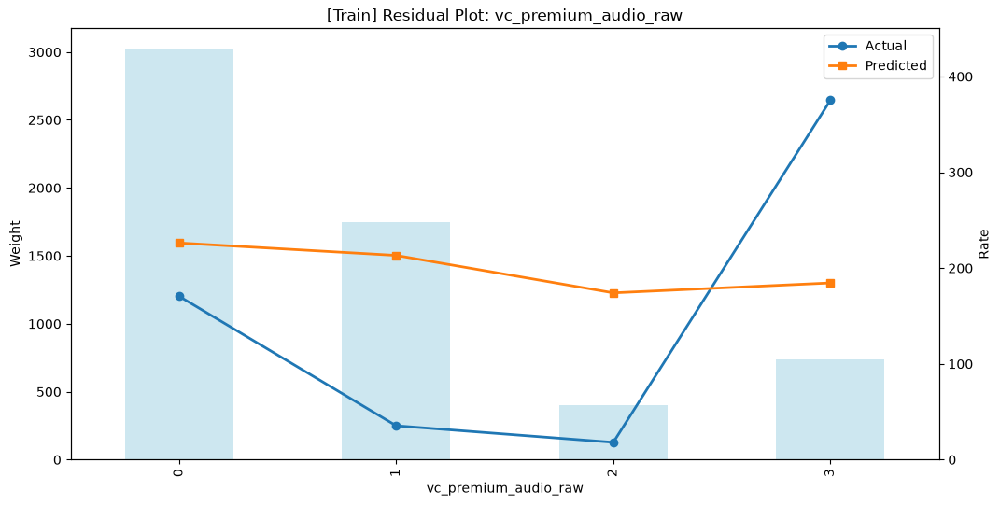

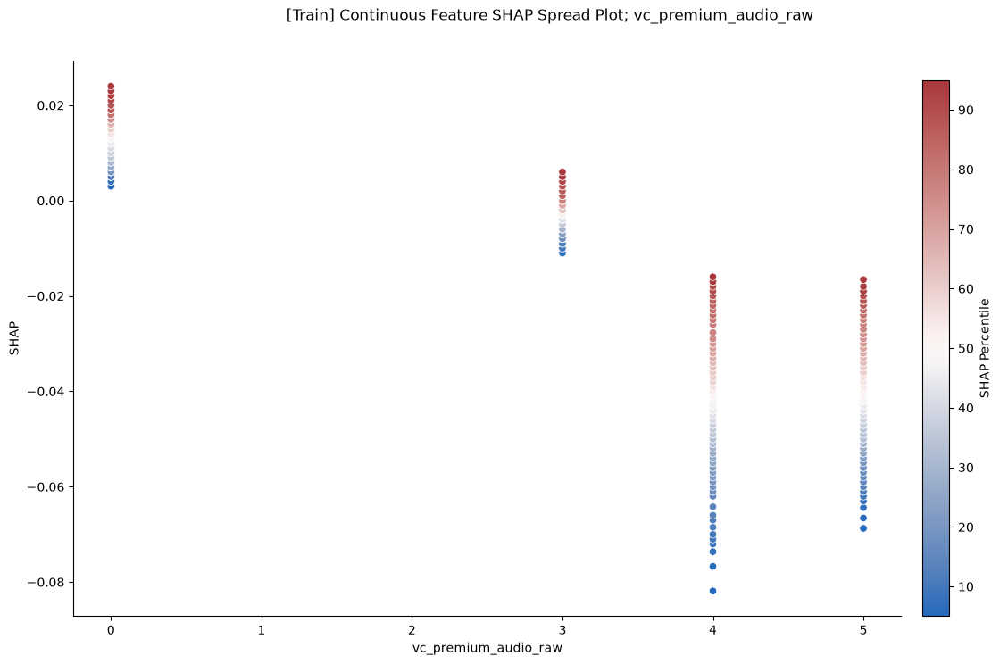

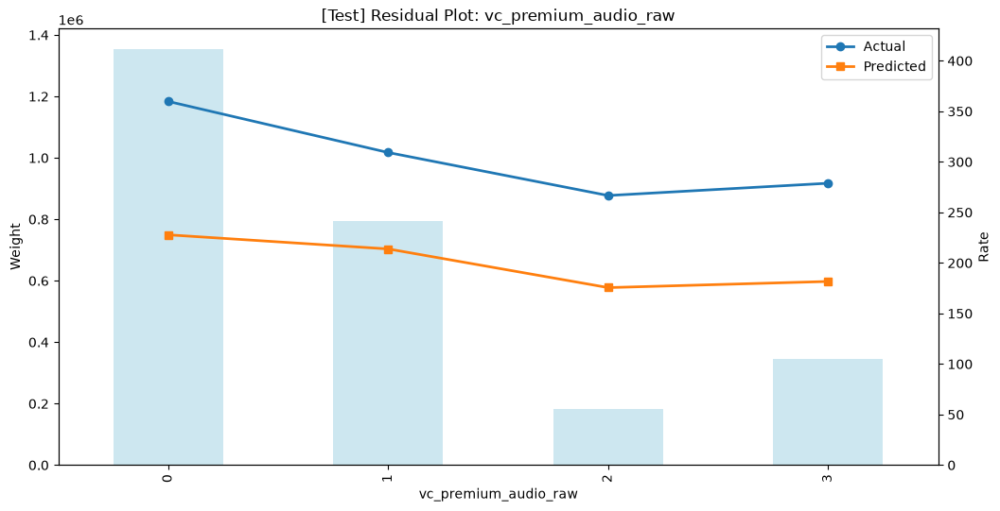

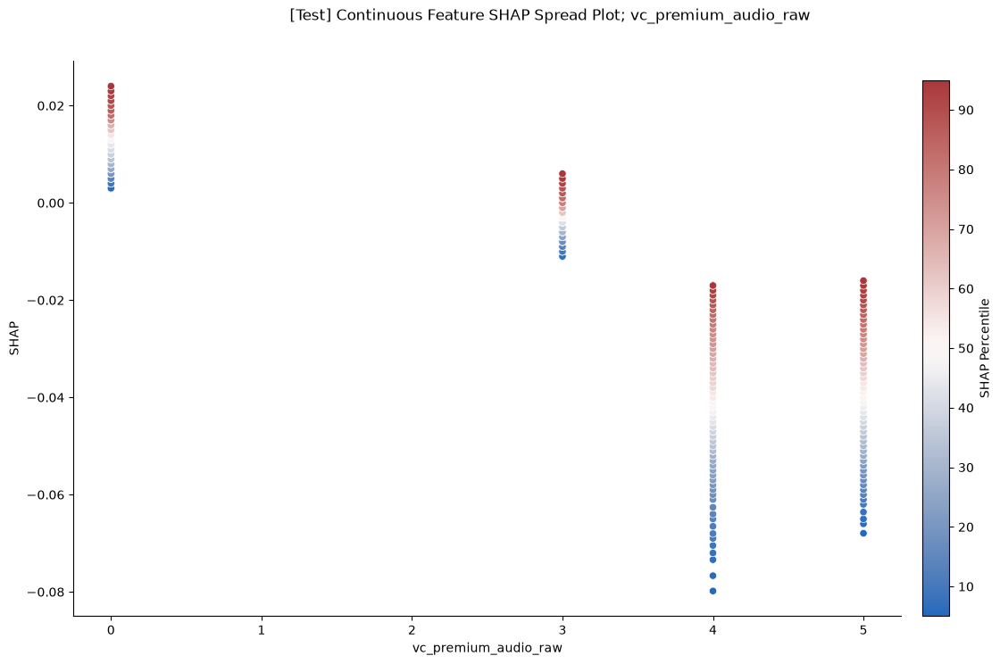


FEATURE: vc_touch_screen_raw_5


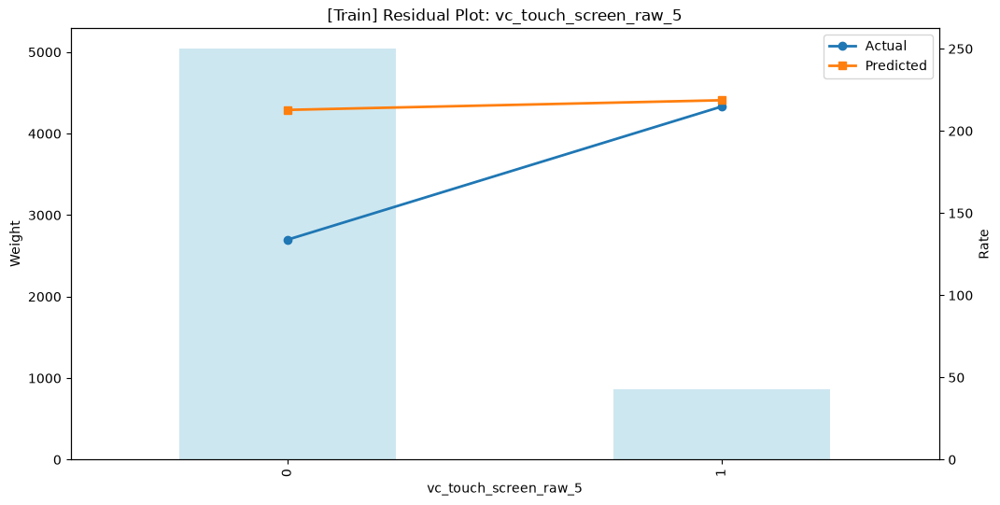

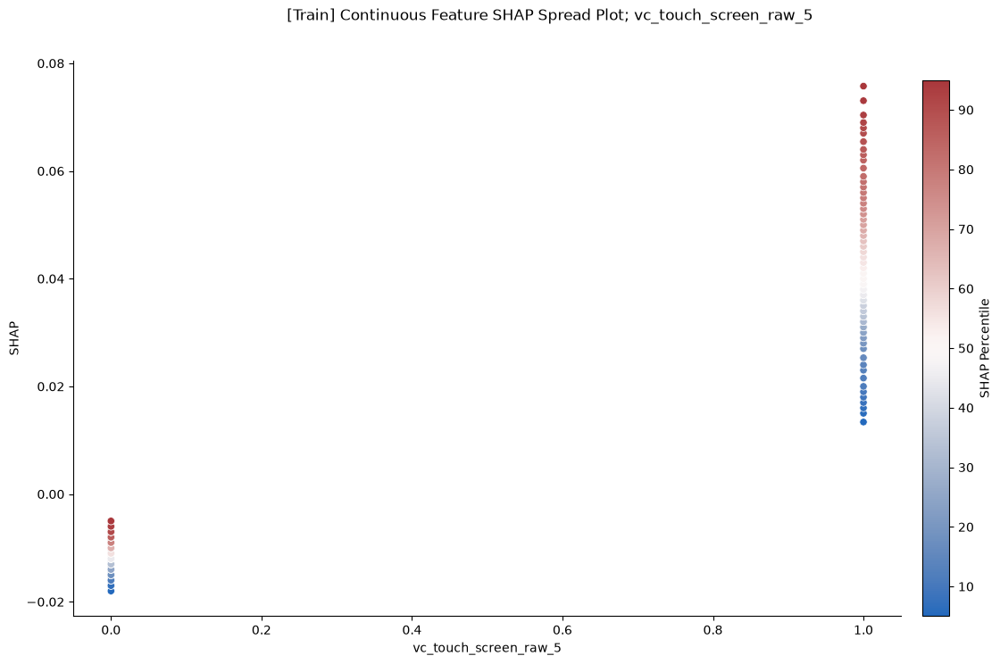

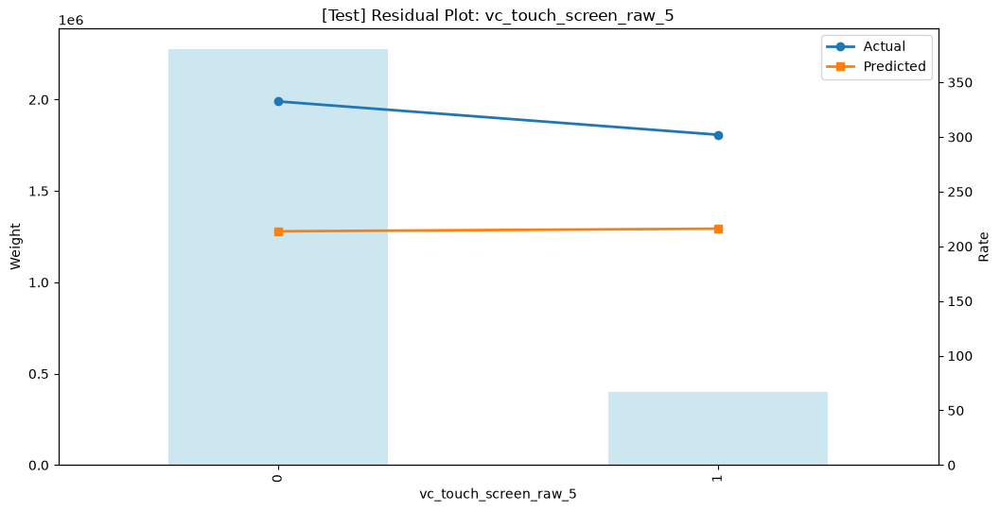

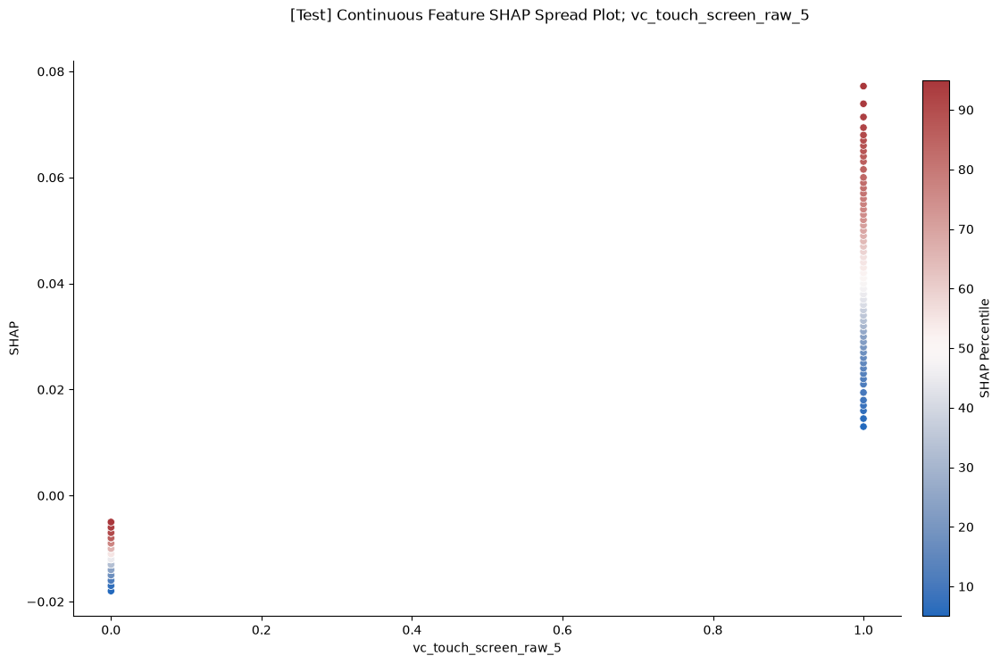


FEATURE: vc_lane_departure_warning_raw


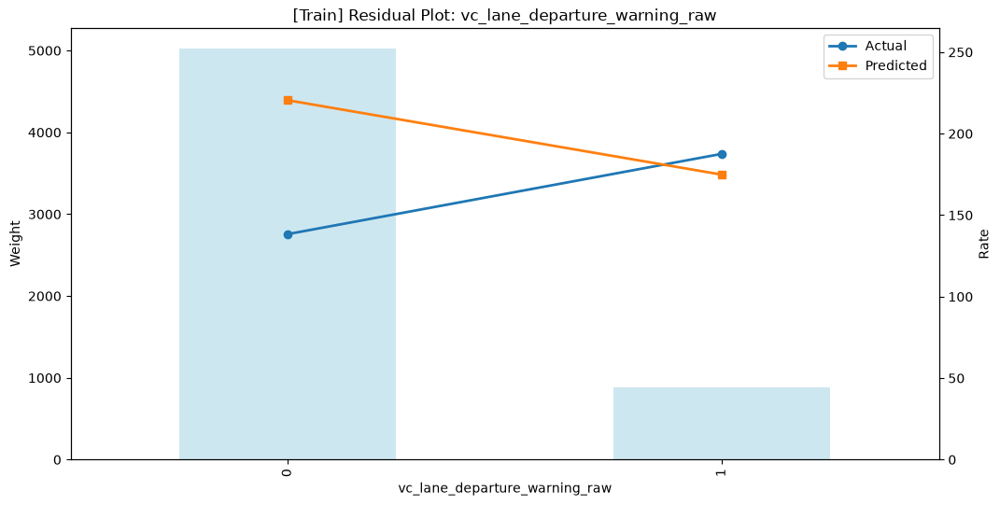

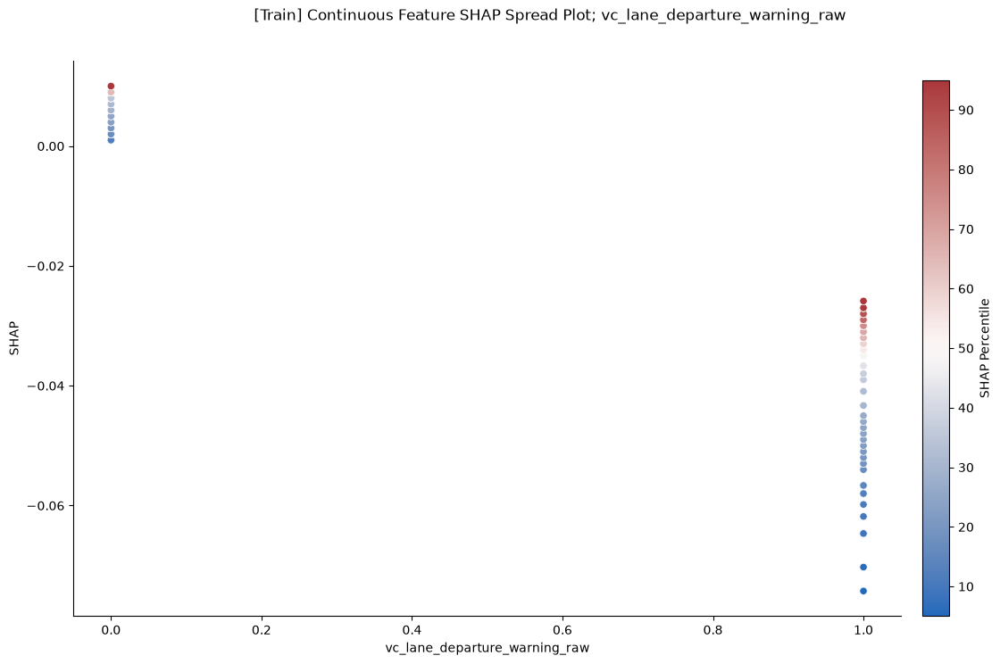

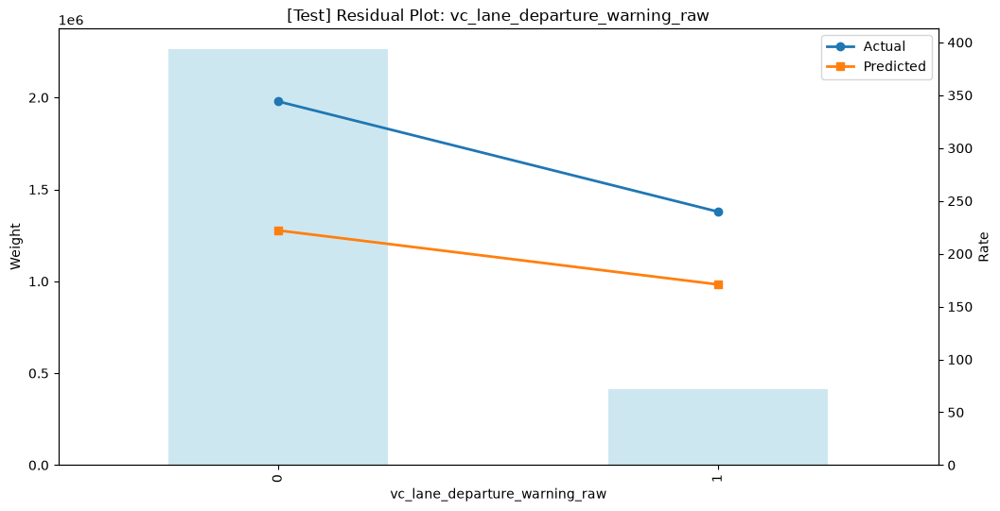

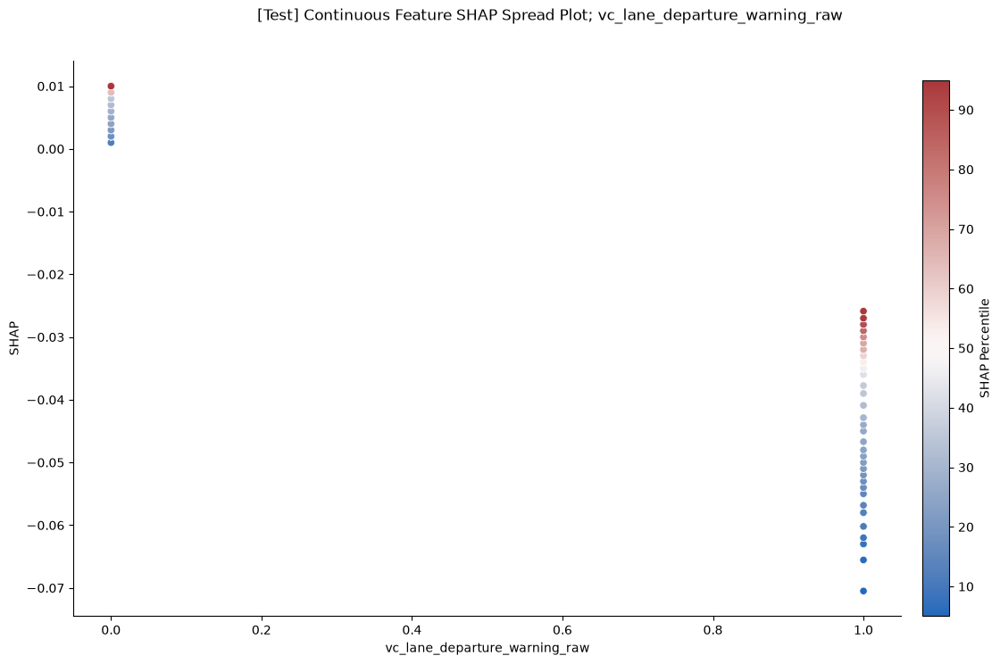


FEATURE: vc_surround_sound_raw_1


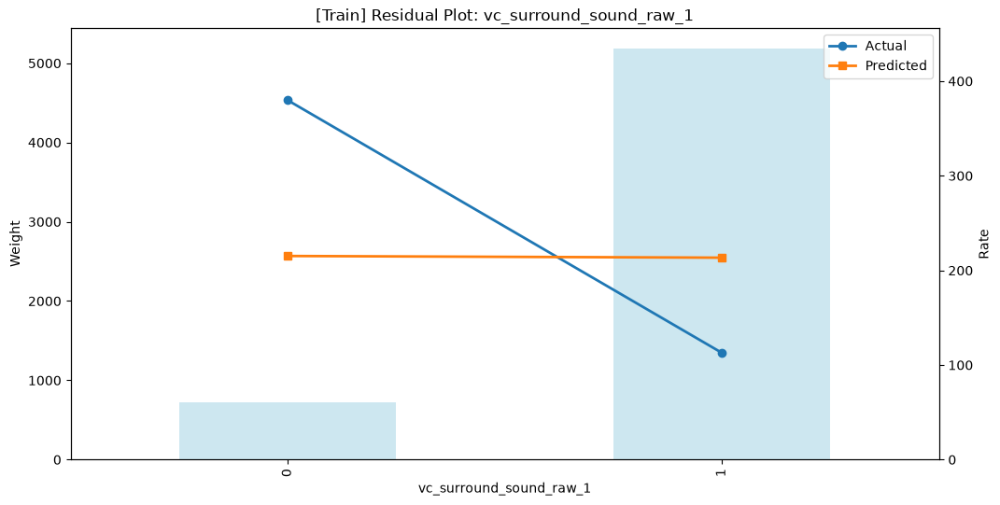

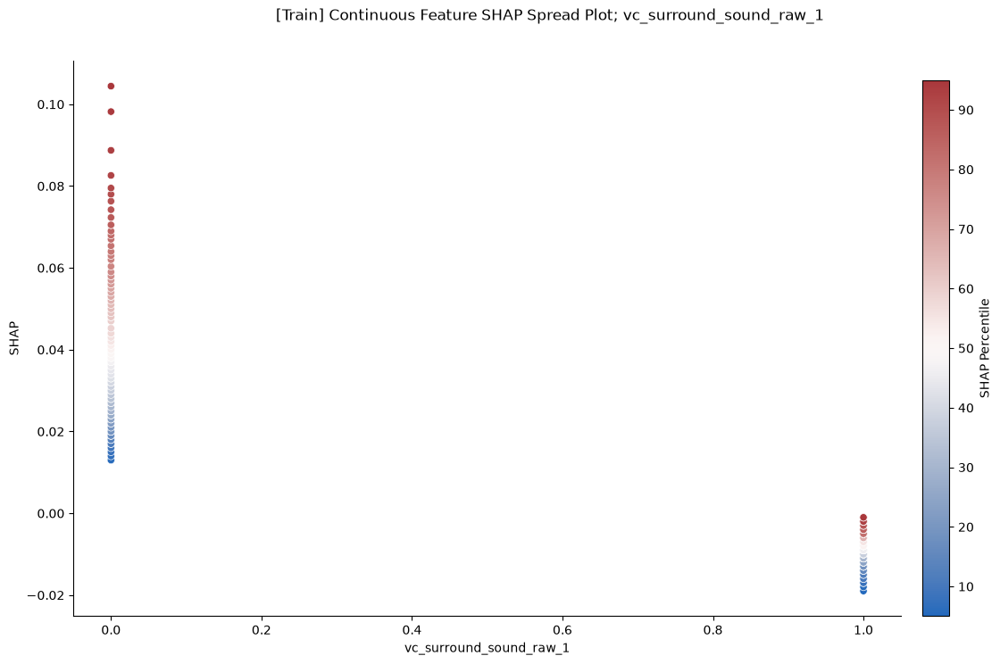

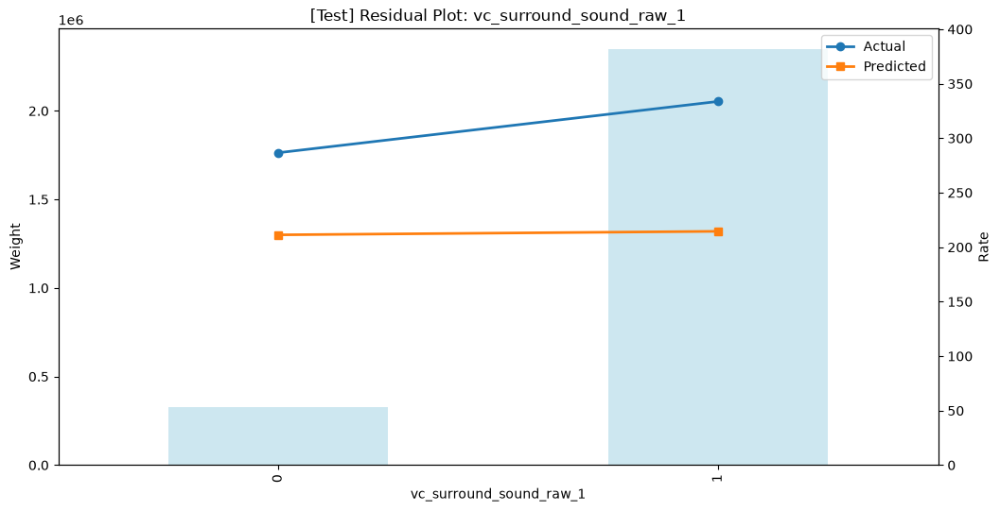

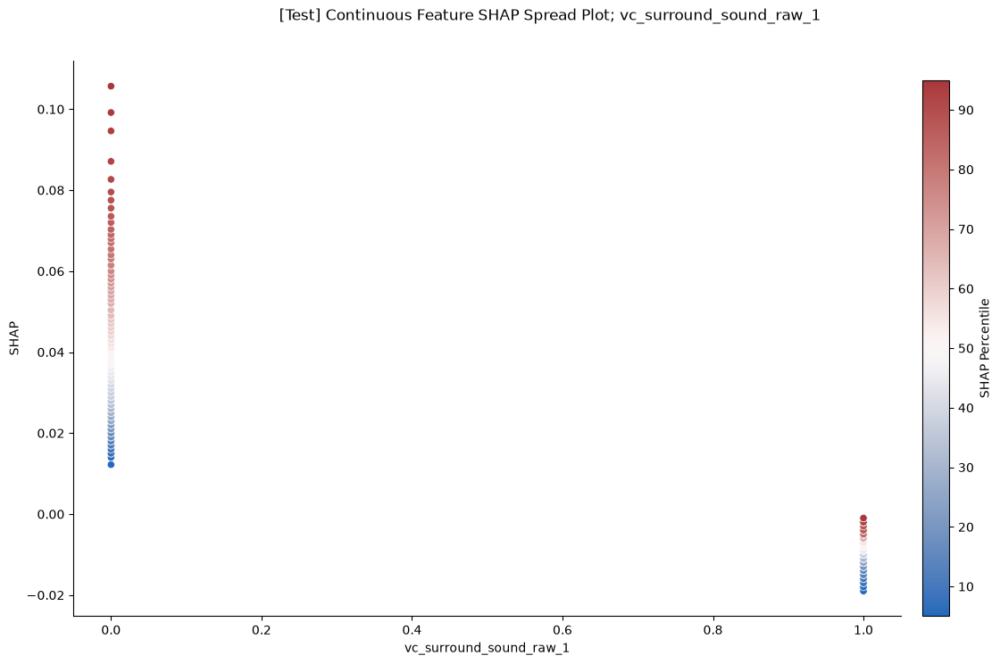


FEATURE: vc_satellite_radio_raw


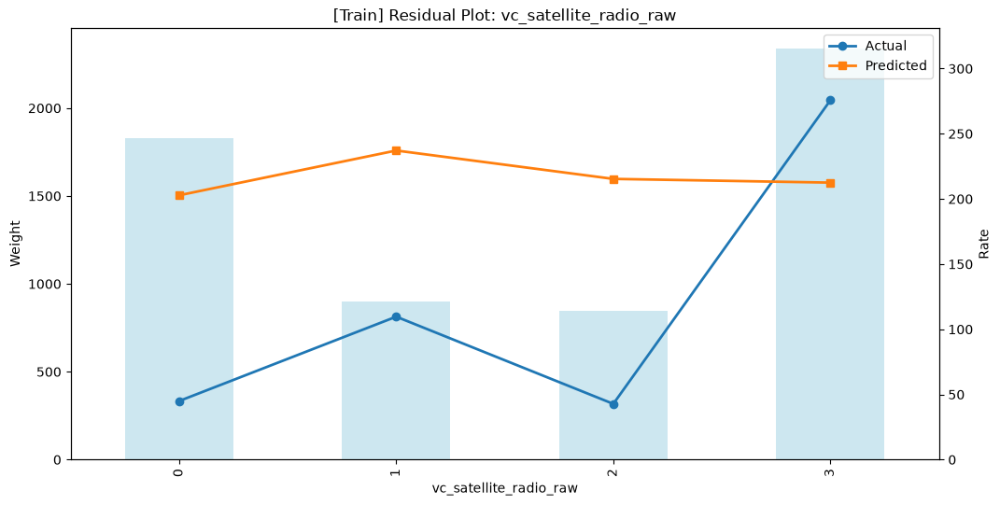

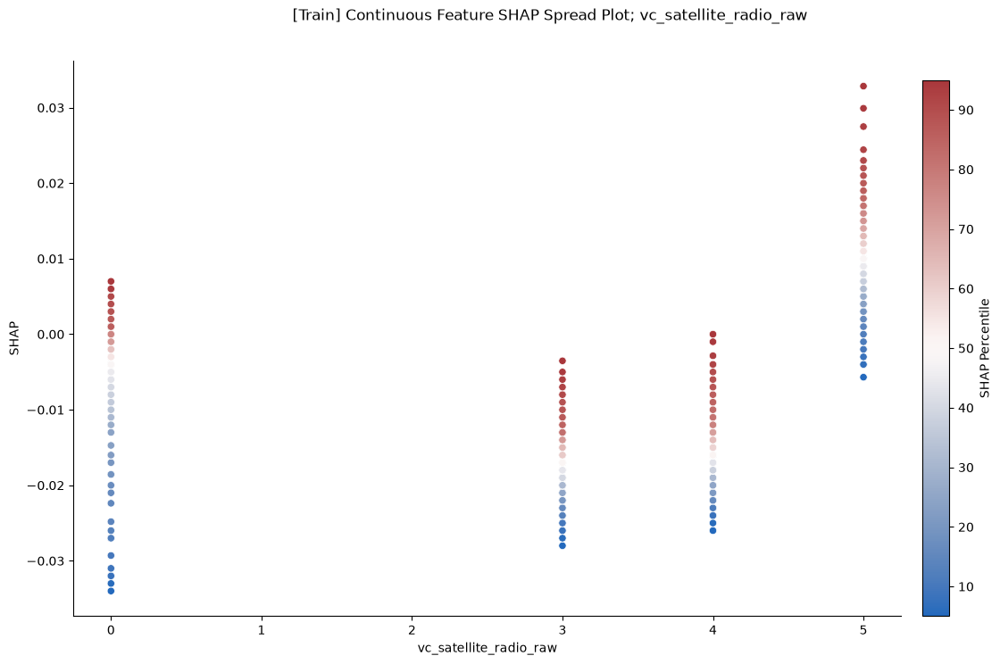

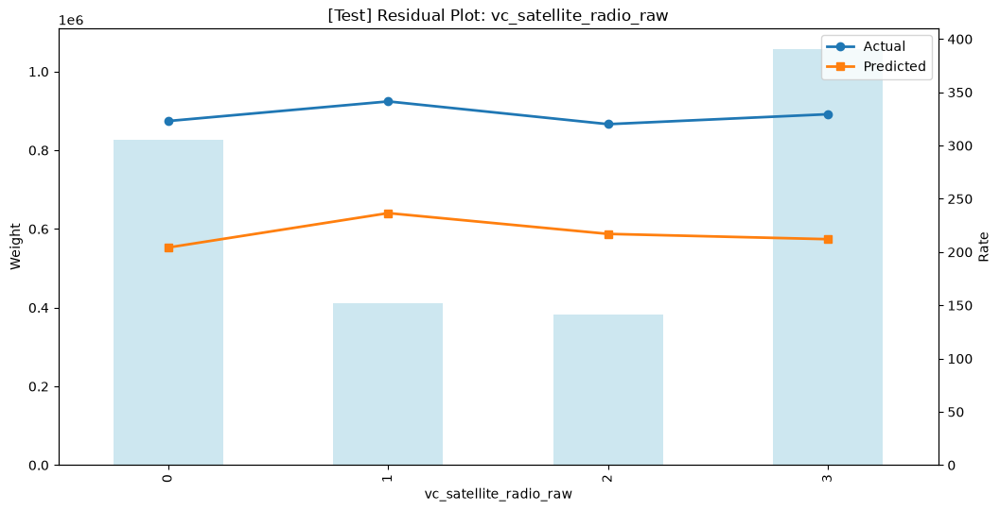

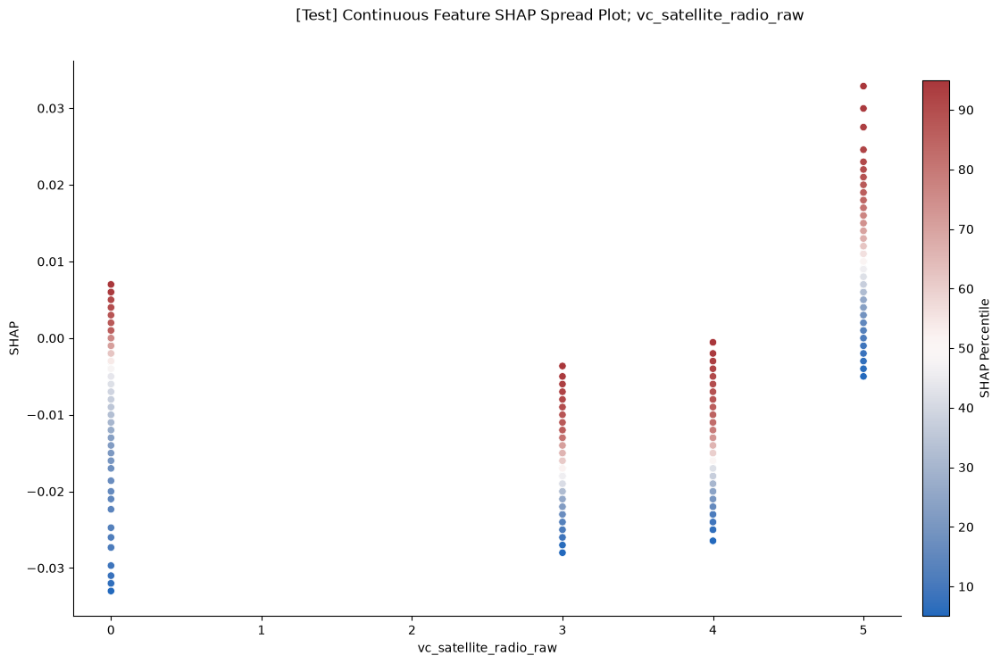


FEATURE: vc_surround_sound_raw_3


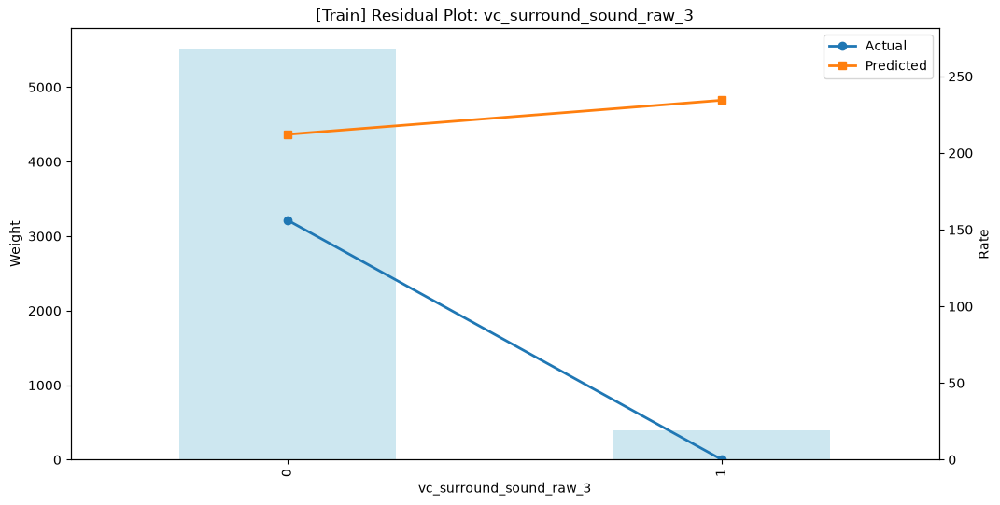

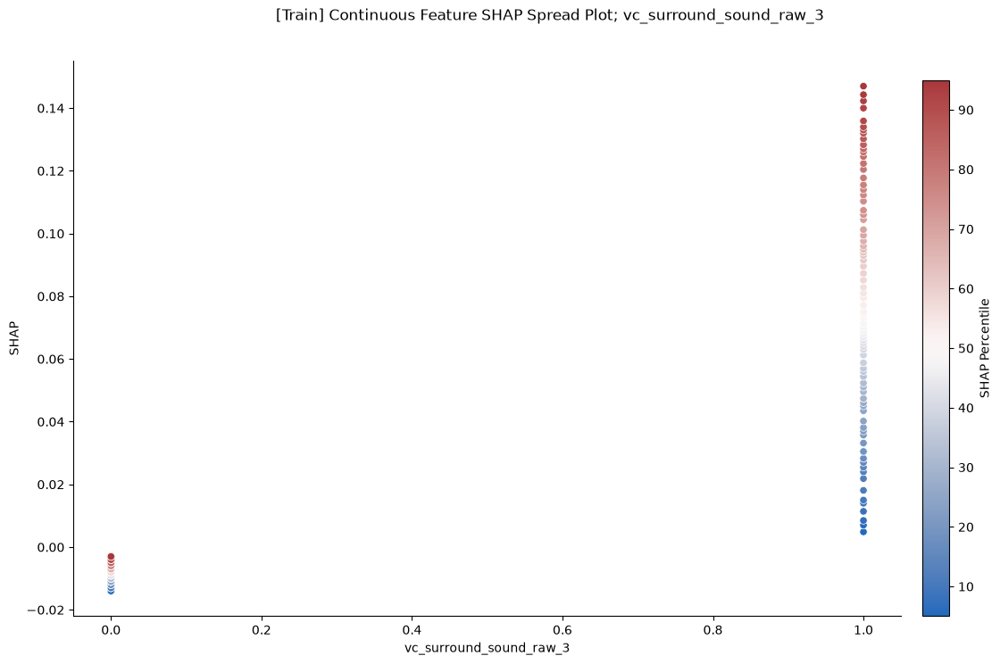

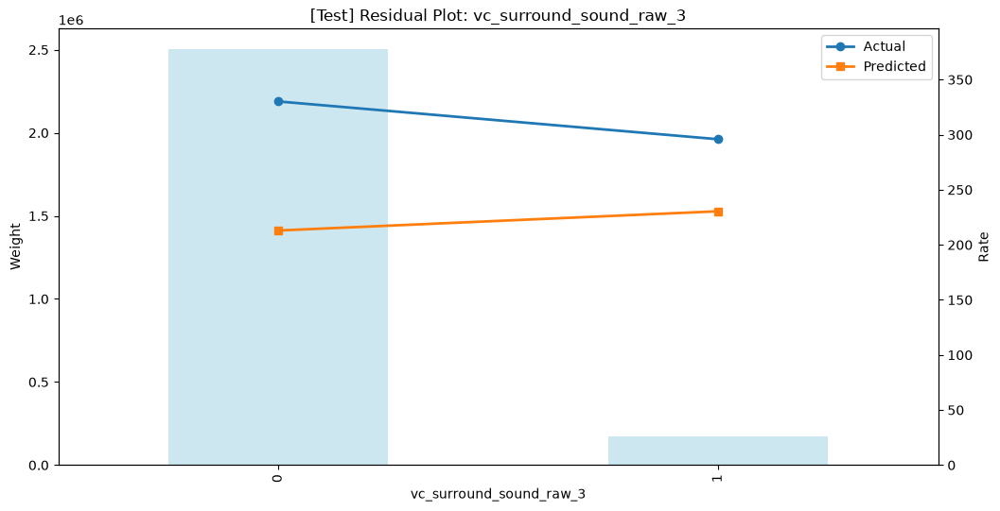

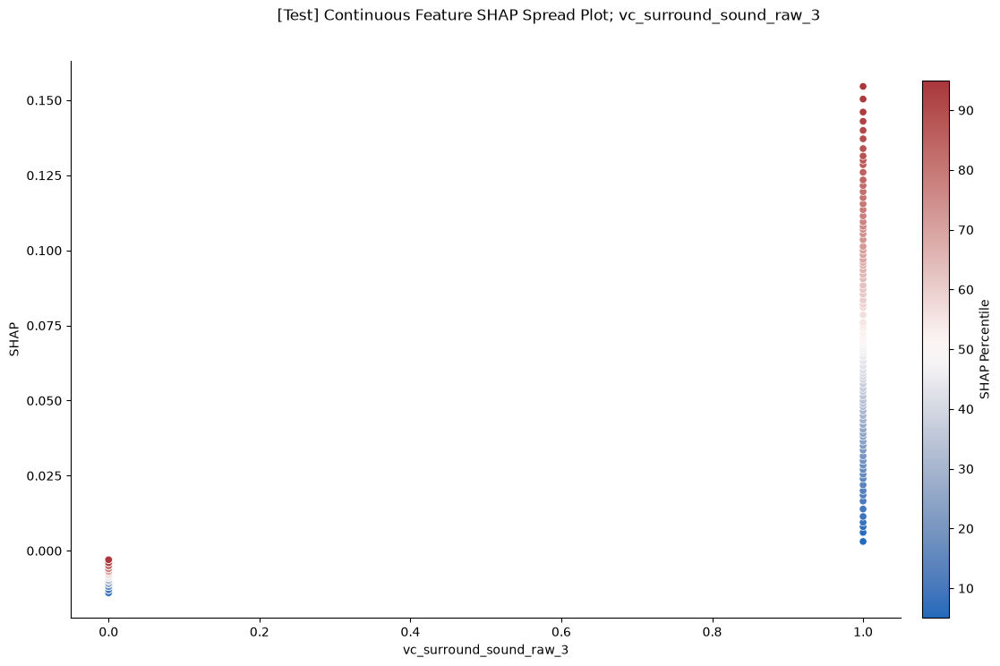


FEATURE: vc_touch_screen_raw_4


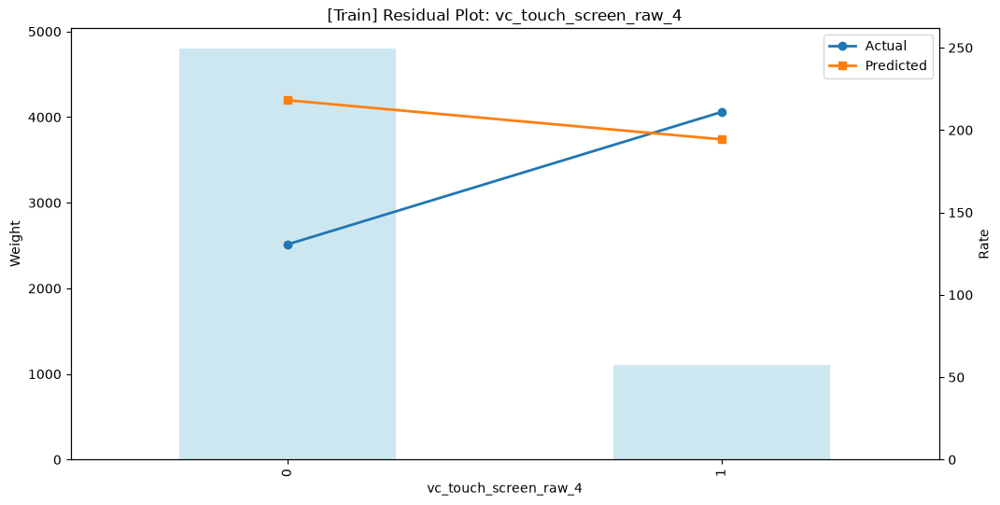

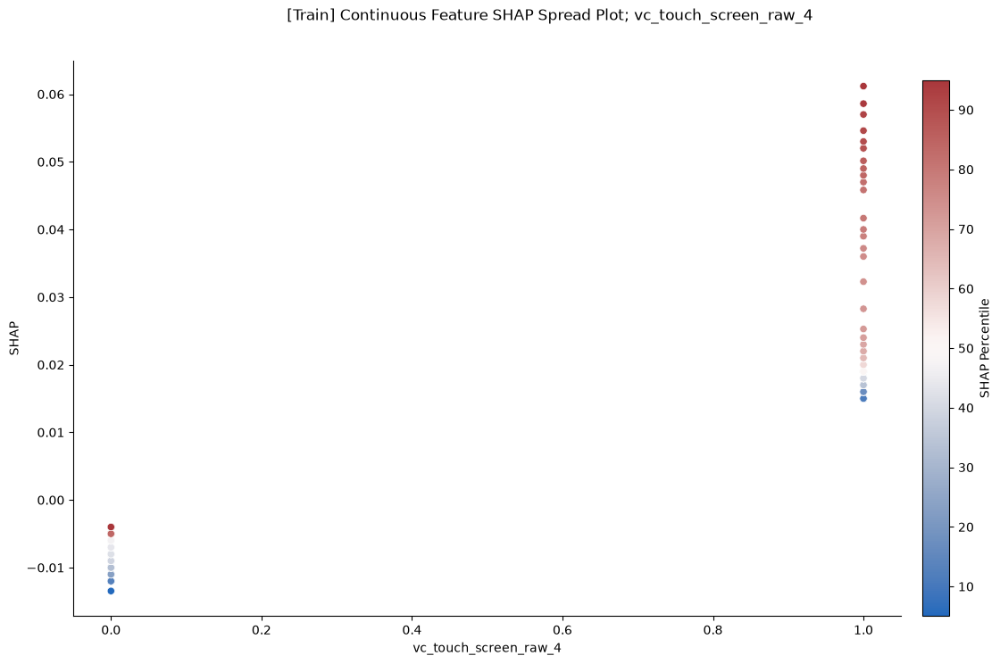

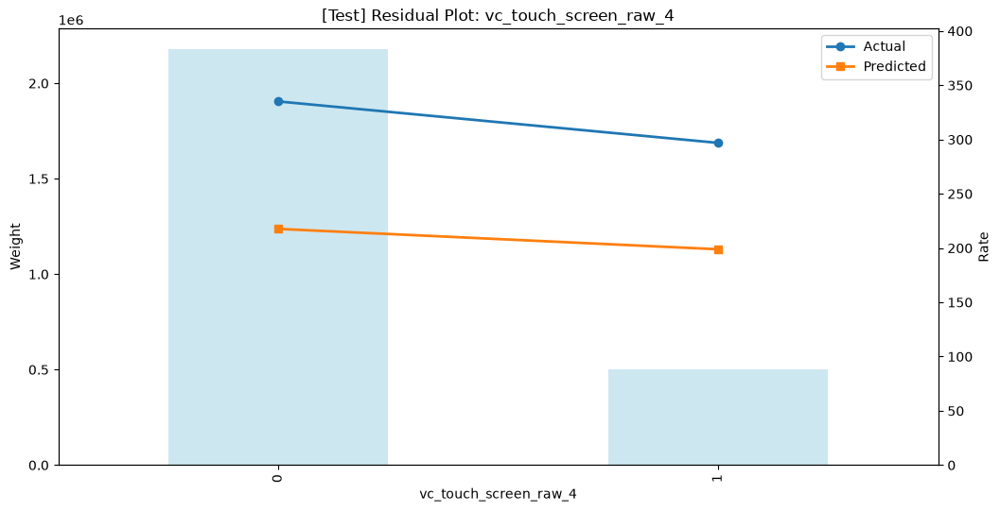

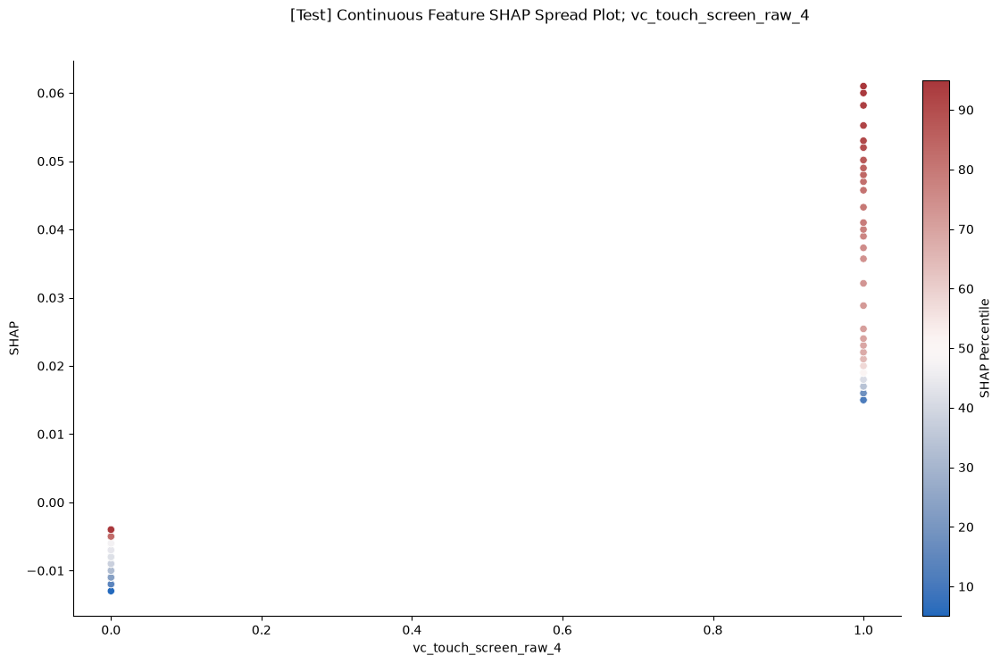


FEATURE: vc_taillights_led_raw


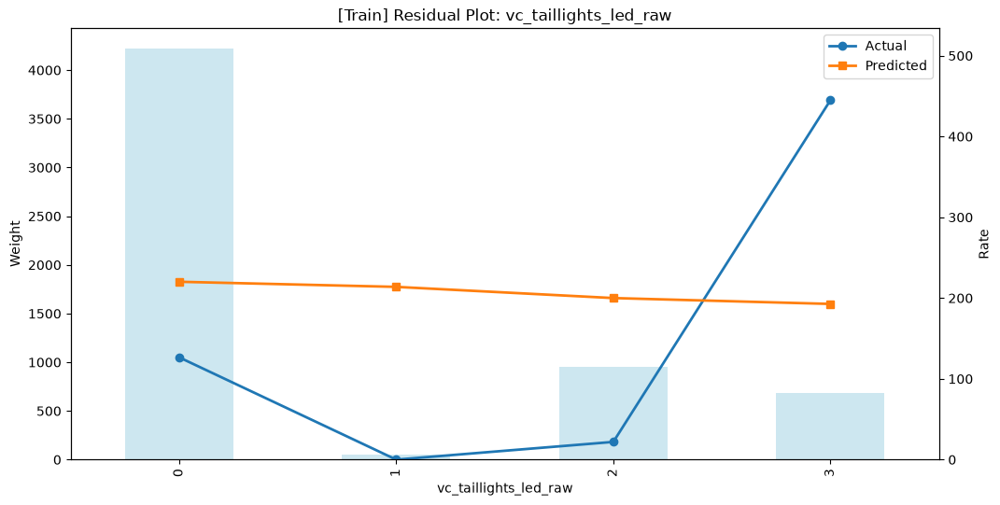

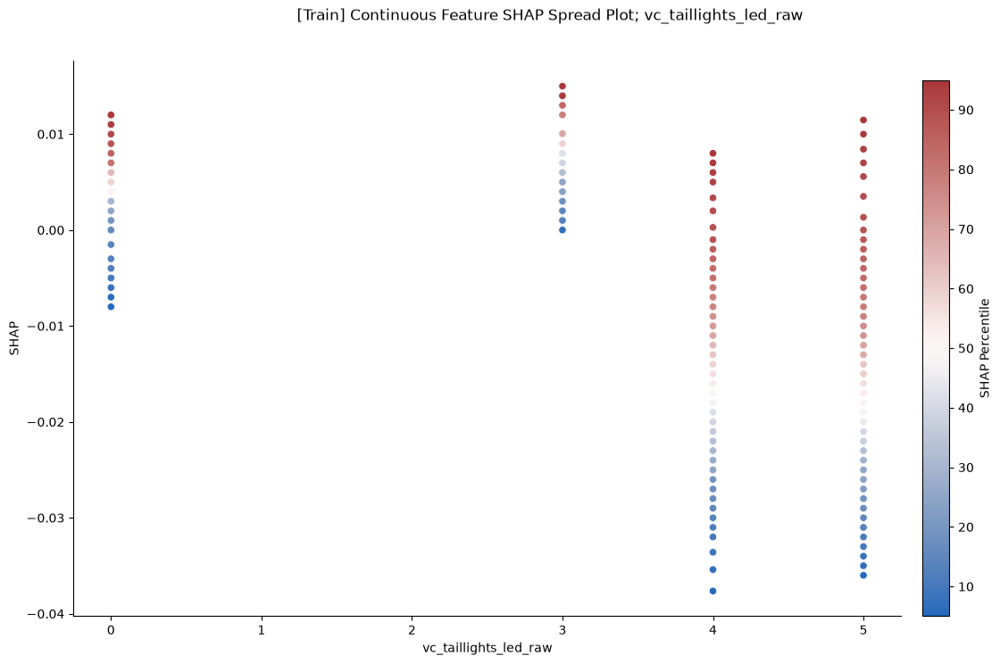

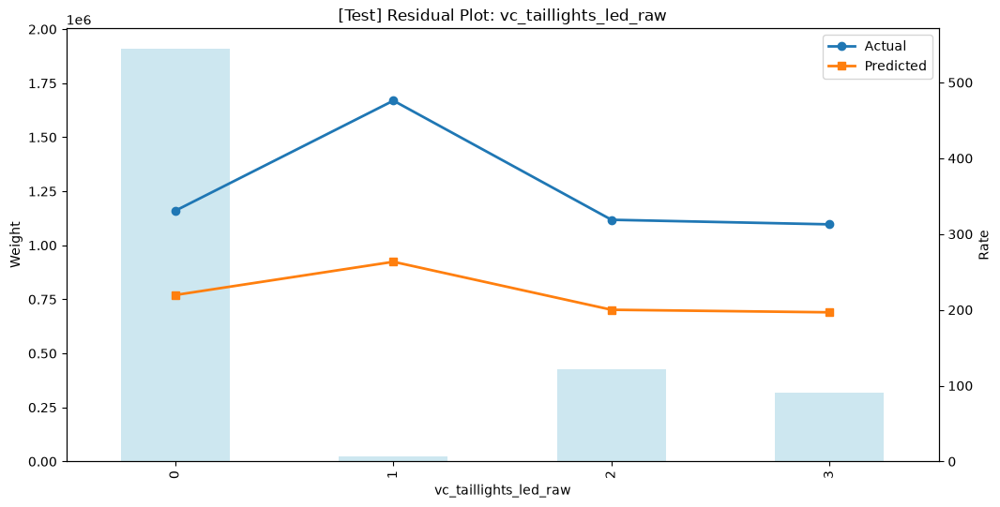

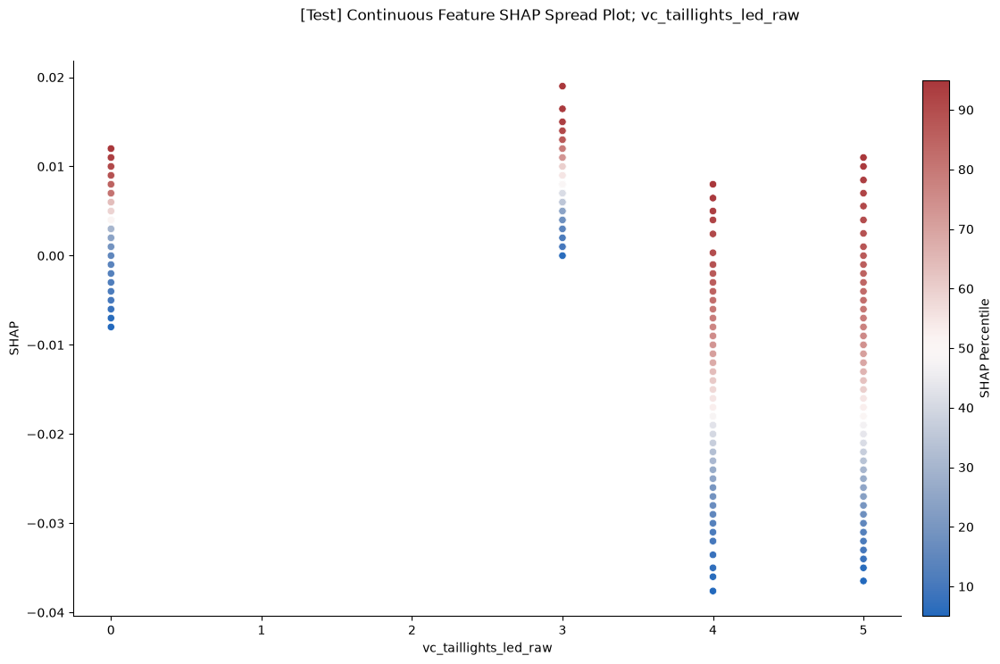


FEATURE: vc_adaptive_cruise_control_raw_5


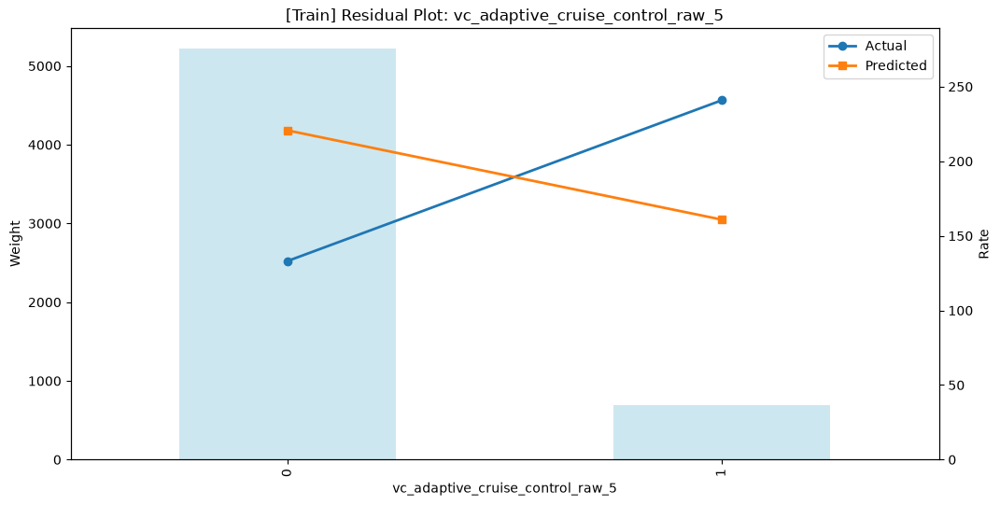

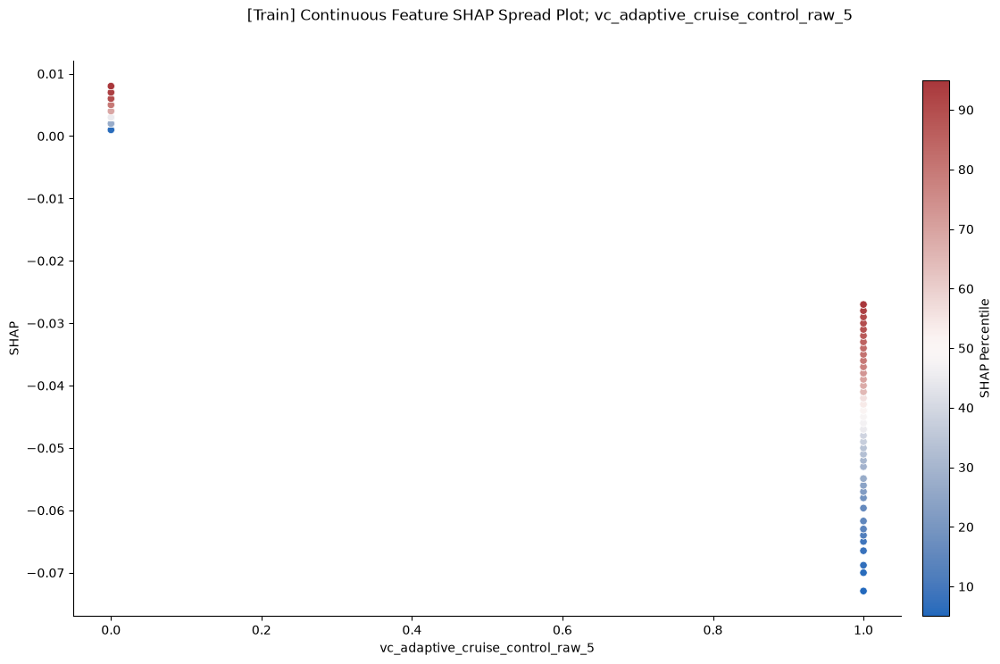

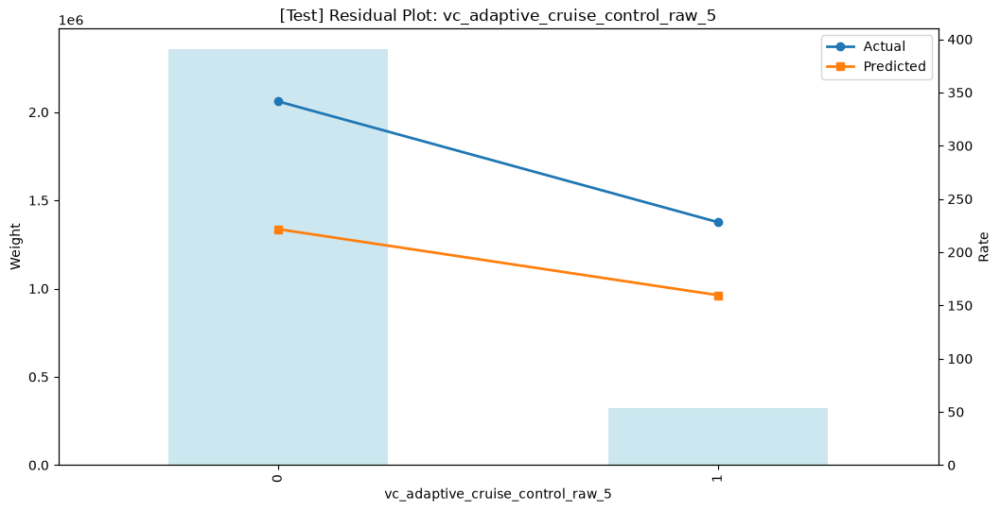

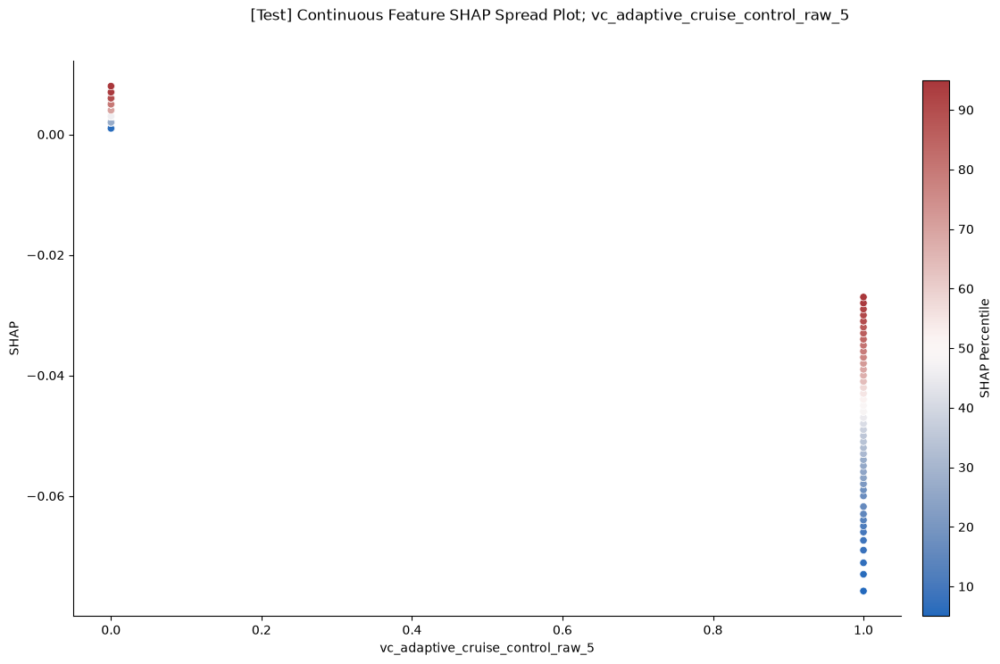


FEATURE: vc_auto_start_stop_raw_5


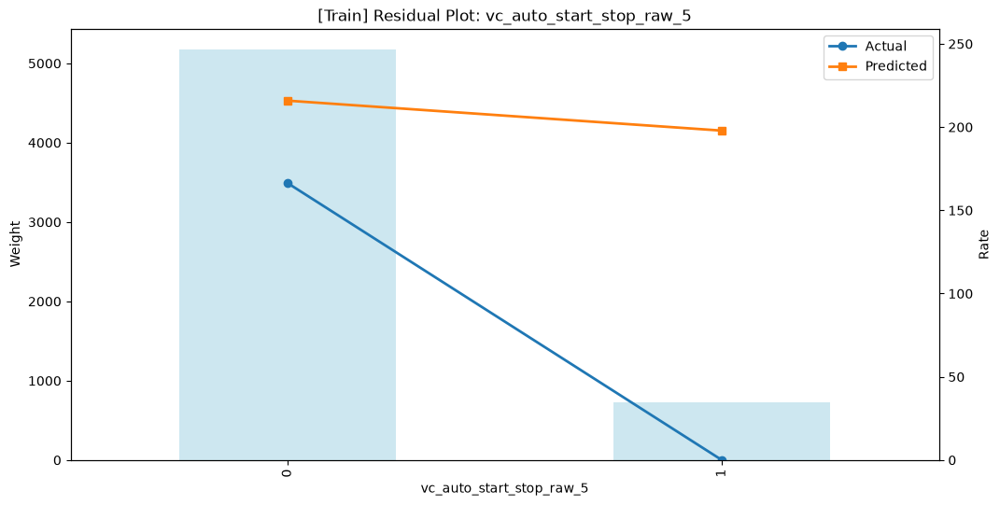

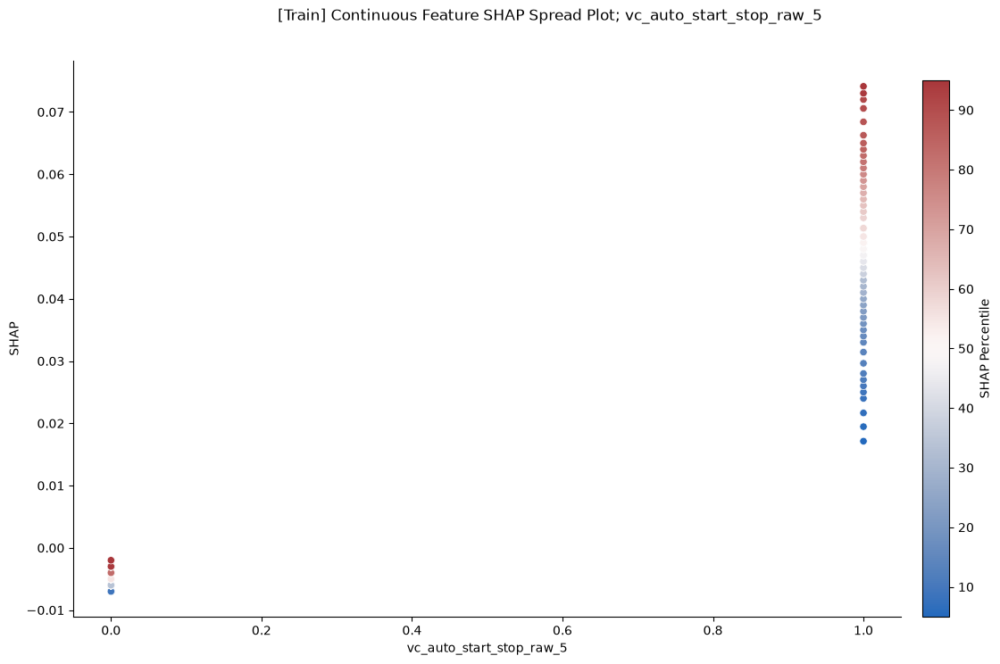

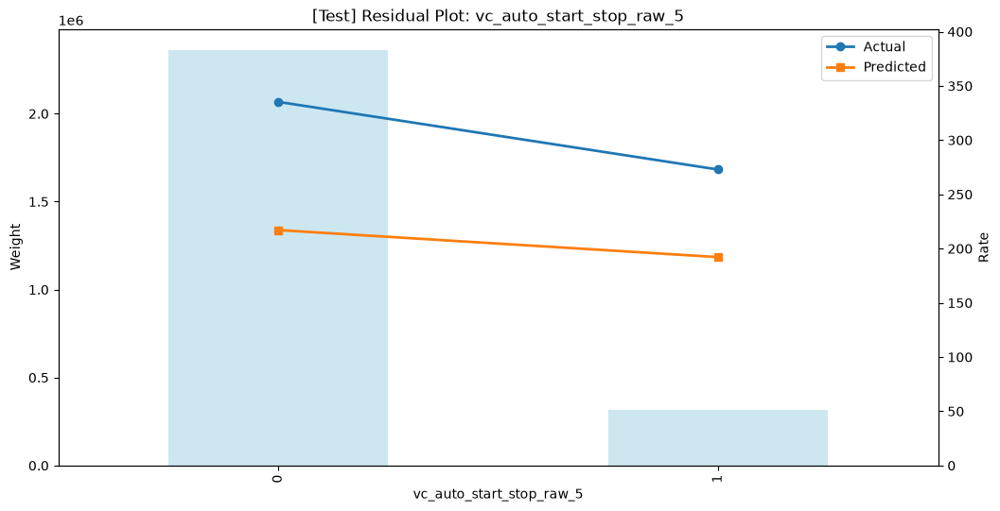

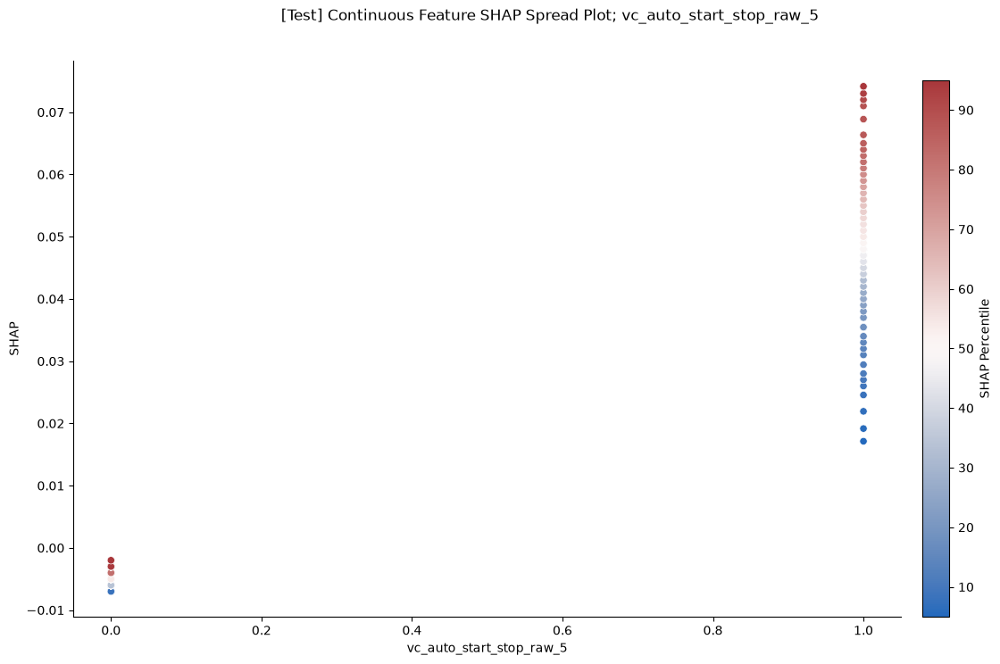


FEATURE: vc_speed_sensitive_volume_raw


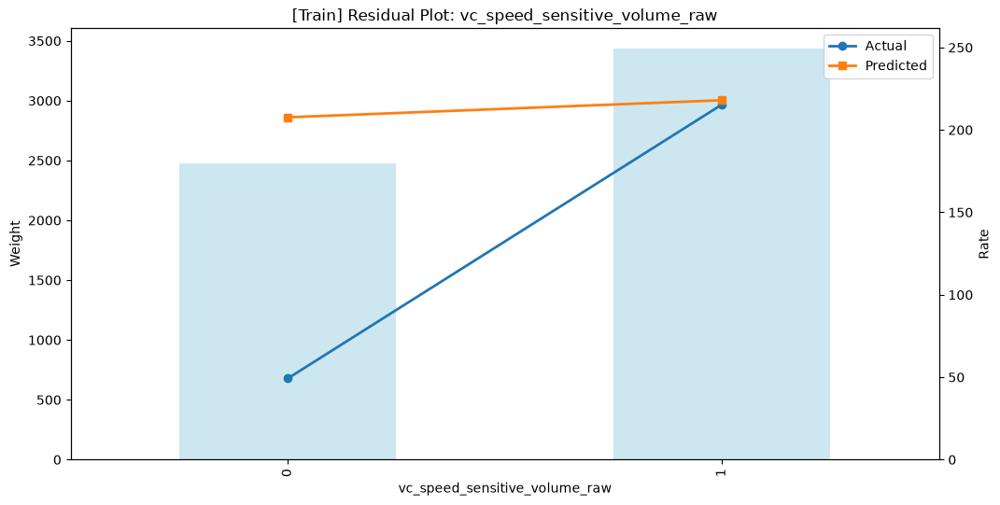

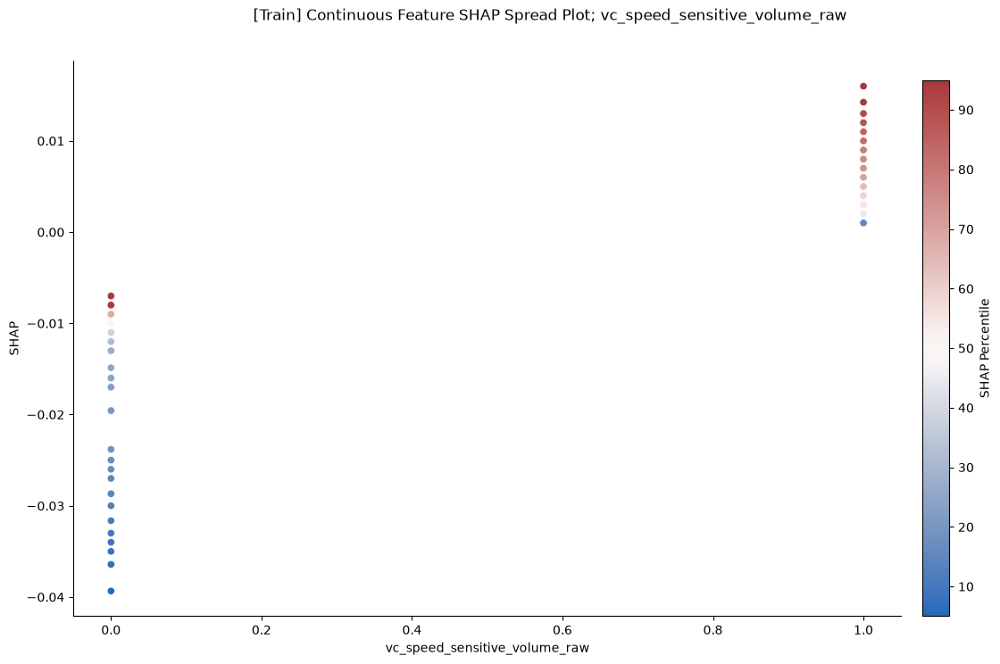

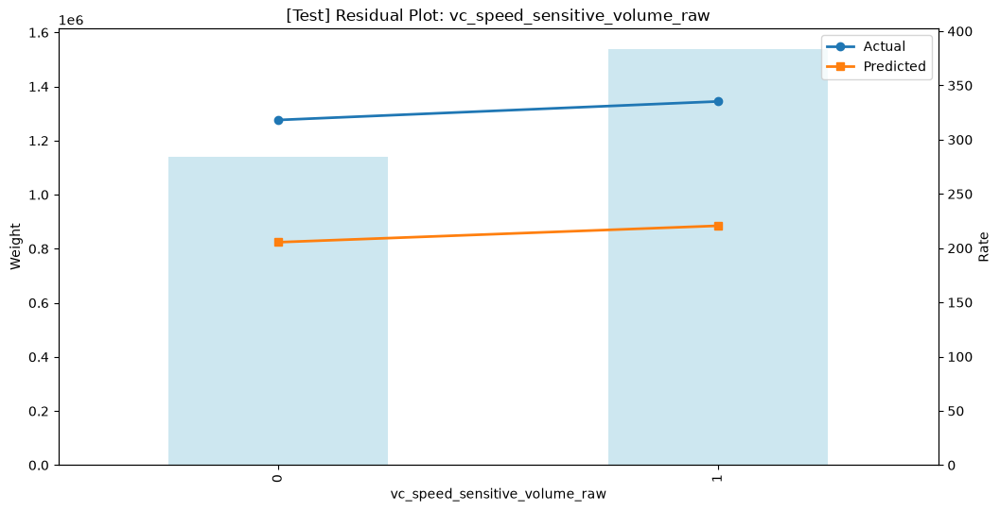

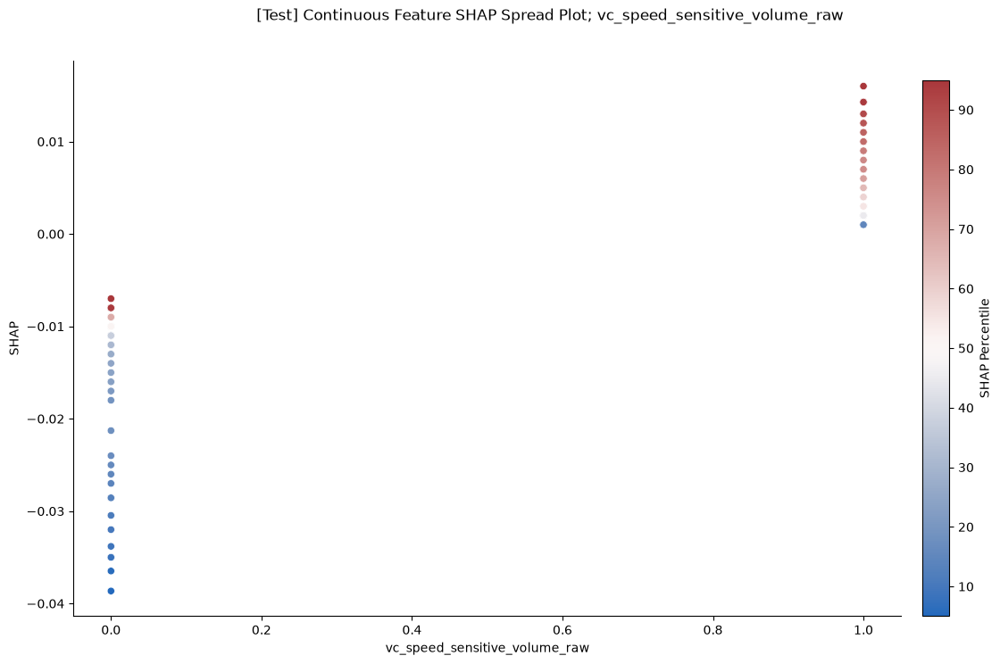


FEATURE: vc_active_collision_avoidance_system_raw_5


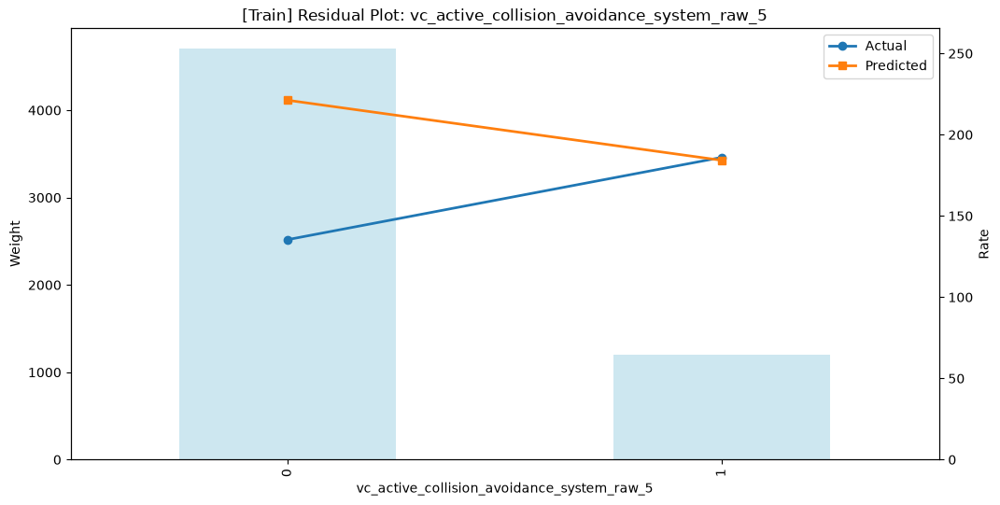

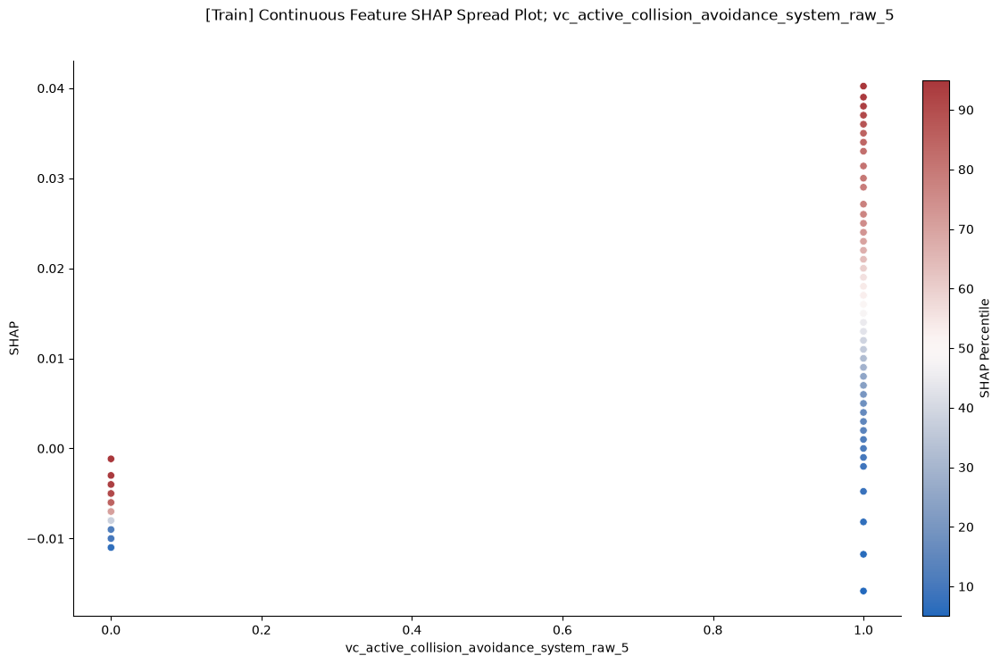

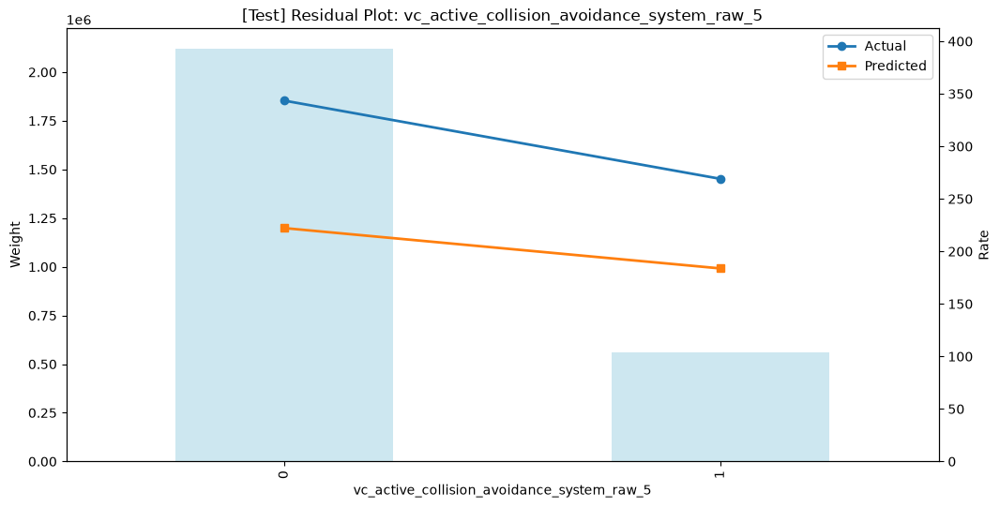

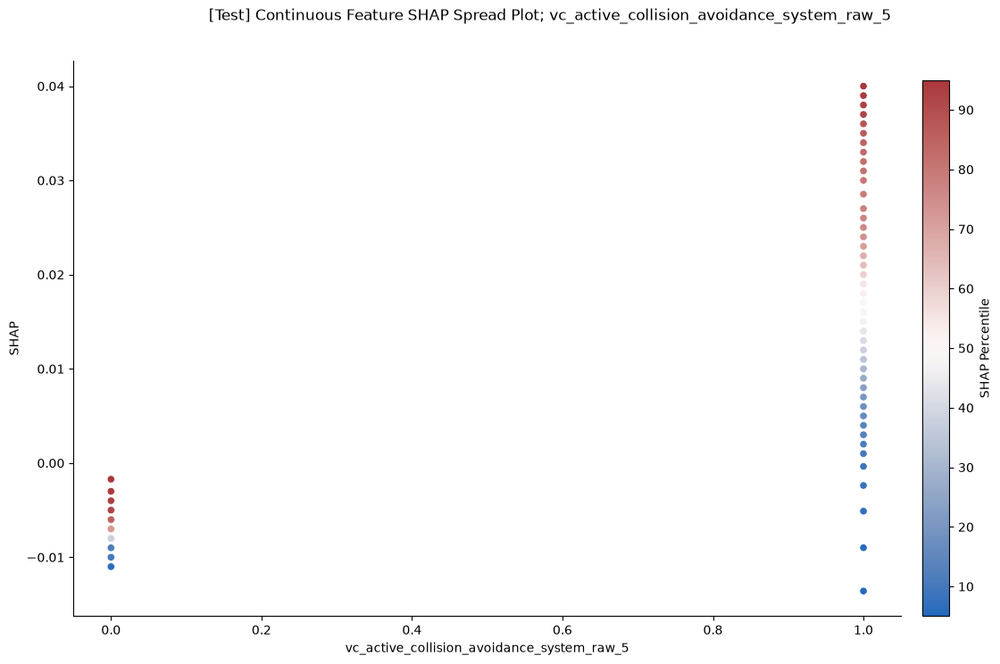


FEATURE: vc_power_sunroof_raw_0


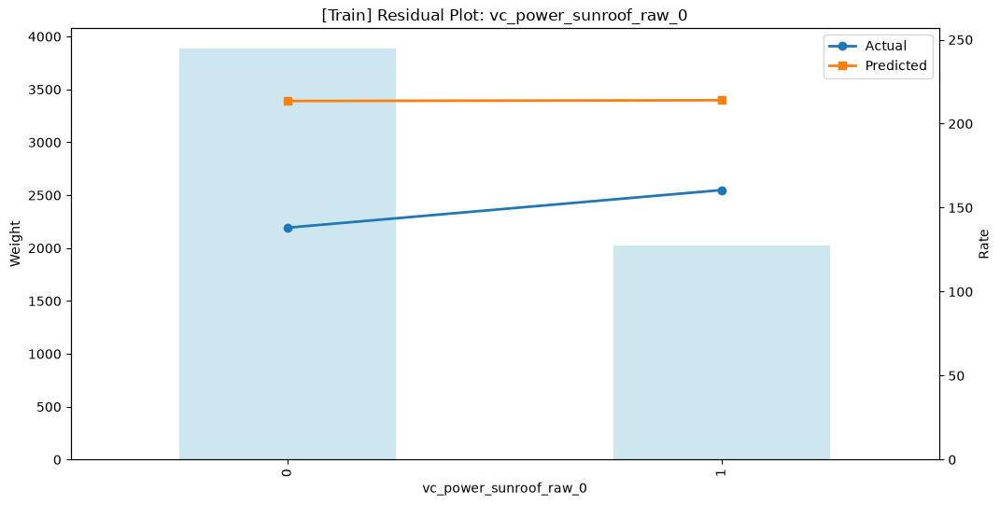

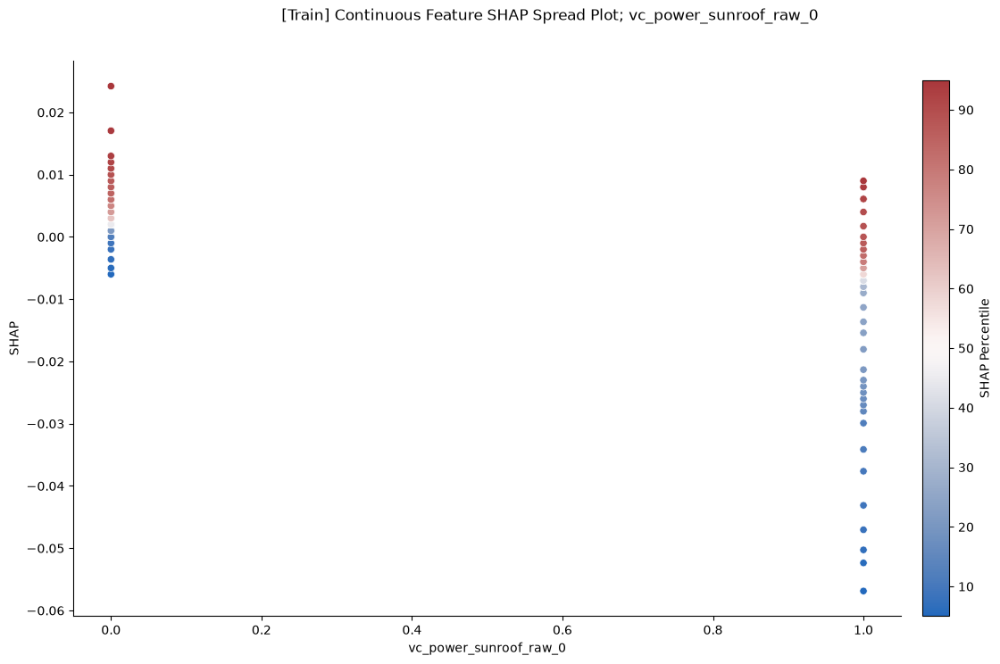

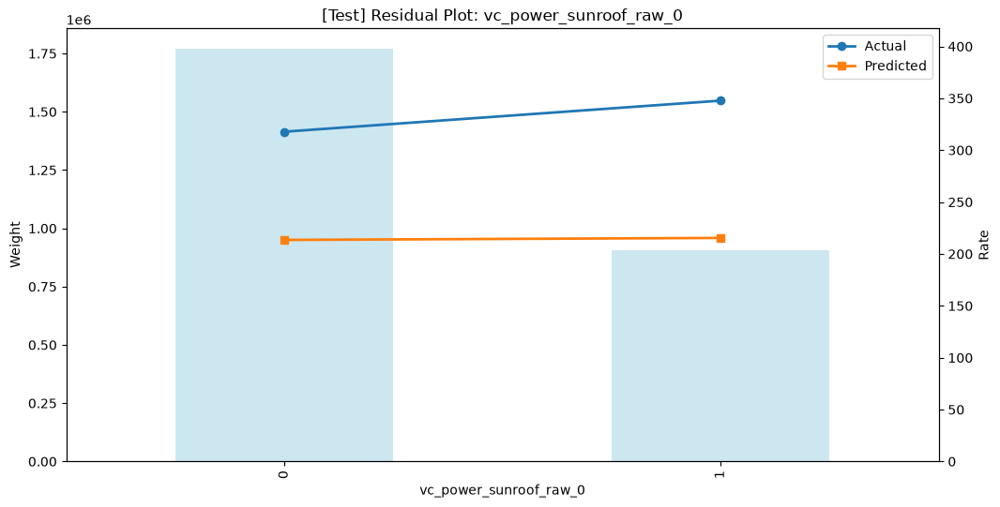

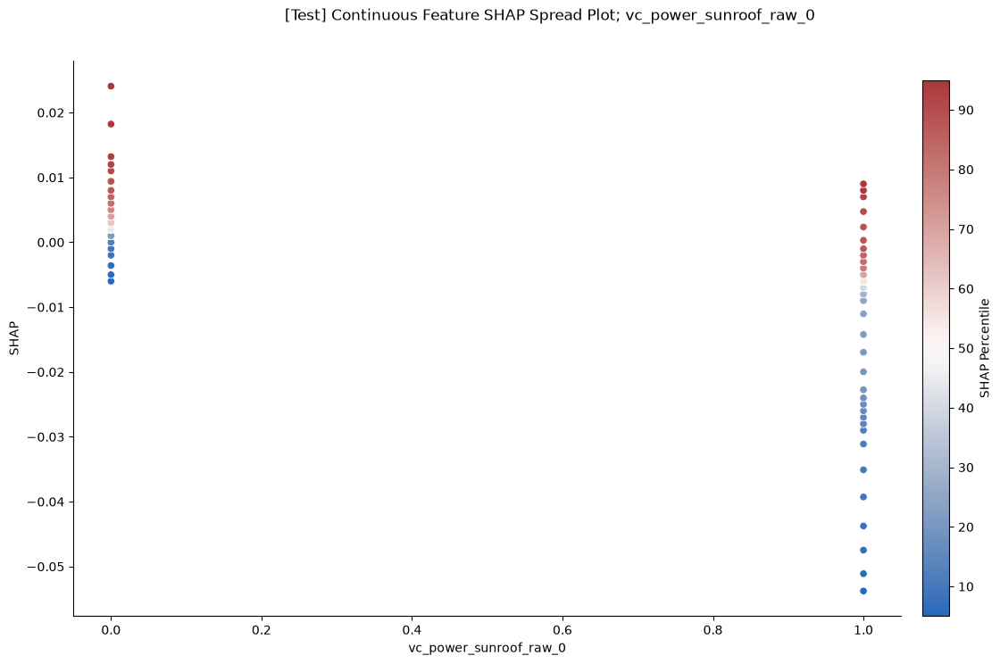


FEATURE: vc_adaptive_cruise_control_raw_0


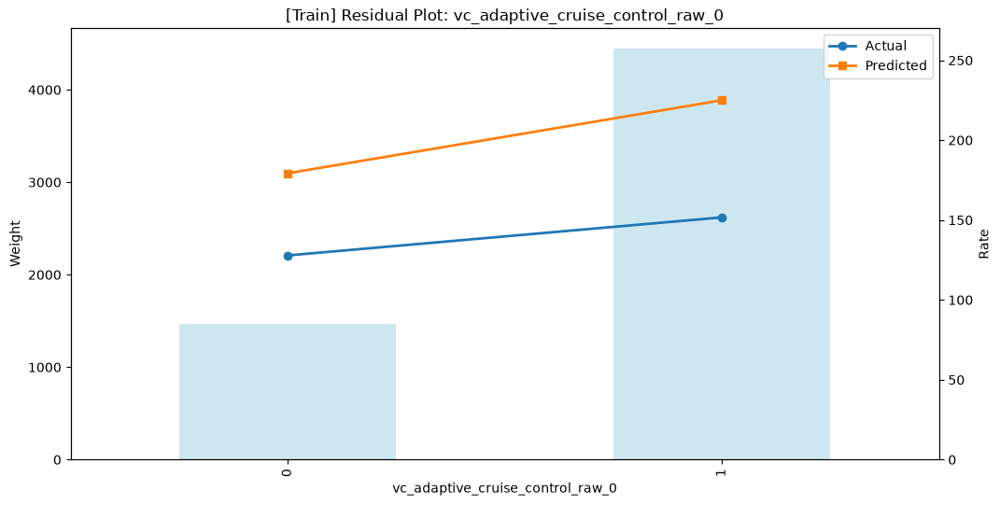

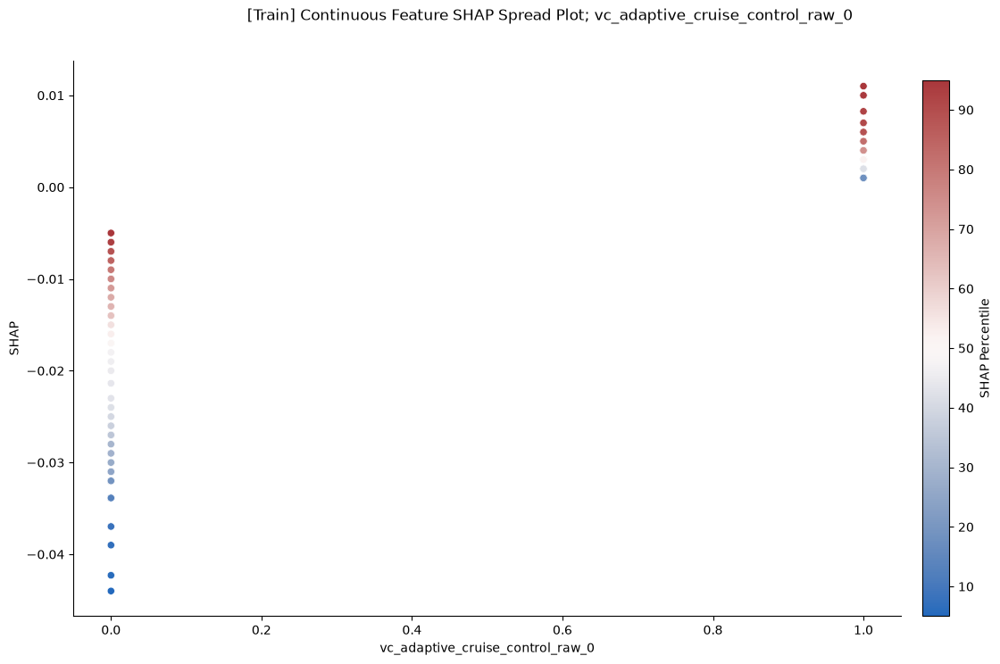

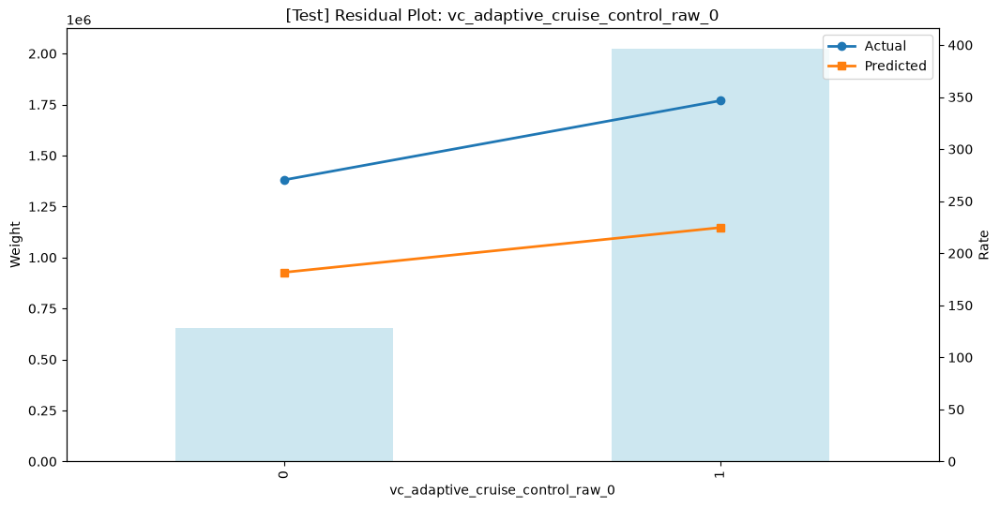

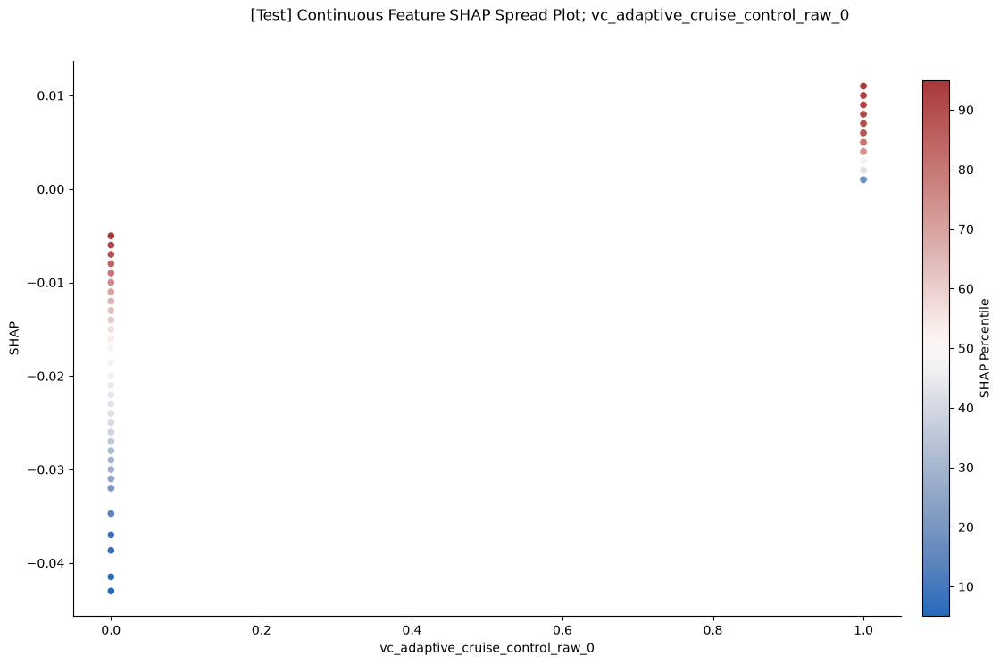


FEATURE: vc_heated_steering_wheel_raw


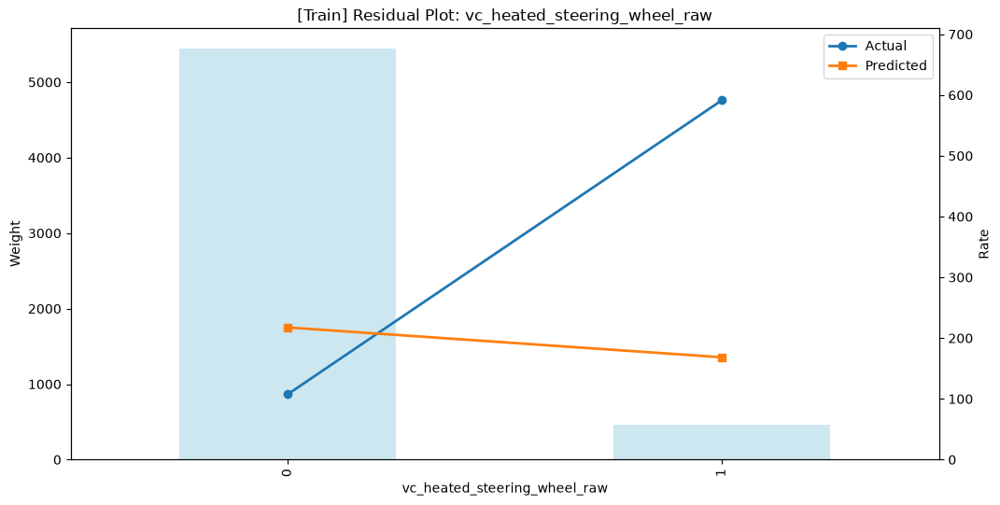

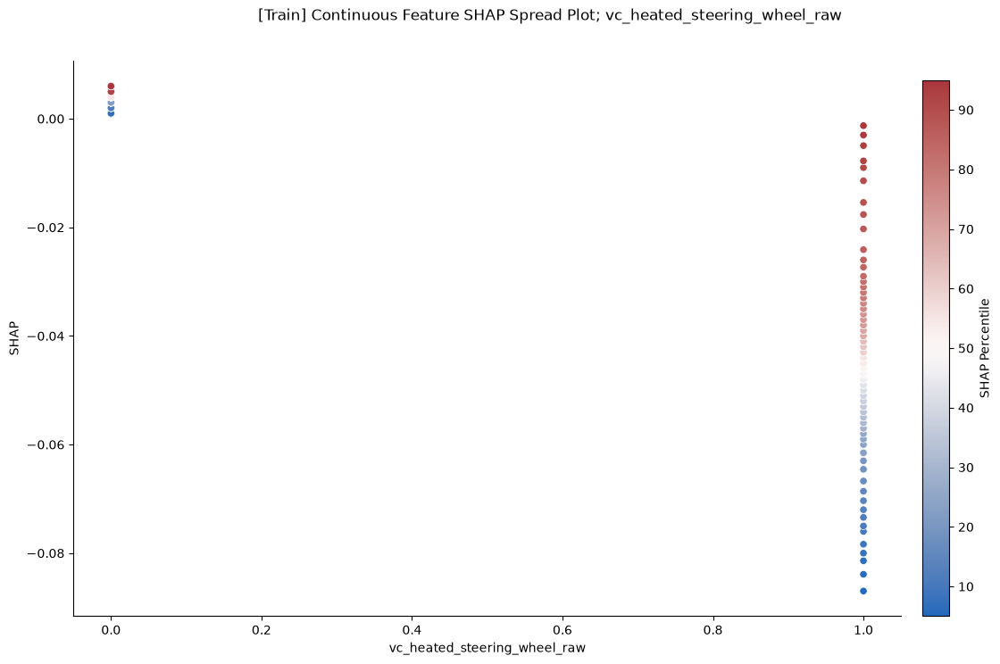

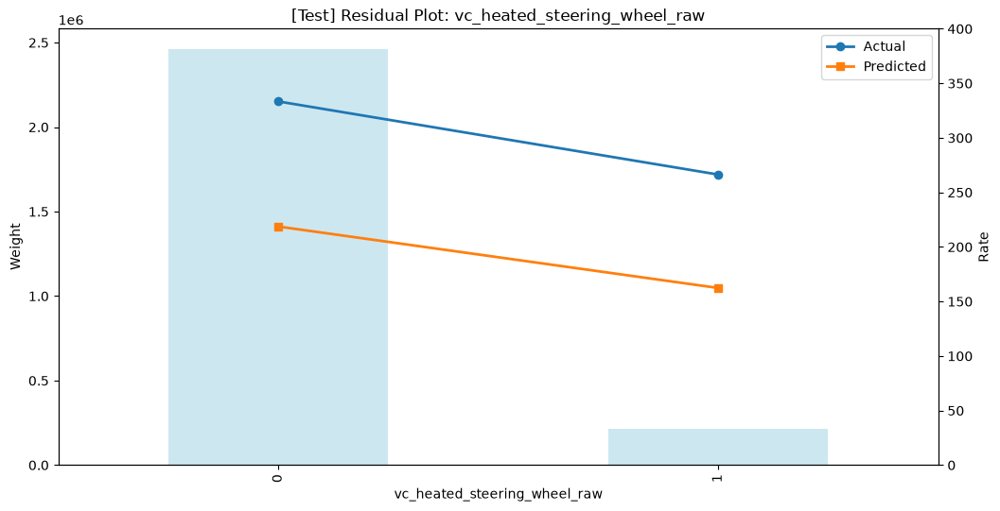

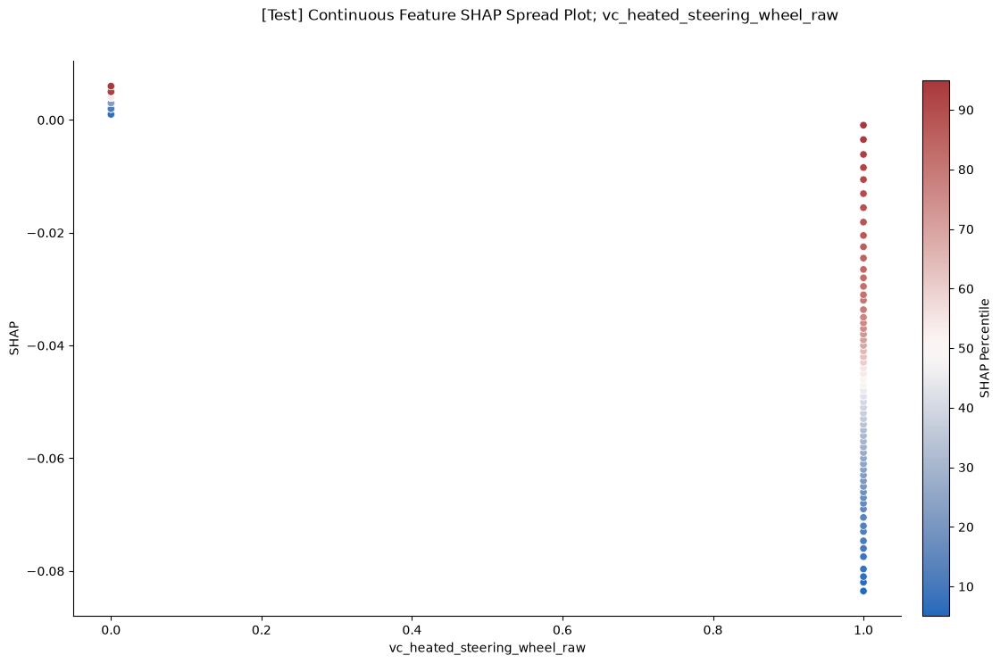


FEATURE: vc_electronic_braking_system_raw_5


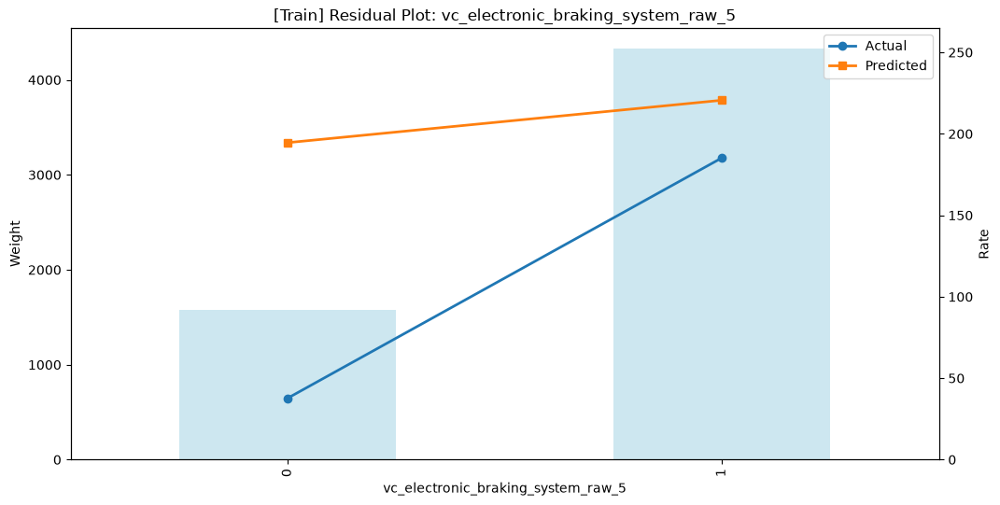

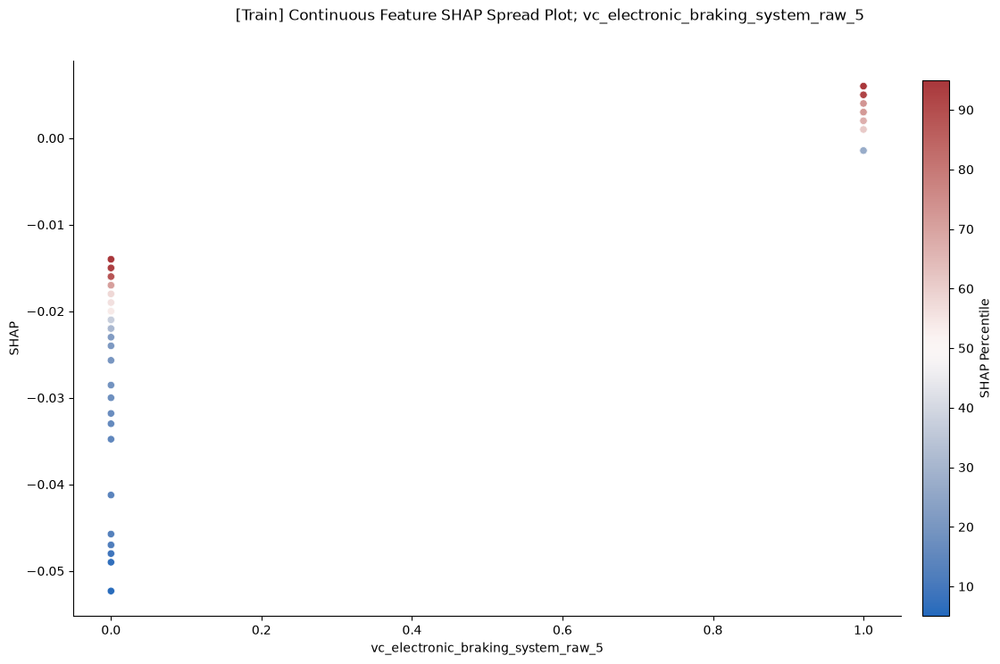

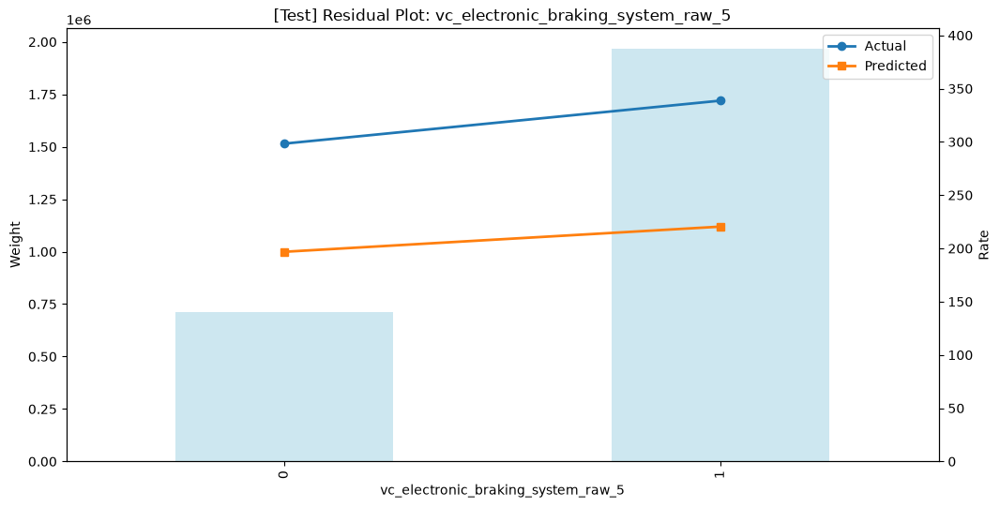

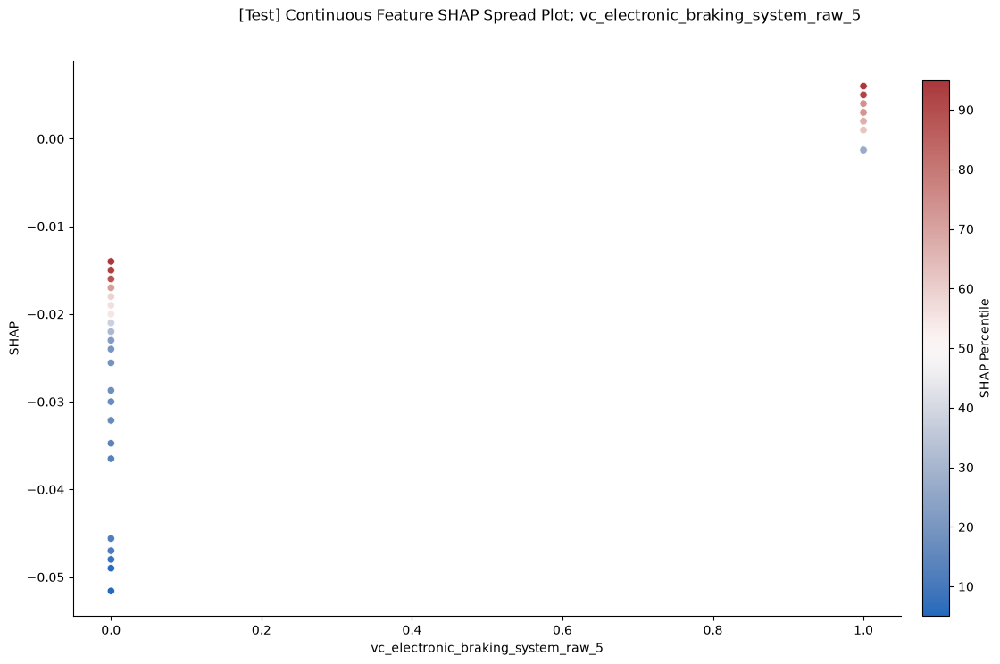


FEATURE: vc_hill_ascent_assist_raw_5


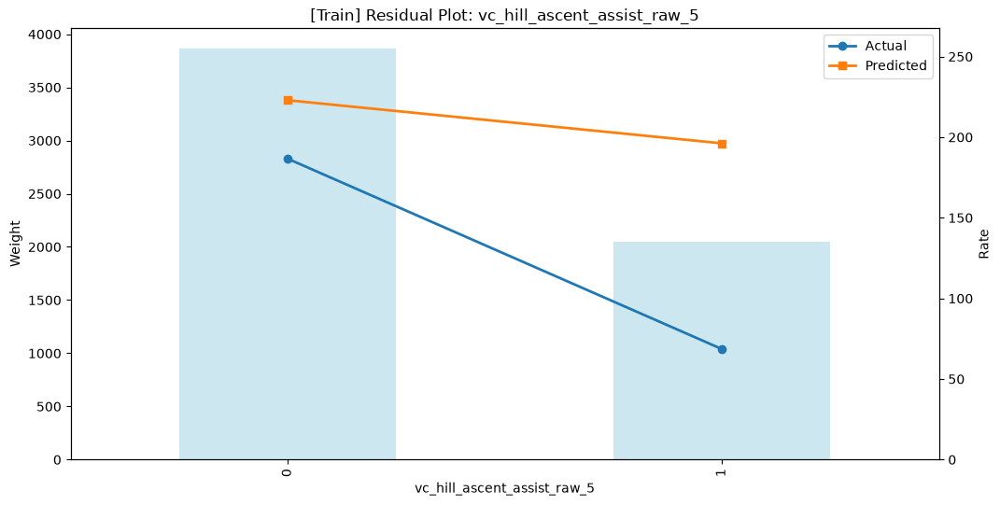

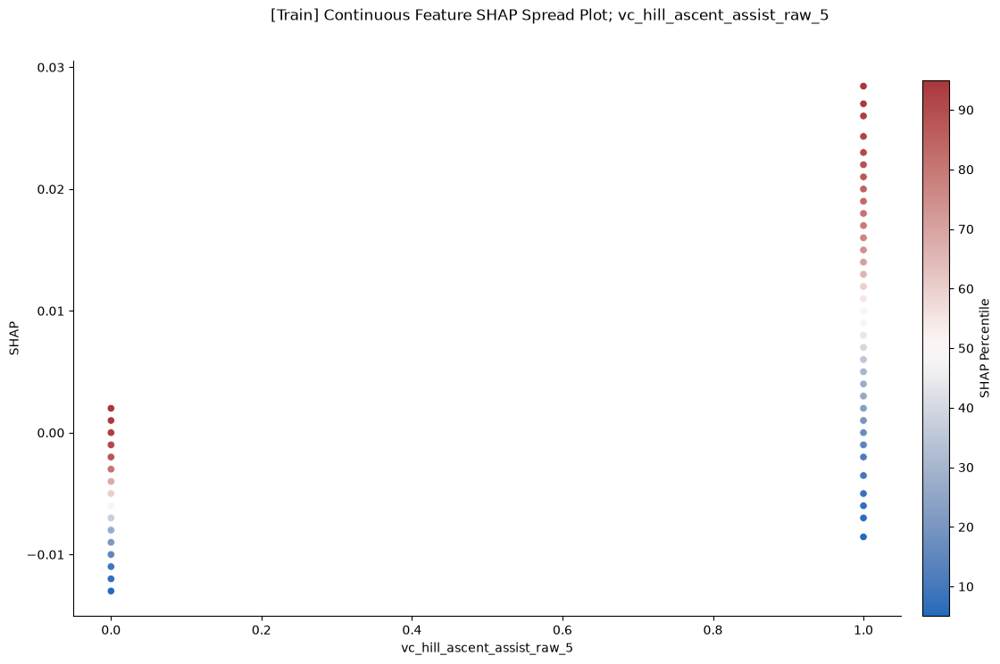

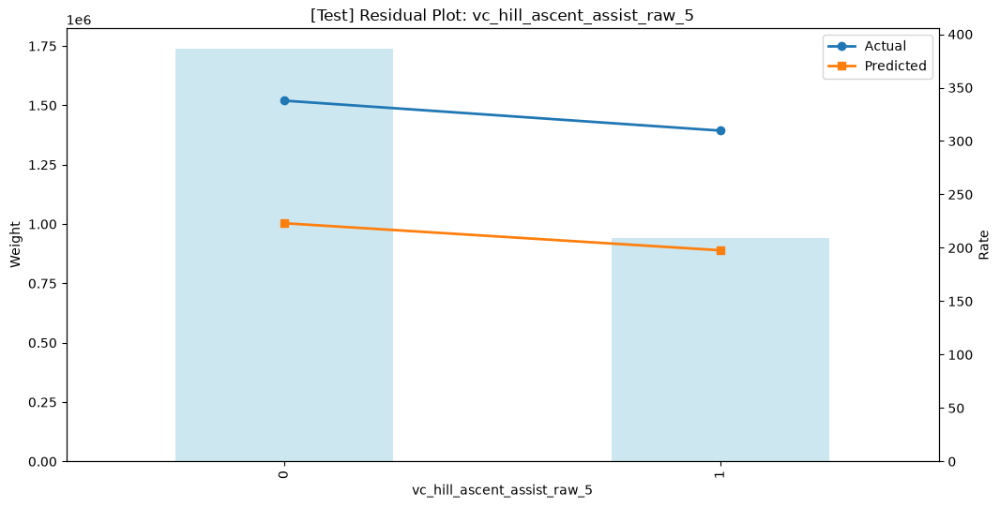

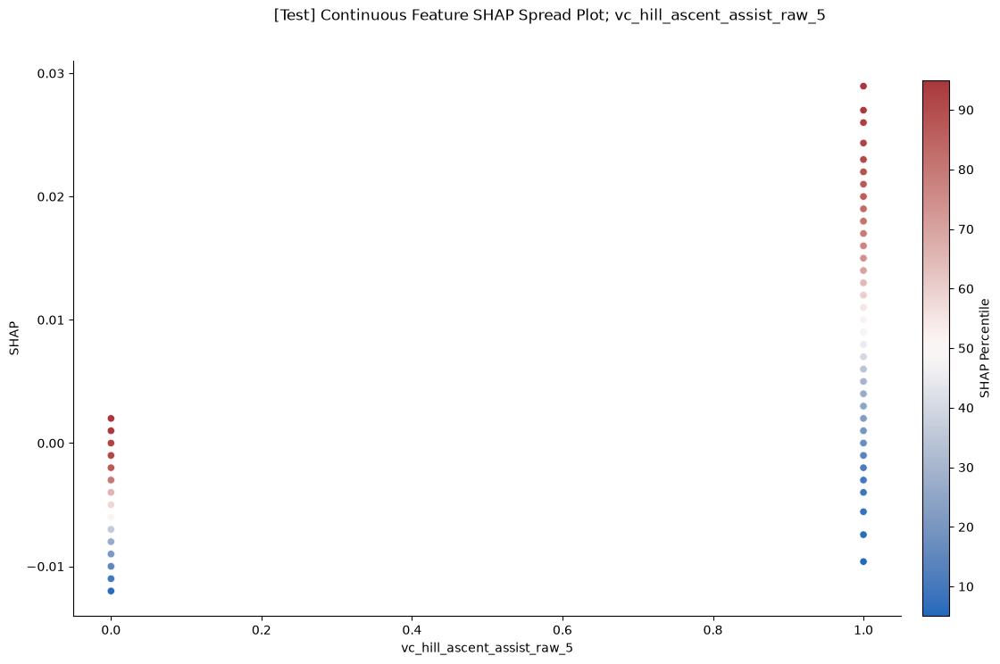


FEATURE: vc_camera_raw_0


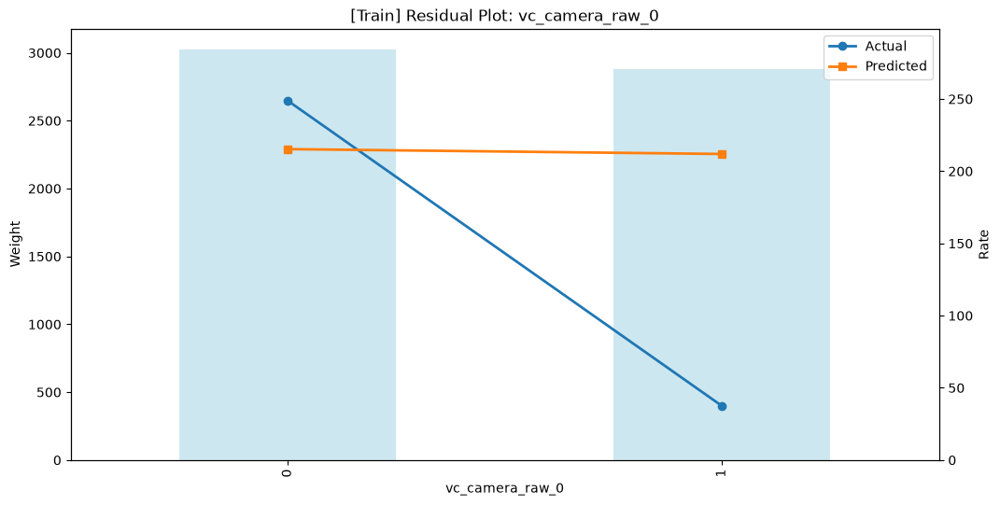

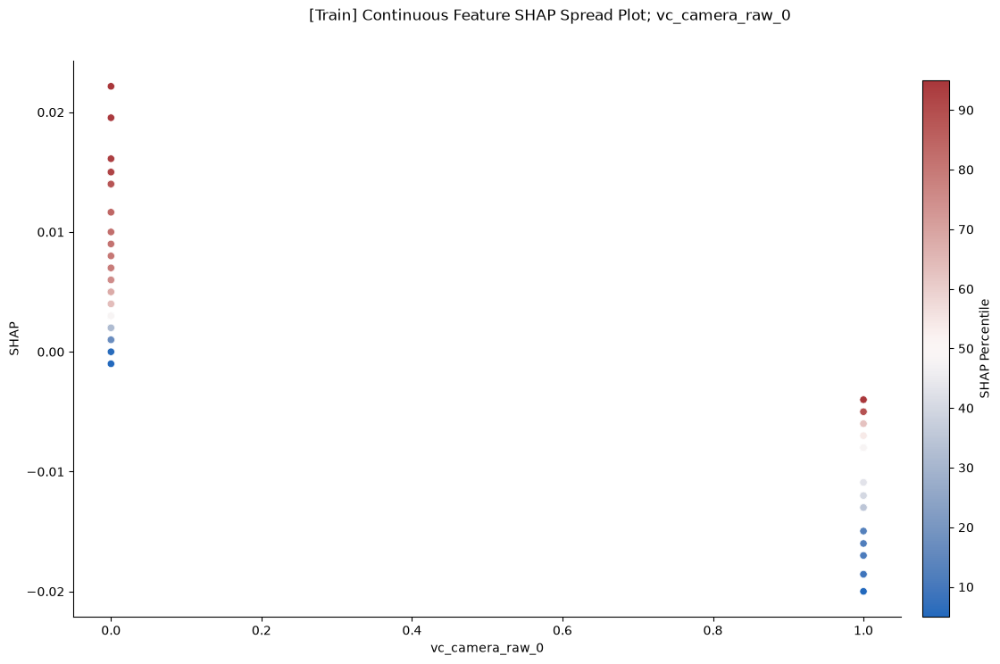

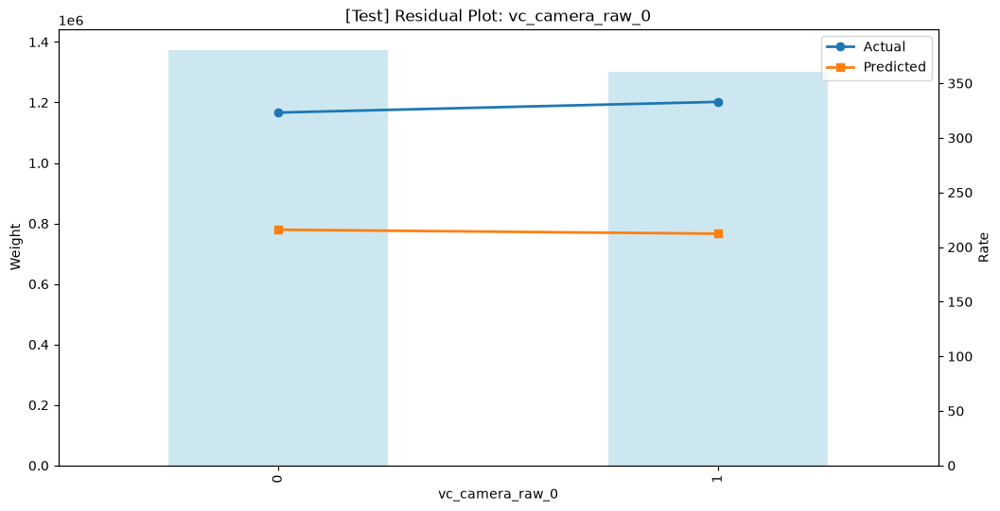

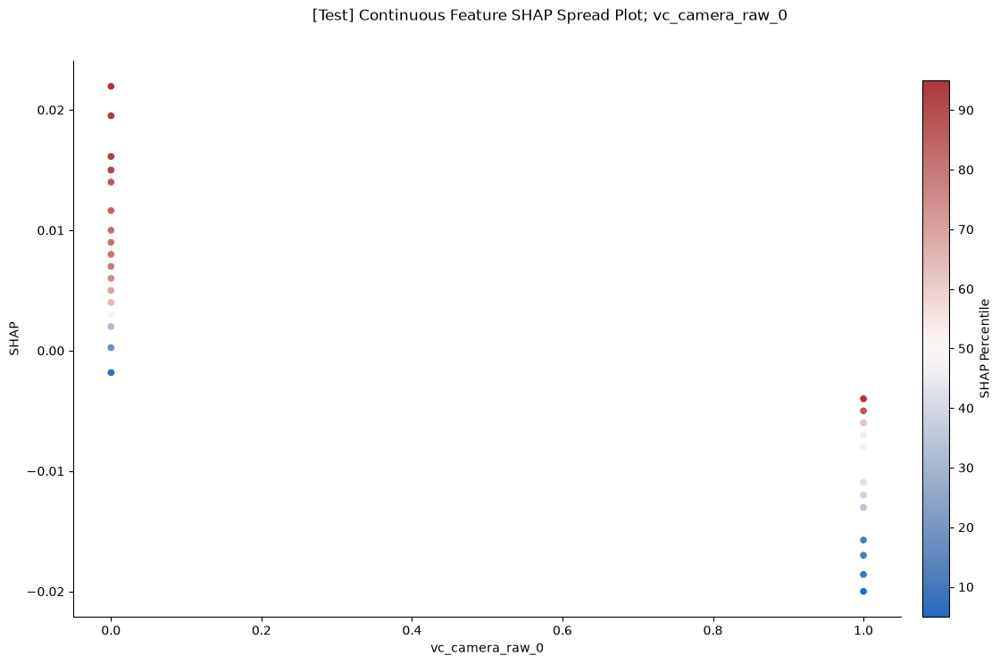


FEATURE: vc_power_sunroof_raw_3


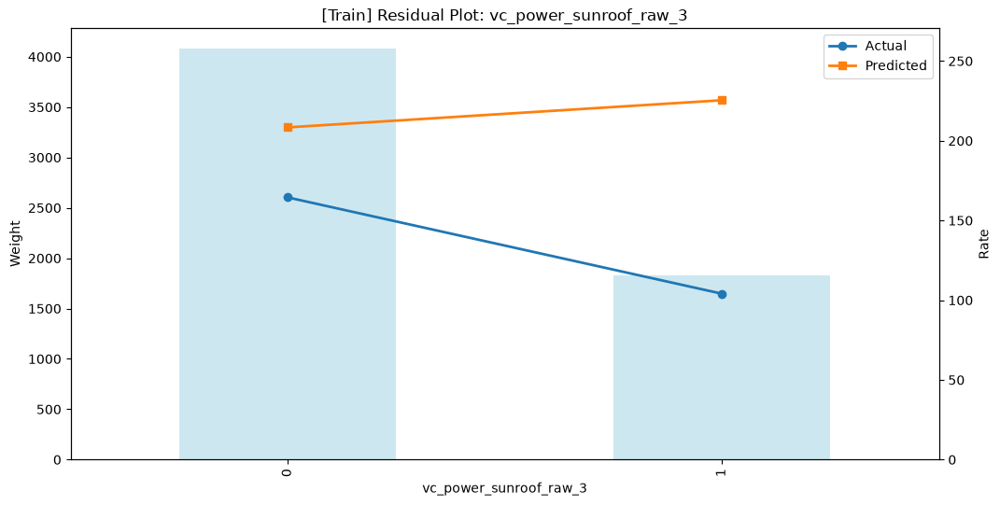

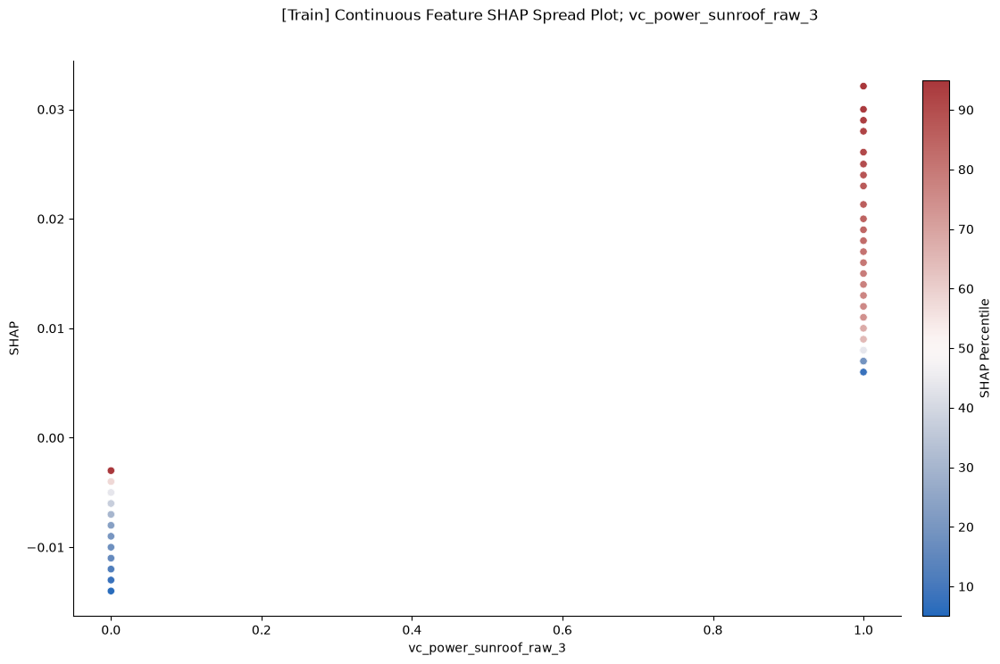

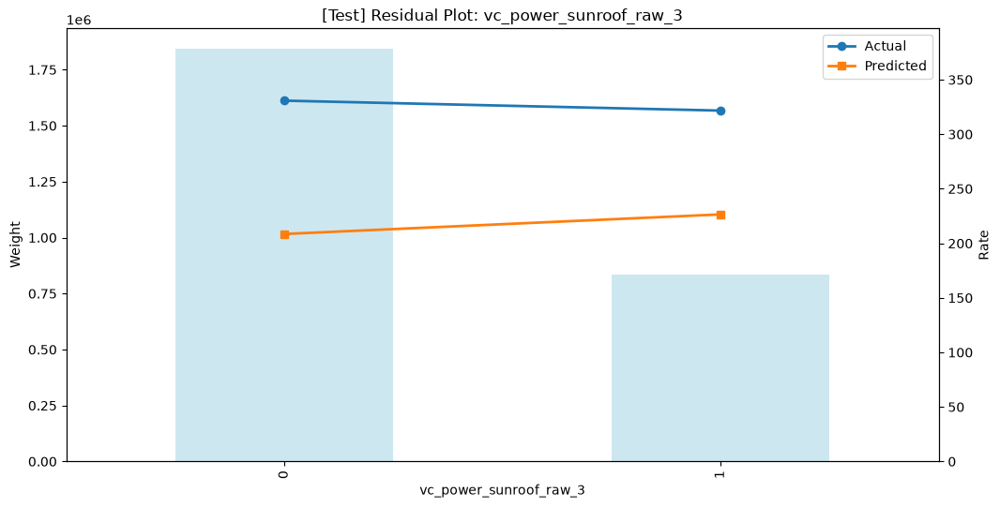

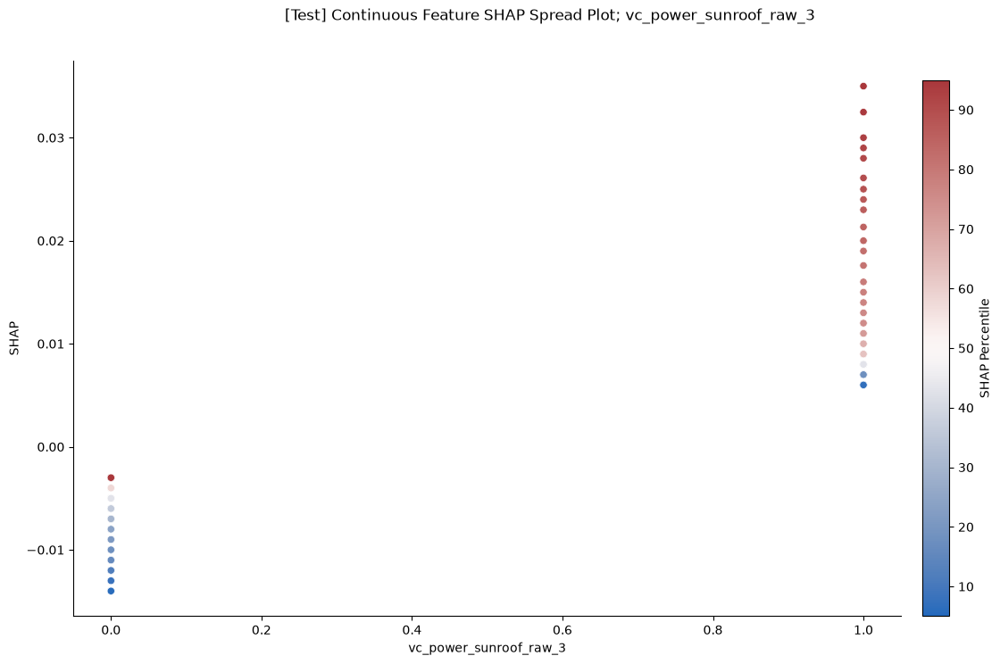


FEATURE: vc_transmission_type_automatic_ind


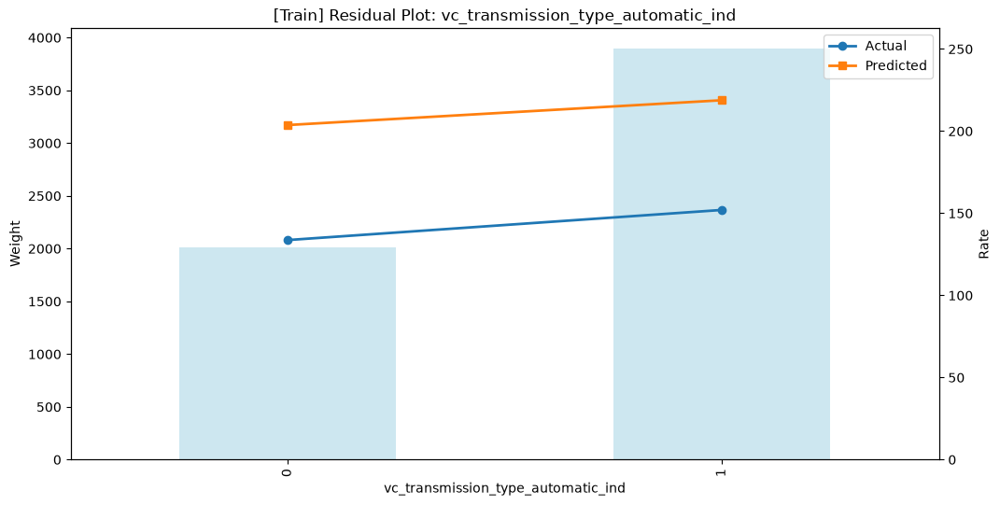

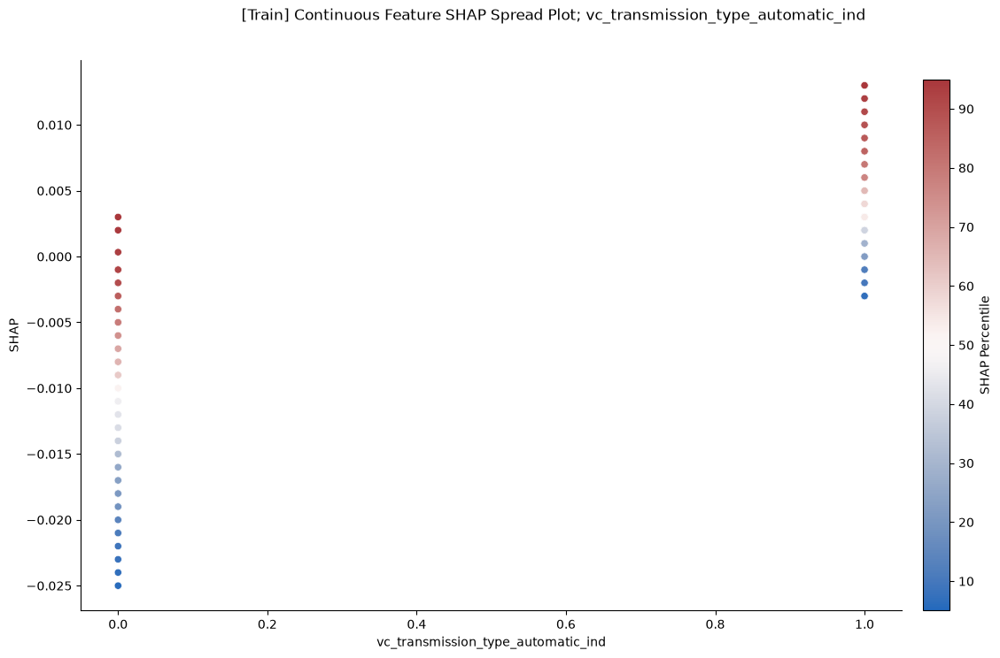

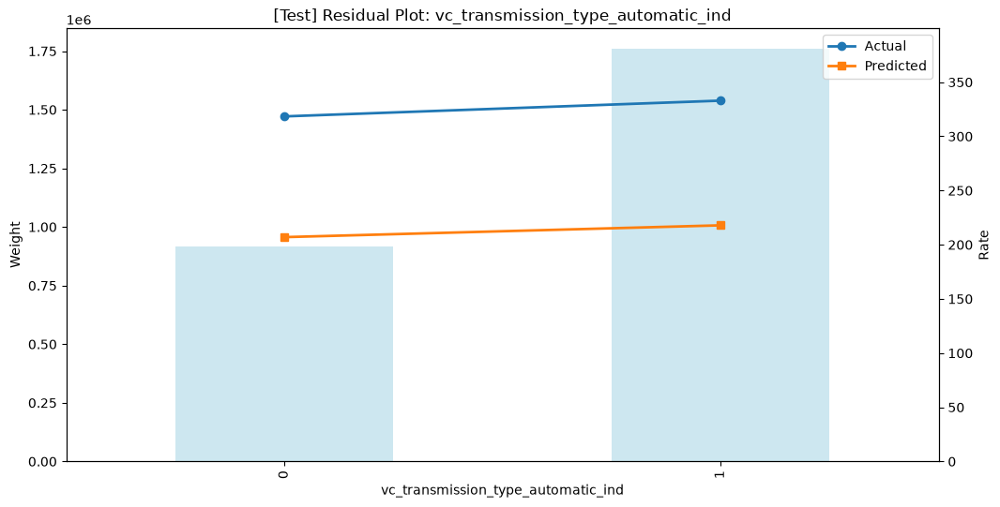

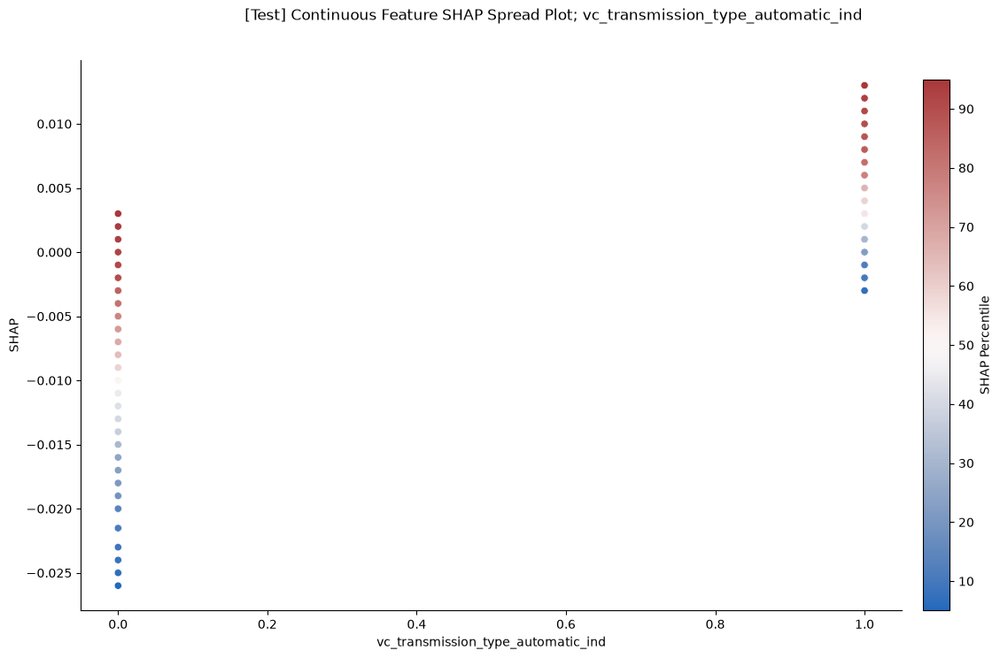


FEATURE: vc_lane_keeping_assistance_raw


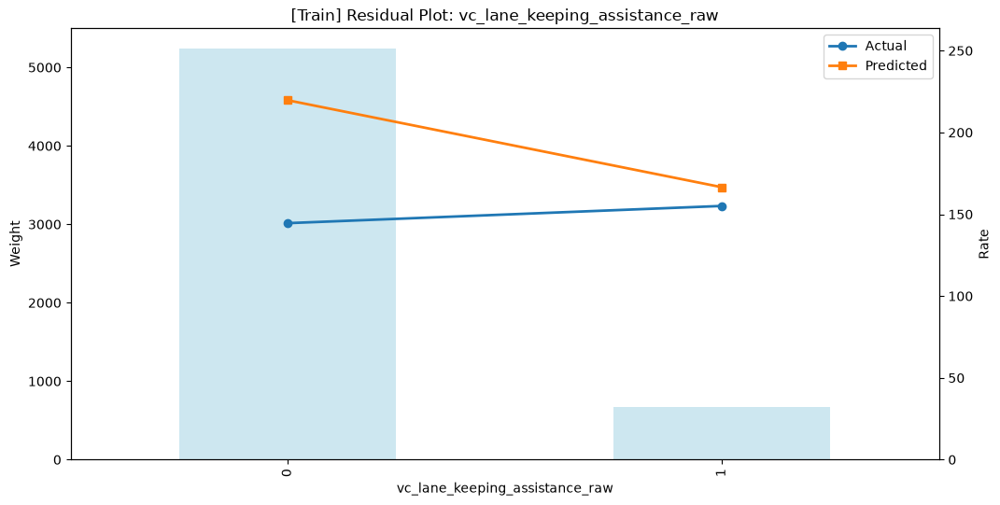

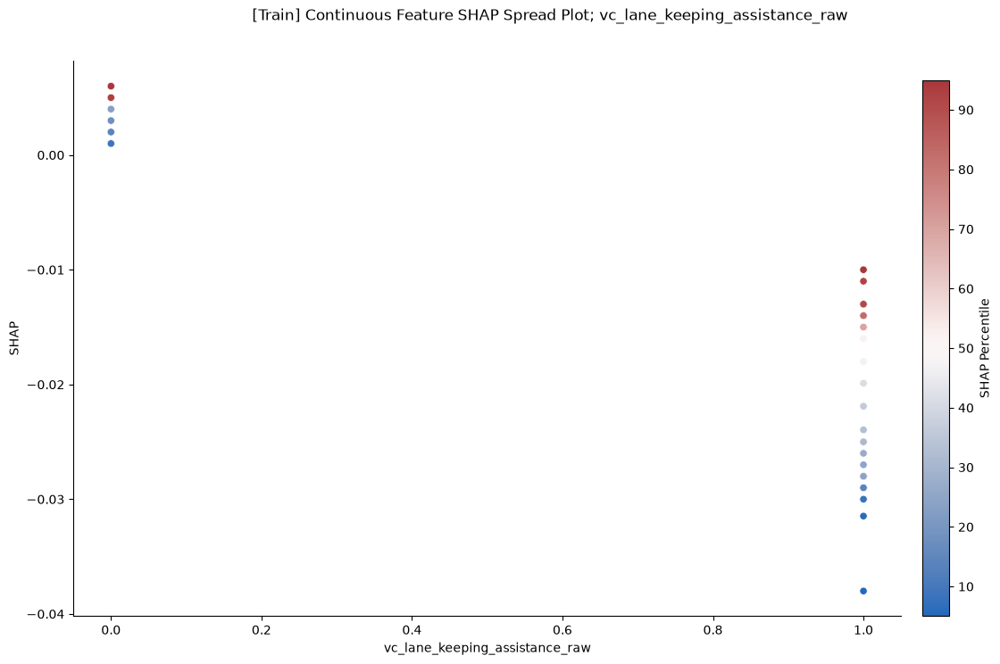

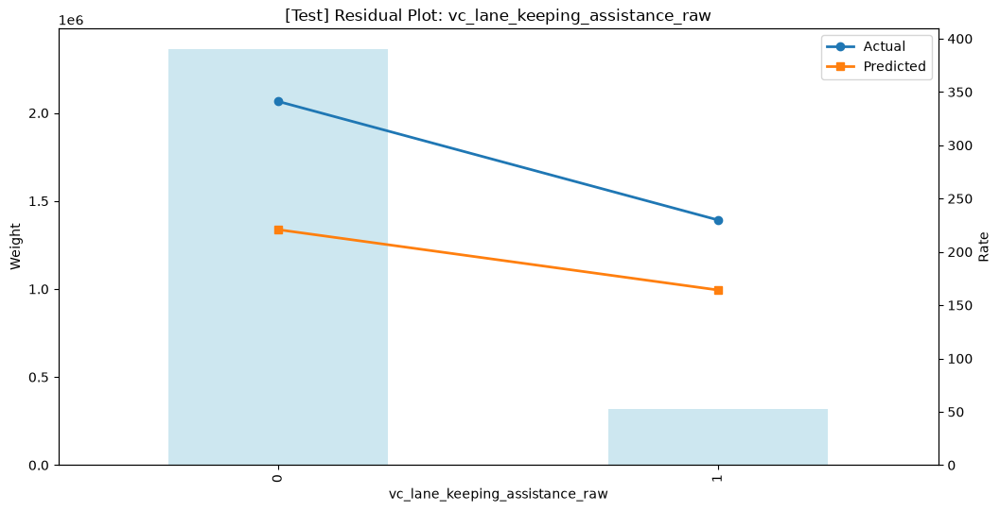

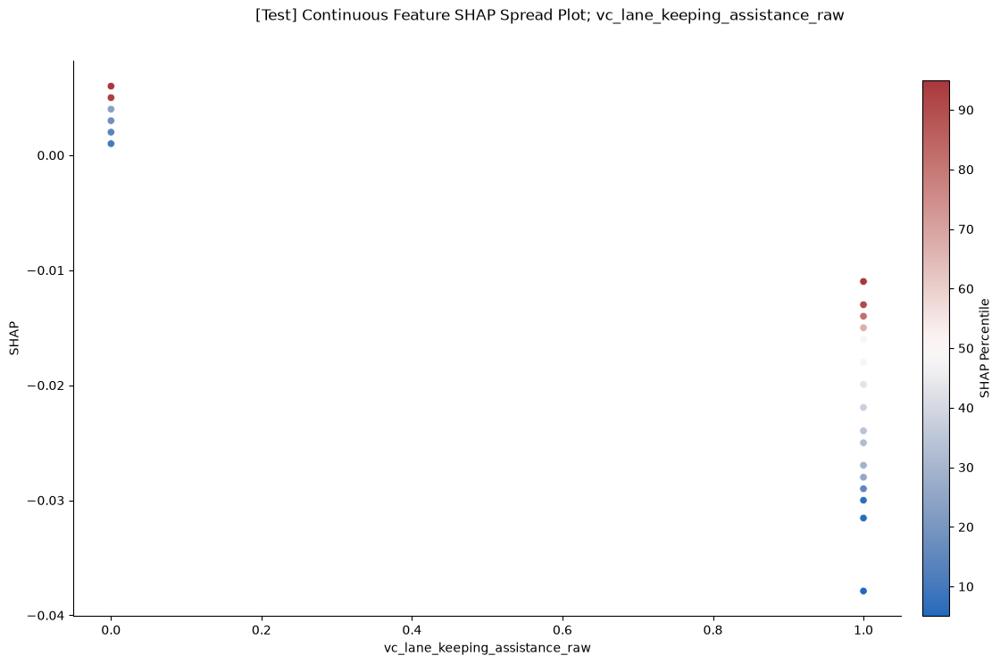


FEATURE: vc_tinted_windows_raw_5


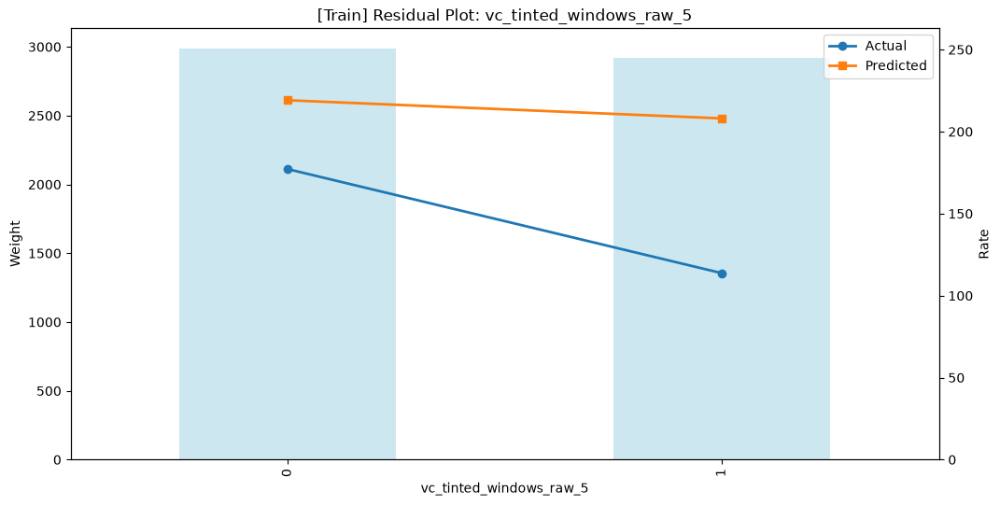

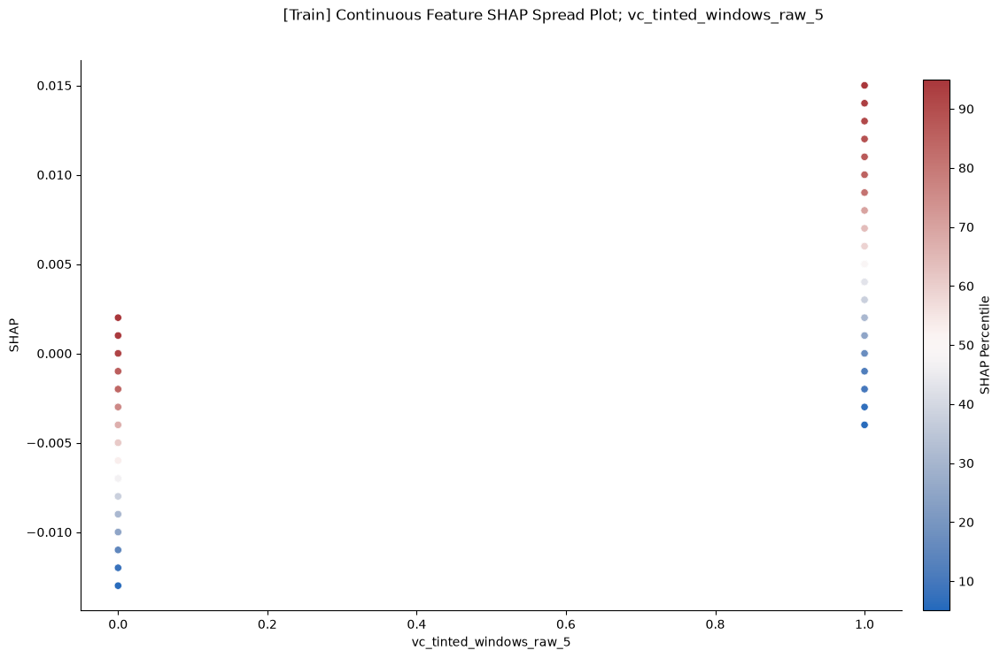

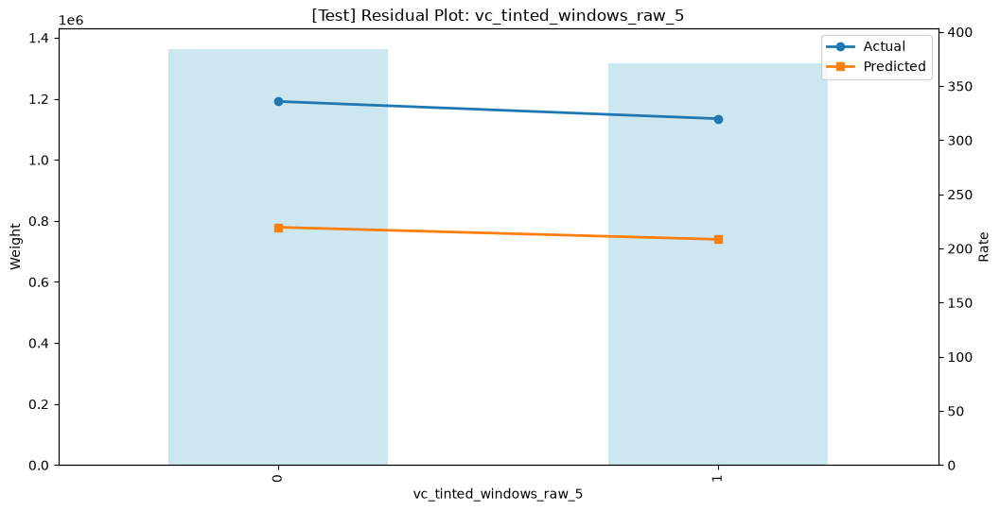

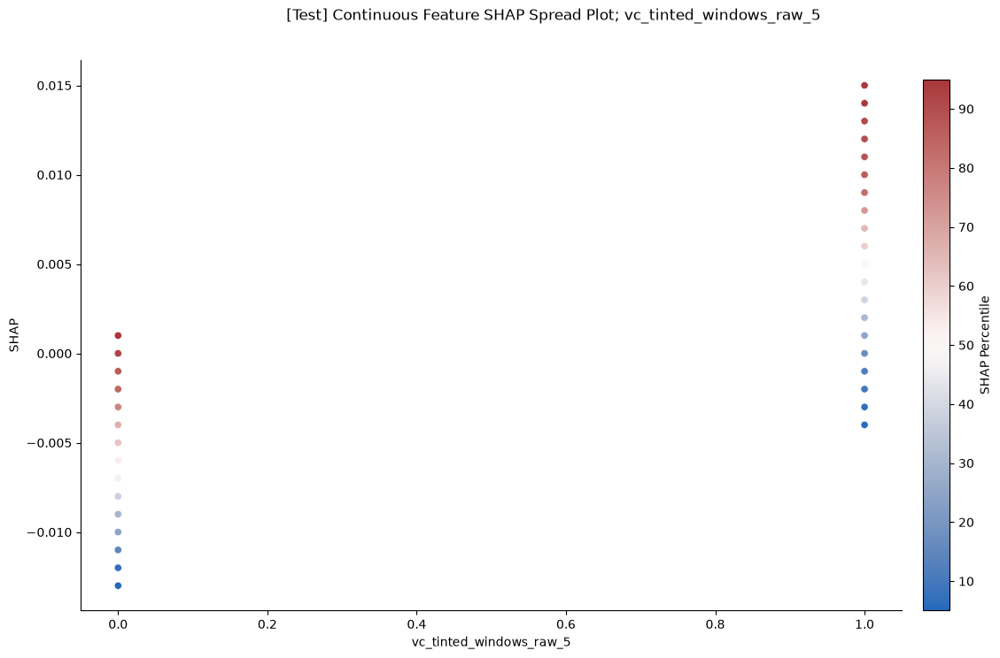


FEATURE: vc_drive_type_rwd_ind


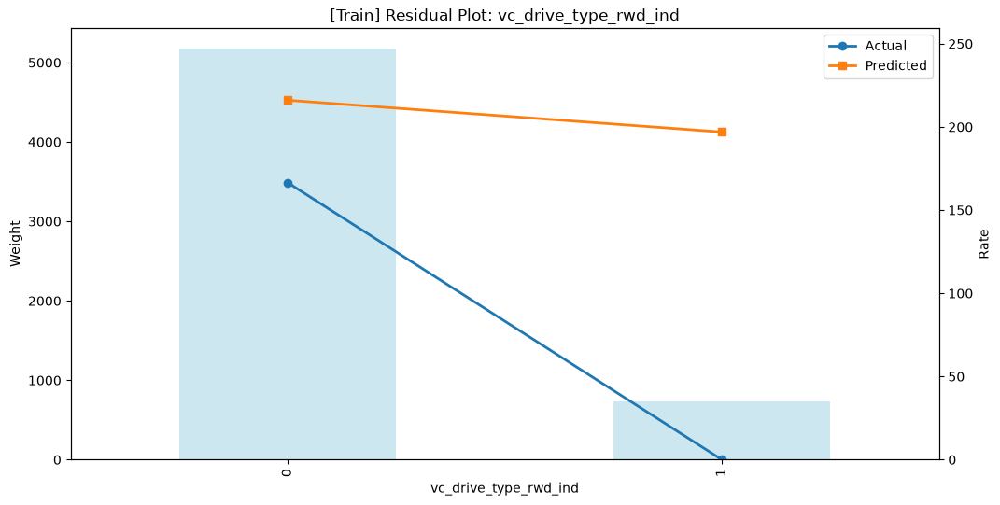

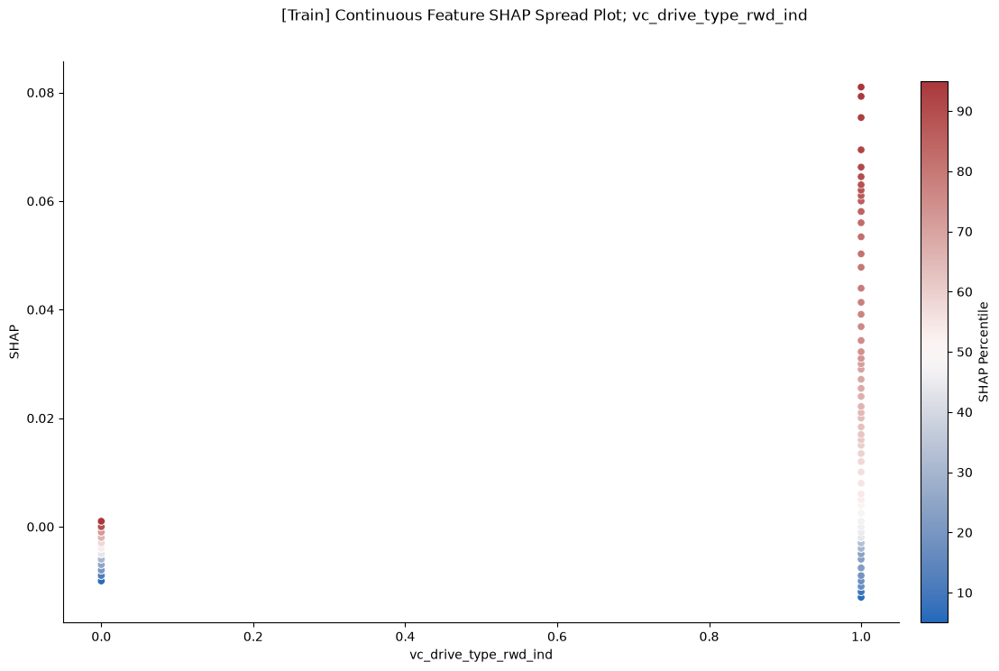

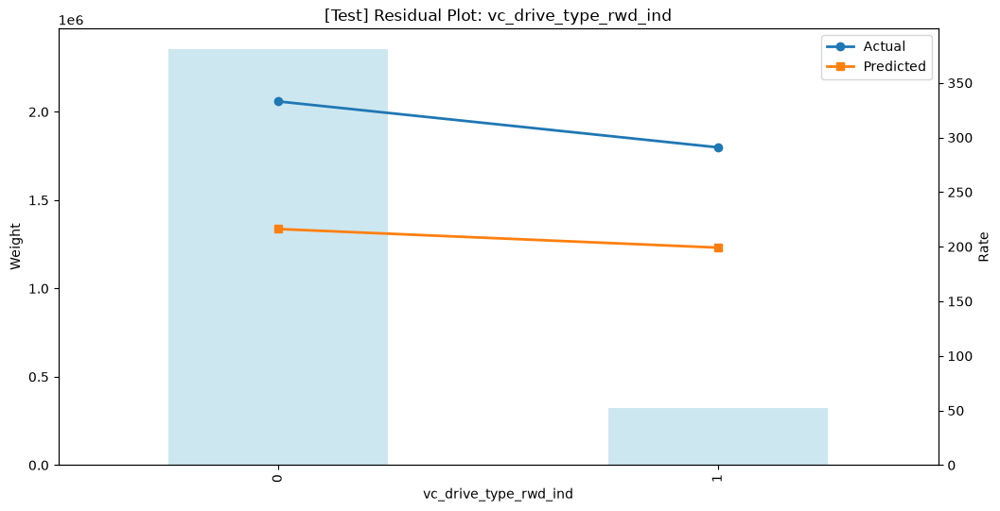

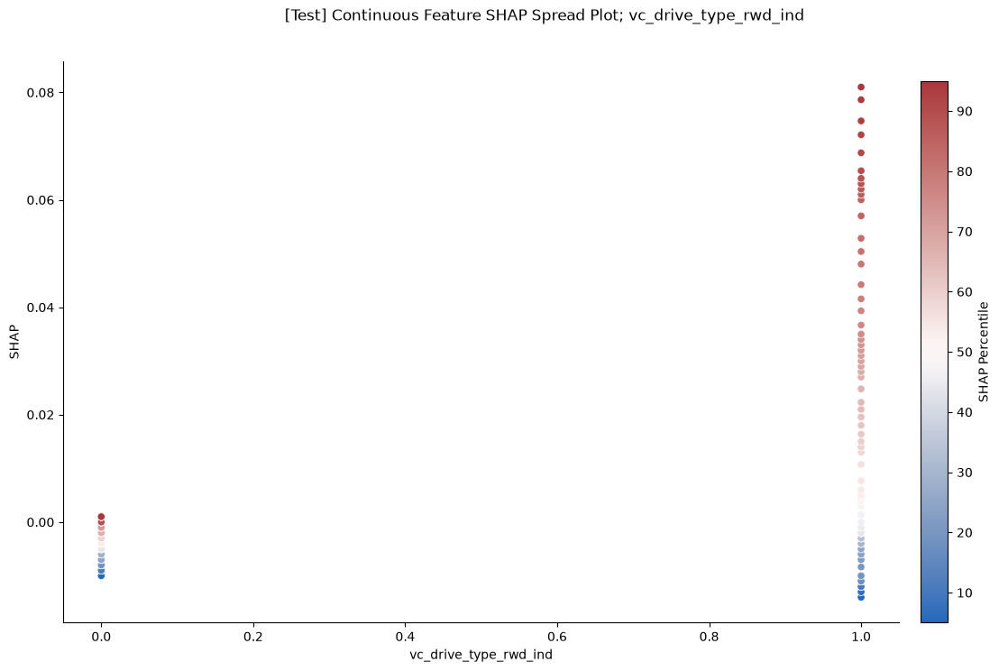


FEATURE: vc_seating_rows_raw


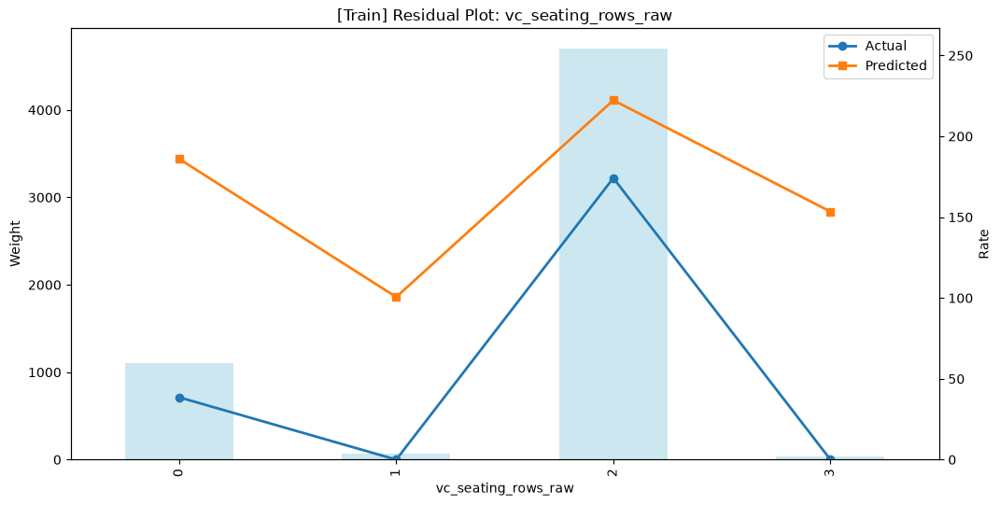

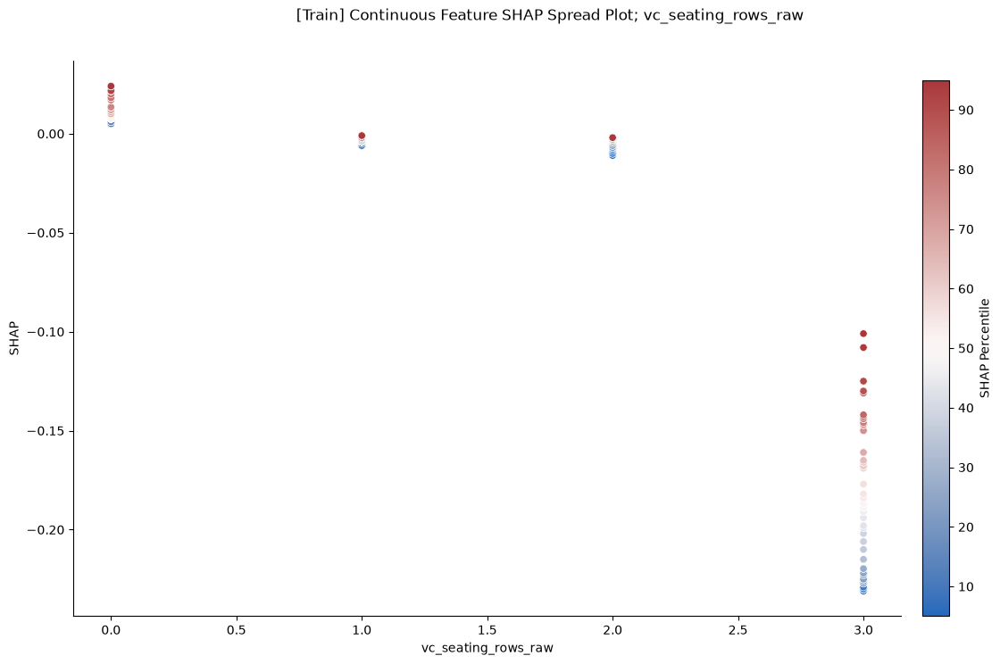

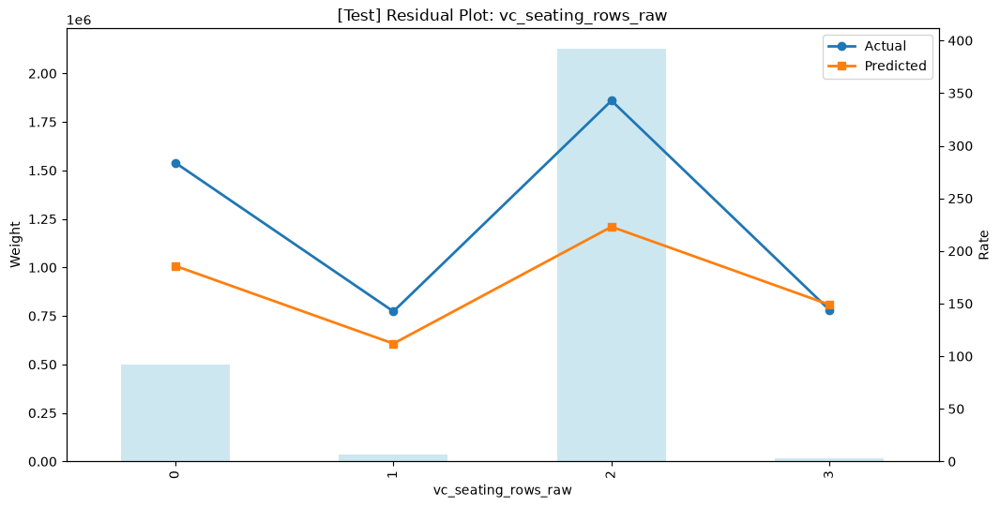

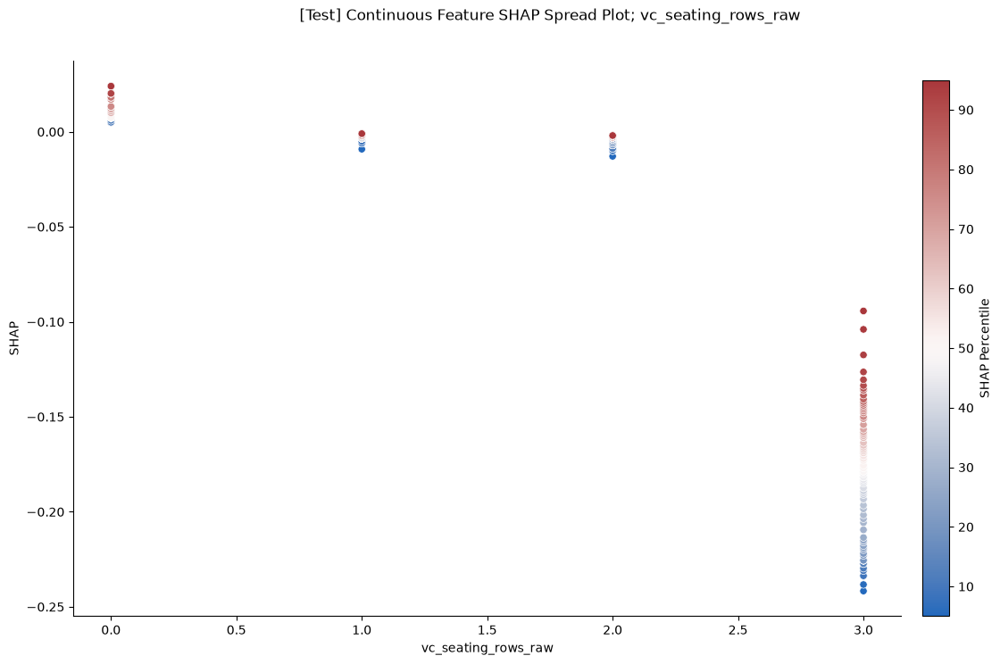


FEATURE: vc_remote_engine_start_raw_0


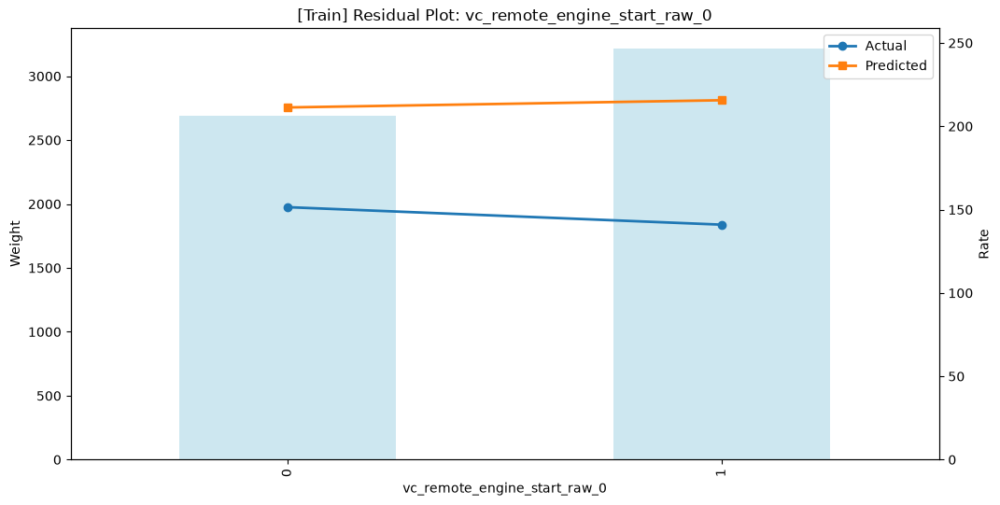

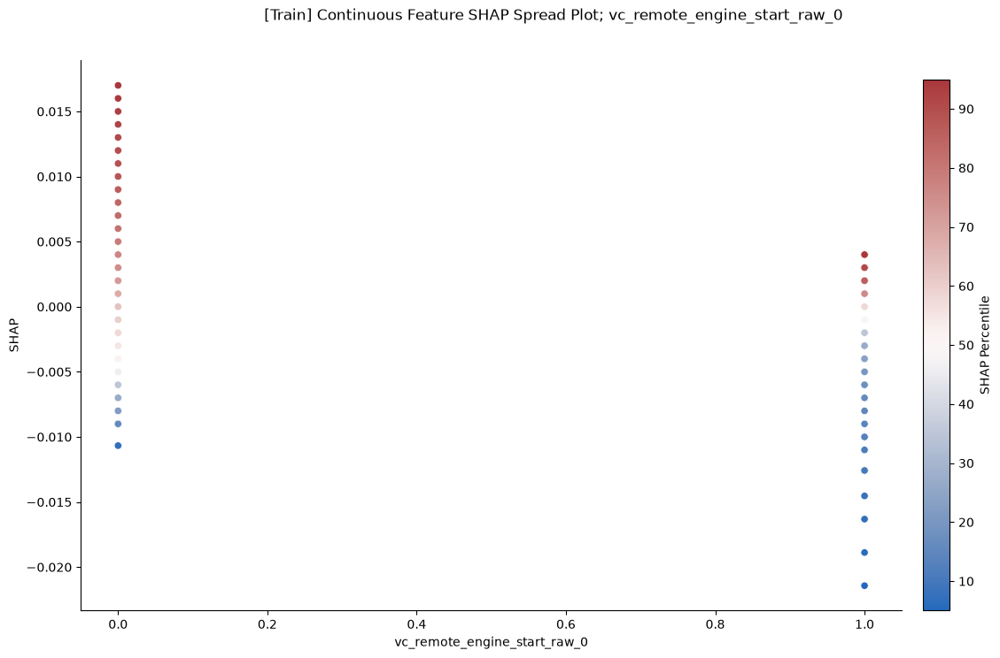

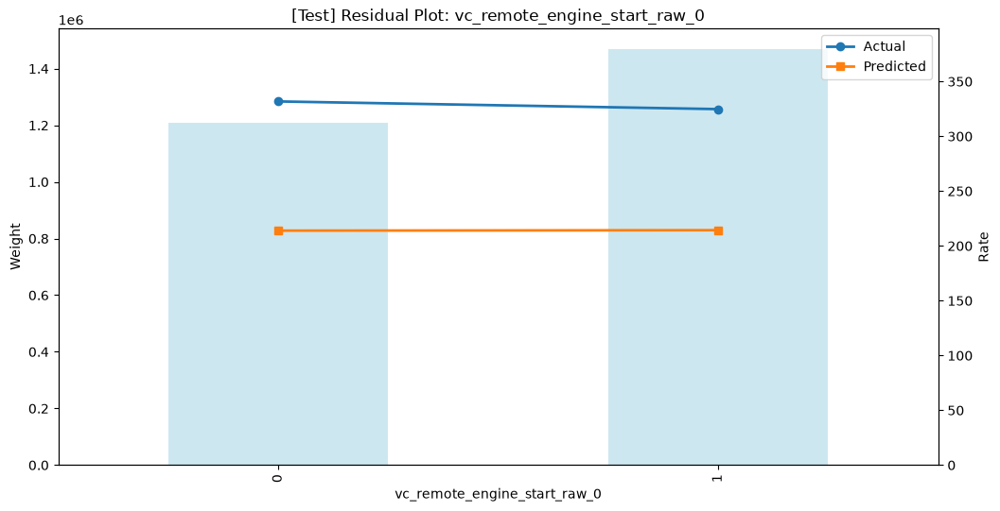

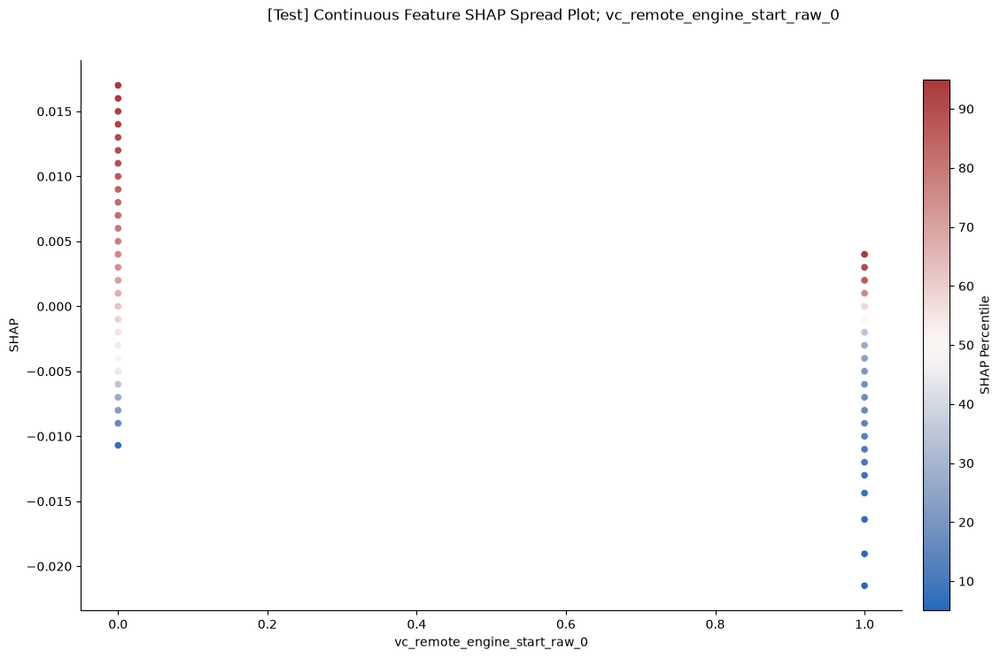


[OK] Displayed 155 plots


In [16]:
from IPython.display import Image, display
print("\n" + "="*60)
print("DISPLAYING ALL PLOTS")
print("="*60)
for f in features:
    if f not in plots_by_feature or not plots_by_feature[f]:
        continue
    print("\n" + "="*60)
    print(f"FEATURE: {f}")
    print("="*60)
    for plot_path in plots_by_feature[f]:
        if Path(plot_path).exists():
            display(Image(filename=plot_path))
        else:
            print(f"WARNING: {plot_path} not found")
print(f"\n[OK] Displayed {sum(len(v) for v in plots_by_feature.values())} plots")

In [17]:
summary["features"] = features
summary["top_n"] = top_n
summary_file = f"{output_base}/results/07_analysis_summary.yaml"
with open(summary_file, "w") as f:
    yaml.dump(summary, f)
print(f"\nSummary: {summary_file}")


Summary: output/car_liab/v1/results/07_analysis_summary.yaml


In [18]:
print("\n" + "#"*40)
print("# STAGE 07: COMPLETE")
print("#"*40)
print(f"Plots: {summary['plots']}")


########################################
# STAGE 07: COMPLETE
########################################
Plots: 155
